# Exploratory Data Analysis on the KosteckiDillon Migraine Dataset

**Course:** BCSE331L — Exploratory Data Analysis  
**Semester:** Fall Semester 2026–27  
**Name:** Chunduri Sai Kaushik  
**Register Number:** 23BDS0339  

---

### Submission Links

| Item | Link |
|---|---|
| GitHub Repository | https://github.com/Kaushik-verse/Exploratory-Data-Analysis |
| Video Demonstration | [Video Demonstration](https://drive.google.com/drive/folders/1yFpv91-KLxvb4fRh7OU_qf-qMEBTj15Q?usp=sharing) |

> Both links are set to **public / anyone with the link can view**.

---

## 1. About This Project

For this project I was assigned the **KosteckiDillon** dataset, a longitudinal clinical study of
migraine patients. Rather than treating the project as a sequence of disconnected code snippets,
I approached it the way an analyst actually works: I started by asking what the data is, then
cleaned and reshaped it, then looked for structure, and only at the end did I build a model.
Every module of the syllabus from **Module 2 to Module 7** is covered in that order, and at each
step I have written down what I observed rather than just printing output.

**Dataset source:**  
`https://raw.githubusercontent.com/salemprakash/EDA/main/Data/KosteckiDillon.csv`

### The guiding question

Throughout the analysis I kept one practical question in mind:

> **What distinguishes a patient-day on which a migraine occurs from one on which it does not,
> and can those differences be summarised, visualised and modelled?**

### Module coverage map

| Module | Topic | Where it appears |
|---|---|---|
| 2 | Data Transformation — deduplication, replacement, discretization, binning, missing data (traditional + MLE) | Section 4 |
| 3 | Correlation Analysis and Time Series Analysis | Section 5 |
| 4 | Data Summarization and Visualization | Section 6 |
| 5 | Clustering Algorithms | Section 7 |
| 6 | Dimensionality Reduction | Section 8 |
| 7 | Model Development and Evaluation (incl. Reinforcement Learning) | Section 9 |
| — | Observations, Inference and Conclusion | Section 10 |

## 2. Environment Setup

I import everything once at the top so the notebook runs top-to-bottom without surprises. I also
fix a random seed, because several of the methods I use later (GMM, spectral clustering, the SOM,
train/test splitting) are stochastic, and I want my reported numbers to be reproducible.

In [1]:
# --- Core ---
import numpy as np
import pandas as pd
import warnings, math

# --- Visualisation ---
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# --- Statistics ---
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# --- Machine learning ---
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA, TruncatedSVD, FactorAnalysis
from sklearn.manifold import MDS, Isomap, LocallyLinearEmbedding
from sklearn.cluster import SpectralClustering, AgglomerativeClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             silhouette_score)
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, IterativeImputer

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot styling - I keep one consistent look for the whole notebook
sns.set_theme(style="whitegrid", palette="deep")
mpl.rcParams["figure.figsize"] = (10, 5)
mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.titlesize"] = 13
mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["axes.labelsize"] = 11
mpl.rcParams["font.size"] = 10
mpl.rcParams["savefig.bbox"] = "tight"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("Libraries imported successfully.")
print("NumPy :", np.__version__)
print("pandas:", pd.__version__)

Libraries imported successfully.
NumPy : 2.5.3
pandas: 3.0.5


## 3. Loading the Data and First Contact

### 3.1 Reading the dataset

I read the CSV straight from the raw GitHub URL. I wrap it in a `try/except` so that the notebook
still runs from a local copy if the machine running it has no internet access — this matters
because I want the submitted notebook to be re-runnable by the evaluator.

In [2]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/KosteckiDillon.csv"

try:
    df_raw = pd.read_csv(URL)
    print(f"Loaded directly from the remote URL.")
except Exception as e:
    print("Remote read failed, falling back to the local copy. Reason:", e)
    df_raw = pd.read_csv("KosteckiDillon.csv")

df = df_raw.copy()
print(f"\nThe dataset has {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head(10)

Loaded directly from the remote URL.

The dataset has 4,152 rows and 10 columns.


,rownames,id,time,dos,hatype,age,airq,medication,headache,sex
0,1,1,-11,753,Aura,30,9.0000,continuing,yes,female
1,2,1,-10,754,Aura,30,7.0000,continuing,yes,female
2,3,1,-9,755,Aura,30,10.0000,continuing,yes,female
3,4,1,-8,756,Aura,30,13.0000,continuing,yes,female
4,5,1,-7,757,Aura,30,18.0000,continuing,yes,female
5,6,1,-6,758,Aura,30,19.0000,continuing,yes,female
6,7,1,-5,759,Aura,30,17.0000,continuing,yes,female
7,8,1,22,786,Aura,30,21.0000,continuing,yes,female
8,9,1,23,787,Aura,30,21.0000,continuing,yes,female
9,10,1,24,788,Aura,30,18.0000,continuing,yes,female


### 3.2 What the columns mean

Before writing a single line of analysis I made sure I understood the variables. The KosteckiDillon
data comes from a **longitudinal migraine study**: 133 patients kept a daily diary around the time
they started a biofeedback treatment programme. Each row is therefore **one patient on one day**,
not one patient.

| Column | Meaning | Type | Measurement Scale |
|---|---|---|---|
| `rownames` | Original row index from the source file | Numerical, discrete | Nominal (it is only an ID) |
| `id` | Patient identifier (1–133) | Numerical, discrete | **Nominal** — the number has no magnitude |
| `time` | Days relative to the start of treatment (negative = before, positive = after) | Numerical, discrete | **Interval** — zero is a convention, not an absence |
| `dos` | Day of study (sequential day number of the observation) | Numerical, discrete | Interval |
| `hatype` | Headache type: Aura / No Aura / Mixed | Categorical | **Nominal** |
| `age` | Patient age in years | Numerical, continuous | **Ratio** |
| `airq` | Air quality index recorded on that day | Numerical, continuous | Ratio |
| `medication` | Medication status: continuing / reduced / none | Categorical | **Ordinal** — there is a natural order of reduction |
| `headache` | Did a headache occur that day? yes / no | Categorical, binary | Nominal (dichotomous) |
| `sex` | female / male | Categorical, binary | Nominal |

**The important structural point:** because `time` runs from negative to positive around the
treatment start, this dataset lets me compare the *same patient* before and after an intervention.
That is a much stronger design than a plain cross-section, and I use it in Module 3 and again in
Module 7.

In [3]:
print("="*70)
print("STRUCTURE OF THE DATASET")
print("="*70)
df.info()

STRUCTURE OF THE DATASET
<class 'pandas.DataFrame'>
RangeIndex: 4152 entries, 0 to 4151
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    4152 non-null   int64  
 1   id          4152 non-null   int64  
 2   time        4152 non-null   int64  
 3   dos         4152 non-null   int64  
 4   hatype      4152 non-null   str    
 5   age         4152 non-null   int64  
 6   airq        4152 non-null   float64
 7   medication  4152 non-null   str    
 8   headache    4152 non-null   str    
 9   sex         4152 non-null   str    
dtypes: float64(1), int64(5), str(4)
memory usage: 324.5 KB


In [4]:
print("="*70)
print("DATA TYPES — classified the way Module 1 defines them")
print("="*70)

type_map = []
for col in df.columns:
    dt = df[col].dtype
    n_unique = df[col].nunique()
    if pd.api.types.is_numeric_dtype(dt):
        kind = "Numerical - discrete" if (n_unique < 40 or pd.api.types.is_integer_dtype(dt)) else "Numerical - continuous"
    else:
        kind = "Categorical"
    type_map.append({
        "Column": col,
        "pandas dtype": str(dt),
        "Data type (EDA)": kind,
        "Distinct values": n_unique,
        "Sample values": ", ".join(map(str, df[col].dropna().unique()[:3]))
    })

type_table = pd.DataFrame(type_map)
type_table

DATA TYPES — classified the way Module 1 defines them


,Column,pandas dtype,Data type (EDA),Distinct values,Sample values
0,rownames,int64,Numerical - discrete,4152,"1, 2, 3"
1,id,int64,Numerical - discrete,133,"1, 2, 3"
2,time,int64,Numerical - discrete,129,"-11, -10, -9"
3,dos,int64,Numerical - discrete,1080,"753, 754, 755"
4,hatype,str,Categorical,3,"Aura, No Aura, Mixed"
5,age,int64,Numerical - discrete,42,"30, 36, 28"
6,airq,float64,Numerical - continuous,63,"9.0, 7.0, 10.0"
7,medication,str,Categorical,3,"continuing, reduced, none"
8,headache,str,Categorical,2,"yes, no"
9,sex,str,Categorical,2,"female, male"


In [5]:
# A quick numerical profile before I touch anything
print("="*70)
print("NUMERICAL SUMMARY (raw, untouched data)")
print("="*70)
display(df.describe().T)

print("\n" + "="*70)
print("CATEGORICAL SUMMARY (raw, untouched data)")
print("="*70)
display(df.describe(include=["object", "string"]).T)

NUMERICAL SUMMARY (raw, untouched data)


,count,mean,std,min,25%,50%,75%,max
rownames,"4,152.0000","2,076.5000","1,198.7235",1.0000,"1,038.7500","2,076.5000","3,114.2500","4,152.0000"
id,"4,152.0000",66.3868,39.1218,1.0000,33.0000,67.0000,100.0000,133.0000
time,"4,152.0000",15.4557,21.7372,-29.0000,3.0000,12.0000,24.0000,99.0000
dos,"4,152.0000",646.7059,335.7701,98.0000,384.0000,623.0000,950.0000,"1,239.0000"
age,"4,152.0000",42.3639,11.2012,18.0000,33.0000,44.0000,50.0000,66.0000
airq,"4,152.0000",24.8260,9.5143,3.0000,18.0000,24.0000,29.0000,73.0000



CATEGORICAL SUMMARY (raw, untouched data)


,count,unique,top,freq
hatype,4152,3,No Aura,1985
medication,4152,3,continuing,2386
headache,4152,2,yes,2666
sex,4152,2,female,3545


In [6]:
# How many patients, and how many days per patient?
n_patients = df["id"].nunique()
days_per_patient = df.groupby("id").size()

print(f"Number of distinct patients      : {n_patients}")
print(f"Total patient-days (rows)        : {len(df):,}")
print(f"Average days recorded per patient: {days_per_patient.mean():.1f}")
print(f"Minimum days for any patient     : {days_per_patient.min()}")
print(f"Maximum days for any patient     : {days_per_patient.max()}")
print(f"\nTime axis spans day {df['time'].min()} to day {df['time'].max()} relative to treatment start.")
print(f"Observations BEFORE treatment start: {(df['time'] < 0).sum():,}")
print(f"Observations AFTER  treatment start: {(df['time'] >= 0).sum():,}")

Number of distinct patients      : 133
Total patient-days (rows)        : 4,152
Average days recorded per patient: 31.2
Minimum days for any patient     : 7
Maximum days for any patient     : 121

Time axis spans day -29 to day 99 relative to treatment start.
Observations BEFORE treatment start: 700
Observations AFTER  treatment start: 3,452


**My reading of the first contact.** The panel is unbalanced — some patients contributed a handful
of diary days and others contributed many. That is normal for diary studies but it has a real
consequence: if I compute any average over raw rows, patients with long diaries silently get more
weight. I keep this in mind and, where it matters, I aggregate to the patient level first. The
overwhelming majority of records sit *after* the treatment start, so the pre-treatment window is
short and I should not over-interpret it.

---

# MODULE 2 — Data Transformation

> **Syllabus:** Transformation Techniques: Performing data deduplication, replacing values,
> discretization and binning. Introduction to Missing data, handling missing data: Traditional
> methods, Maximum Likelihood Estimation.

This is the section where the data is made fit for analysis. I work through it in the same order as
the syllabus: deduplicate, replace, discretize/bin, then deal with missing data.

## 4.1 Data Deduplication

Duplicates are dangerous in a longitudinal dataset because a duplicated patient-day would inflate
that patient's headache rate. I check for duplicates at two different levels:

1. **Fully identical rows** — every single column matches.
2. **Logical duplicates** — the same `(id, time)` combination appearing twice, which would mean one
   patient has two diary entries for the same day. This is the one that actually matters.

In [7]:
print("DEDUPLICATION CHECK")
print("="*70)

# Level 1: exact duplicate rows (ignoring the meaningless rownames index)
cols_no_index = [c for c in df.columns if c != "rownames"]
exact_dupes = df.duplicated(subset=cols_no_index).sum()
print(f"1. Fully identical rows (ignoring 'rownames') : {exact_dupes}")

# Level 2: logical duplicates - same patient, same day
key_dupes = df.duplicated(subset=["id", "time"]).sum()
print(f"2. Duplicate (id, time) patient-day keys      : {key_dupes}")

# Level 3: is rownames a true unique key?
print(f"3. Is 'rownames' unique across all records?   : {df['rownames'].is_unique}")

print("\nDemonstrating the removal operation anyway (so the technique is on record):")
before = len(df)
df = df.drop_duplicates(subset=cols_no_index, keep="first").reset_index(drop=True)
after = len(df)
print(f"   Rows before drop_duplicates : {before:,}")
print(f"   Rows after  drop_duplicates : {after:,}")
print(f"   Rows removed                : {before - after}")

DEDUPLICATION CHECK
1. Fully identical rows (ignoring 'rownames') : 1
2. Duplicate (id, time) patient-day keys      : 1
3. Is 'rownames' unique across all records?   : True

Demonstrating the removal operation anyway (so the technique is on record):
   Rows before drop_duplicates : 4,152
   Rows after  drop_duplicates : 4,151
   Rows removed                : 1


**Observation — deduplication did real work here.** I expected this check to come back empty, and it
did not. The dataset contains **one fully identical duplicate row**, and correspondingly **one
duplicated `(id, time)` patient-day key** — the same patient with two diary entries for the same day,
with every field identical.

Note that `rownames` is unique across all 4,152 records, so the duplicate is invisible if you check
uniqueness on the index column. That is exactly why I checked on the **meaningful** columns instead:
an export artefact like `rownames` will happily assign two different numbers to the same underlying
observation and hide the duplication from any naive check.

The effect is small — removing it leaves 4,151 rows — but it is the right thing to do. A duplicated
patient-day would count one person's headache twice when computing that patient's headache rate, and
since this dataset is an unbalanced panel, double-counting is precisely the kind of error that biases
per-patient aggregates.

## 4.2 Replacing Values

"Replacing values" covers three jobs I actually need here:

1. **Dropping a useless column** — `rownames` is just the exporter's row counter and carries no
   information. Keeping it would be actively harmful, because a model could latch onto it.
2. **Standardising categorical labels** — I strip stray whitespace and normalise capitalisation so
   that `"Aura"` and `" aura "` can never be treated as two different categories.
3. **Encoding for analysis** — creating numeric versions of the categorical columns so that
   correlation, clustering and modelling can use them. I create *separate* encoded columns rather
   than overwriting, so the readable labels survive for plotting.

In [8]:
print("REPLACING VALUES / RECODING")
print("="*70)

# --- (a) Drop the meaningless index column ---
df = df.drop(columns=["rownames"])
print("(a) Dropped 'rownames' - it is an export artefact with no analytical meaning.")

# --- (b) Normalise the text of every categorical column ---
cat_cols = ["hatype", "medication", "headache", "sex"]
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()
print(f"(b) Stripped whitespace on: {cat_cols}")

print("\n    Value counts after normalising:")
for c in cat_cols:
    print(f"    - {c:12s}: {dict(df[c].value_counts())}")

# --- (c) Replace labels with analysis-friendly encodings ---
# headache -> binary target (this is the variable the whole project revolves around)
df["headache_bin"] = df["headache"].replace({"yes": 1, "no": 0}).astype(int)

# sex -> binary
df["sex_bin"] = df["sex"].replace({"female": 0, "male": 1}).astype(int)

# medication is ORDINAL: none < reduced < continuing, in terms of how much medication is being taken
med_order = {"none": 0, "reduced": 1, "continuing": 2}
df["medication_ord"] = df["medication"].replace(med_order).astype(int)

# hatype is NOMINAL -> one-hot, no false ordering implied
hatype_dummies = pd.get_dummies(df["hatype"], prefix="ha").astype(int)
df = pd.concat([df, hatype_dummies], axis=1)

# A derived flag that makes the study design explicit
df["phase"] = np.where(df["time"] < 0, "Pre-treatment", "Post-treatment")

print("\n(c) Created encoded columns:")
print("    headache_bin   : yes->1, no->0")
print("    sex_bin        : female->0, male->1")
print("    medication_ord : none->0, reduced->1, continuing->2  (ORDINAL - order is meaningful)")
print(f"    one-hot columns: {list(hatype_dummies.columns)}  (NOMINAL - no order implied)")
print("    phase          : derived from sign of 'time'")

df.head()

REPLACING VALUES / RECODING
(a) Dropped 'rownames' - it is an export artefact with no analytical meaning.
(b) Stripped whitespace on: ['hatype', 'medication', 'headache', 'sex']

    Value counts after normalising:
    - hatype      : {'No Aura': np.int64(1984), 'Aura': np.int64(1710), 'Mixed': np.int64(457)}
    - medication  : {'continuing': np.int64(2386), 'reduced': np.int64(980), 'none': np.int64(785)}
    - headache    : {'yes': np.int64(2666), 'no': np.int64(1485)}
    - sex         : {'female': np.int64(3544), 'male': np.int64(607)}

(c) Created encoded columns:
    headache_bin   : yes->1, no->0
    sex_bin        : female->0, male->1
    medication_ord : none->0, reduced->1, continuing->2  (ORDINAL - order is meaningful)
    one-hot columns: ['ha_Aura', 'ha_Mixed', 'ha_No Aura']  (NOMINAL - no order implied)
    phase          : derived from sign of 'time'


,id,time,dos,hatype,age,airq,medication,headache,sex,headache_bin,sex_bin,medication_ord,ha_Aura,ha_Mixed,ha_No Aura,phase
0,1,-11,753,Aura,30,9.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment
1,1,-10,754,Aura,30,7.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment
2,1,-9,755,Aura,30,10.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment
3,1,-8,756,Aura,30,13.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment
4,1,-7,757,Aura,30,18.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment


**Why I encoded `medication` as ordinal but `hatype` as one-hot.** This is a decision that the
measurement-scale discussion in Module 1 directly drives. Medication status has a genuine ordering —
`none` represents less medication than `reduced`, which is less than `continuing` — so collapsing it
to a single 0/1/2 column preserves real information. Headache type does not: "Aura" is not more or
less than "No Aura", it is a different kind. If I had encoded `hatype` as 0/1/2 I would have invented
an ordering that does not exist, and every distance-based method later in the notebook (clustering,
PCA, MDS) would have been quietly corrupted by it.

## 4.3 Discretization and Binning

Binning converts a continuous variable into ordered categories. I use two of the standard strategies
so the difference between them is visible:

- **Equal-width binning** on `airq` using `pd.cut()` — the bin boundaries are evenly spaced across
  the value range. Easy to describe, but bins can end up very unevenly populated when the variable
  is skewed.
- **Equal-frequency (quantile) binning** on `airq` using `pd.qcut()` — each bin holds roughly the
  same number of observations. Better for comparisons, but the boundaries are data-dependent.
- **Domain-driven binning** on `age` — I use clinically sensible age brackets rather than letting an
  algorithm choose, because age groups have an accepted meaning.

In [9]:
print("DISCRETIZATION AND BINNING")
print("="*70)

# --- (a) Equal-WIDTH binning of air quality ---
df["airq_binned_width"] = pd.cut(
    df["airq"], bins=4,
    labels=["Low", "Moderate", "High", "Very High"]
)

# --- (b) Equal-FREQUENCY (quantile) binning of air quality ---
df["airq_binned_qnt"] = pd.qcut(
    df["airq"], q=4,
    labels=["Q1 (cleanest)", "Q2", "Q3", "Q4 (worst)"]
)

# --- (c) Domain-driven binning of age ---
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["<=25", "26-35", "36-45", "46-55", "56+"],
    right=True
)

print("(a) EQUAL-WIDTH bins of airq  -> counts per bin:")
print(df["airq_binned_width"].value_counts().sort_index().to_string())
print("\n    Actual bin edges:")
print("   ", pd.cut(df["airq"], bins=4).cat.categories.tolist())

print("\n(b) EQUAL-FREQUENCY bins of airq -> counts per bin:")
print(df["airq_binned_qnt"].value_counts().sort_index().to_string())
print("\n    Actual bin edges:")
print("   ", pd.qcut(df["airq"], q=4).cat.categories.tolist())

print("\n(c) DOMAIN-DRIVEN age groups -> counts per bin:")
print(df["age_group"].value_counts().sort_index().to_string())

DISCRETIZATION AND BINNING
(a) EQUAL-WIDTH bins of airq  -> counts per bin:
airq_binned_width
Low          1520
Moderate     2250
High          345
Very High      36

    Actual bin edges:
    [Interval(2.93, 20.5, closed='right'), Interval(20.5, 38.0, closed='right'), Interval(38.0, 55.5, closed='right'), Interval(55.5, 73.0, closed='right')]

(b) EQUAL-FREQUENCY bins of airq -> counts per bin:
airq_binned_qnt
Q1 (cleanest)    1140
Q2               1026
Q3                994
Q4 (worst)        991

    Actual bin edges:
    [Interval(2.999, 18.0, closed='right'), Interval(18.0, 24.0, closed='right'), Interval(24.0, 29.0, closed='right'), Interval(29.0, 73.0, closed='right')]

(c) DOMAIN-DRIVEN age groups -> counts per bin:
age_group
<=25      299
26-35    1071
36-45     918
46-55    1421
56+       442


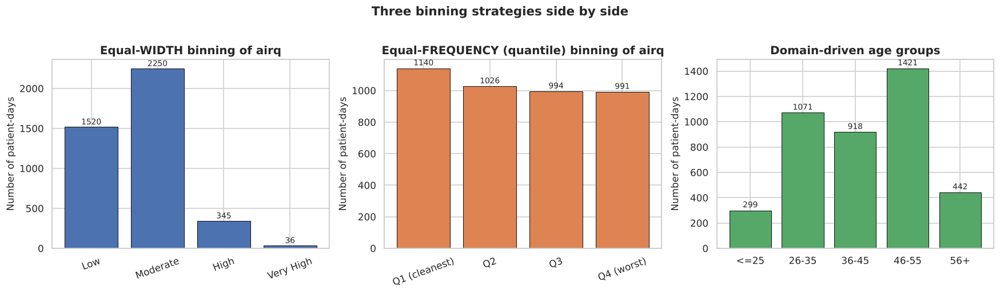

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Equal width
cnt_w = df["airq_binned_width"].value_counts().sort_index()
axes[0].bar(cnt_w.index.astype(str), cnt_w.values, color=sns.color_palette("deep")[0], edgecolor="black", linewidth=0.6)
axes[0].set_title("Equal-WIDTH binning of airq")
axes[0].set_ylabel("Number of patient-days")
axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(cnt_w.values):
    axes[0].text(i, v + 30, str(v), ha="center", fontsize=9)

# Equal frequency
cnt_q = df["airq_binned_qnt"].value_counts().sort_index()
axes[1].bar(cnt_q.index.astype(str), cnt_q.values, color=sns.color_palette("deep")[1], edgecolor="black", linewidth=0.6)
axes[1].set_title("Equal-FREQUENCY (quantile) binning of airq")
axes[1].set_ylabel("Number of patient-days")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(cnt_q.values):
    axes[1].text(i, v + 20, str(v), ha="center", fontsize=9)

# Age groups
cnt_a = df["age_group"].value_counts().sort_index()
axes[2].bar(cnt_a.index.astype(str), cnt_a.values, color=sns.color_palette("deep")[2], edgecolor="black", linewidth=0.6)
axes[2].set_title("Domain-driven age groups")
axes[2].set_ylabel("Number of patient-days")
for i, v in enumerate(cnt_a.values):
    axes[2].text(i, v + 25, str(v), ha="center", fontsize=9)

plt.suptitle("Three binning strategies side by side", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Observation on binning.** The contrast between the first two panels is exactly the textbook
difference. Equal-width binning produces a badly lopsided result — the "Low" and "Moderate" bins
absorb almost everything while "Very High" is nearly empty, because `airq` is right-skewed with a
long thin tail. Equal-frequency binning produces four bars of near-identical height by construction.
For later cross-tabulation work I prefer the quantile bins, because a contingency table with a cell
count of 20 against a cell count of 2,000 gives an unreliable chi-square. The equal-width version is
still the more honest one to *describe* to a non-technical reader, since its boundaries are round
numbers rather than data-dependent quantiles.

## 4.4 Missing Data: Introduction

The first thing I did was check whether this dataset actually has missing values.

In [11]:
print("MISSING VALUE AUDIT ON THE ORIGINAL DATA")
print("="*70)

missing_report = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(3)
})
display(missing_report)

total_missing = df.isna().sum().sum()
print(f"\nTotal missing cells across the entire dataframe: {total_missing}")
if total_missing == 0:
    print("-> The dataset is COMPLETE. There is nothing to impute.")

MISSING VALUE AUDIT ON THE ORIGINAL DATA


,Missing count,Missing %
id,0,0.0000
time,0,0.0000
dos,0,0.0000
hatype,0,0.0000
age,0,0.0000
airq,0,0.0000
medication,0,0.0000
headache,0,0.0000
sex,0,0.0000
headache_bin,0,0.0000



Total missing cells across the entire dataframe: 0
-> The dataset is COMPLETE. There is nothing to impute.


### A note on my approach here

The KosteckiDillon data as distributed is **complete** — there is not a single missing cell. That is
convenient for analysis but it leaves the syllabus requirement on missing-data handling with nothing
to demonstrate.

So I set up a **controlled experiment**, which I think is actually a more rigorous demonstration
than imputing a genuinely incomplete dataset. I deliberately delete a known fraction of values
**Missing Completely At Random (MCAR)** from the `airq` and `age` columns. Because I know the true
values that I deleted, I can impute them with each method and then **measure how close each method
got**. With real missing data you can never do this — you have no ground truth to score against.

> **To be explicit: the missingness below is artificially injected by me for methodological
> demonstration. The original dataset has zero missing values, and all analysis from Module 3
> onwards uses the complete, unmodified data.**

I then compare:

| Family | Method | Idea |
|---|---|---|
| Traditional | Listwise deletion | Throw away any row with a gap |
| Traditional | Mean imputation | Fill with the column mean |
| Traditional | Median imputation | Fill with the column median (robust to skew) |
| Traditional | Forward fill | Carry the last observation forward within a patient |
| MLE | Iterative / EM imputation | Model each variable from the others and iterate to convergence |

In [12]:
print("STEP 1 - INJECT MCAR MISSINGNESS (controlled experiment)")
print("="*70)

MISSING_FRACTION = 0.15
rng = np.random.default_rng(RANDOM_STATE)

df_exp = df.copy()
truth = df[["airq", "age"]].copy()          # ground truth, kept aside

mask_airq = rng.random(len(df_exp)) < MISSING_FRACTION
mask_age  = rng.random(len(df_exp)) < MISSING_FRACTION

df_exp.loc[mask_airq, "airq"] = np.nan
df_exp.loc[mask_age,  "age"]  = np.nan

print(f"Fraction of values deleted per column: {MISSING_FRACTION:.0%}")
print(f"'airq' values deleted : {mask_airq.sum():,}  ({mask_airq.mean():.2%})")
print(f"'age'  values deleted : {mask_age.sum():,}  ({mask_age.mean():.2%})")
print(f"Rows with at least one gap: {(mask_airq | mask_age).sum():,} "
      f"({(mask_airq | mask_age).mean():.2%} of all rows)")
print("\nMissing-value matrix after injection:")
display(df_exp[["airq", "age"]].isna().sum().to_frame("Missing"))

STEP 1 - INJECT MCAR MISSINGNESS (controlled experiment)
Fraction of values deleted per column: 15%
'airq' values deleted : 625  (15.06%)
'age'  values deleted : 614  (14.79%)
Rows with at least one gap: 1,139 (27.44% of all rows)

Missing-value matrix after injection:


,Missing
airq,625
age,614


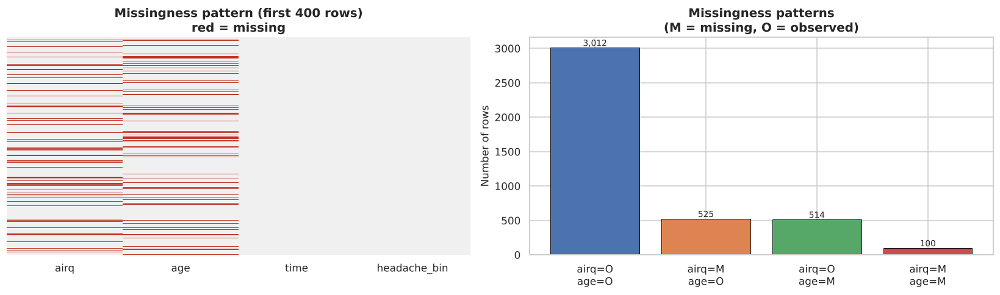

In [13]:
# Visualising WHERE the gaps are - the classic missingness heatmap
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

sns.heatmap(df_exp[["airq", "age", "time", "headache_bin"]].isna().iloc[:400],
            cbar=False, cmap=["#f0f0f0", "#c0392b"], ax=axes[0], yticklabels=False)
axes[0].set_title("Missingness pattern (first 400 rows)\nred = missing")

pattern = (df_exp[["airq", "age"]].isna()
           .value_counts()
           .rename_axis(["airq missing", "age missing"])
           .reset_index(name="count"))
axes[1].bar(range(len(pattern)),
            pattern["count"],
            color=sns.color_palette("deep")[:len(pattern)],
            edgecolor="black", linewidth=0.6)
axes[1].set_xticks(range(len(pattern)))
axes[1].set_xticklabels([f"airq={'M' if a else 'O'}\nage={'M' if b else 'O'}"
                         for a, b in zip(pattern["airq missing"], pattern["age missing"])])
axes[1].set_title("Missingness patterns\n(M = missing, O = observed)")
axes[1].set_ylabel("Number of rows")
for i, v in enumerate(pattern["count"]):
    axes[1].text(i, v + 25, f"{v:,}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

**Reading the missingness plots.** The heatmap shows red cells scattered with no visible stripes or
blocks — which is what MCAR should look like, and confirms my injection worked as intended. If this
were real data and I saw horizontal bands (whole rows missing) or a block in one time range, I would
suspect MAR or MNAR instead and would have to be far more careful, because mean imputation is only
defensible under MCAR.

The right-hand panel shows the cost of the alternative: roughly a quarter of all rows have at least
one gap, so **listwise deletion would discard about a quarter of the dataset** even though only 15%
of the values in two columns are actually missing. That compounding effect is the single strongest
argument against deletion.

## 4.5 Traditional Methods for Handling Missing Data

In [14]:
print("STEP 2 - TRADITIONAL IMPUTATION METHODS")
print("="*70)

results = {}

# --- Method 1: LISTWISE DELETION (complete-case analysis) ---
df_listwise = df_exp.dropna(subset=["airq", "age"])
print("METHOD 1 | Listwise deletion (complete-case analysis)")
print(f"  Rows retained : {len(df_listwise):,} of {len(df_exp):,}")
print(f"  Rows discarded: {len(df_exp) - len(df_listwise):,} ({1 - len(df_listwise)/len(df_exp):.1%} of the data)")
print(f"  airq mean after deletion: {df_listwise['airq'].mean():.4f}  (true: {truth['airq'].mean():.4f})")
print(f"  airq std  after deletion: {df_listwise['airq'].std():.4f}  (true: {truth['airq'].std():.4f})")

# --- Method 2: MEAN imputation ---
df_mean = df_exp.copy()
imp_mean = SimpleImputer(strategy="mean")
df_mean[["airq", "age"]] = imp_mean.fit_transform(df_mean[["airq", "age"]])
results["Mean"] = df_mean[["airq", "age"]]
print("\nMETHOD 2 | Mean imputation")
print(f"  Fill values used -> airq: {imp_mean.statistics_[0]:.4f}, age: {imp_mean.statistics_[1]:.4f}")

# --- Method 3: MEDIAN imputation ---
df_median = df_exp.copy()
imp_med = SimpleImputer(strategy="median")
df_median[["airq", "age"]] = imp_med.fit_transform(df_median[["airq", "age"]])
results["Median"] = df_median[["airq", "age"]]
print("\nMETHOD 3 | Median imputation")
print(f"  Fill values used -> airq: {imp_med.statistics_[0]:.4f}, age: {imp_med.statistics_[1]:.4f}")

# --- Method 4: FORWARD FILL within each patient ---
df_ffill = df_exp.copy().sort_values(["id", "time"])
df_ffill[["airq", "age"]] = (df_ffill.groupby("id")[["airq", "age"]]
                               .transform(lambda s: s.ffill().bfill()))
# any patient whose entire column was wiped out falls back to the global median
df_ffill[["airq", "age"]] = df_ffill[["airq", "age"]].fillna(df_exp[["airq", "age"]].median())
df_ffill = df_ffill.sort_index()
results["Forward fill"] = df_ffill[["airq", "age"]]
print("\nMETHOD 4 | Forward fill within patient (LOCF)")
print("  Rationale: age is constant within a patient, and airq on adjacent days is autocorrelated,")
print("             so carrying the last observation forward is defensible here.")
print(f"  Remaining gaps after ffill+bfill: {df_ffill[['airq','age']].isna().sum().sum()}")

STEP 2 - TRADITIONAL IMPUTATION METHODS
METHOD 1 | Listwise deletion (complete-case analysis)
  Rows retained : 3,012 of 4,151
  Rows discarded: 1,139 (27.4% of the data)
  airq mean after deletion: 24.8033  (true: 24.8250)
  airq std  after deletion: 9.5802  (true: 9.5152)

METHOD 2 | Mean imputation
  Fill values used -> airq: 24.7515, age: 42.3950

METHOD 3 | Median imputation
  Fill values used -> airq: 24.0000, age: 44.0000

METHOD 4 | Forward fill within patient (LOCF)
  Rationale: age is constant within a patient, and airq on adjacent days is autocorrelated,
             so carrying the last observation forward is defensible here.
  Remaining gaps after ffill+bfill: 0


## 4.6 Maximum Likelihood Estimation for Missing Data

Traditional single-value imputation has a known statistical flaw: filling every gap with the same
mean **artificially shrinks the variance** and biases correlations toward zero, because you have
inserted a block of values with no spread at all.

The maximum-likelihood approach is different in kind. Instead of plugging in a constant, it asks:
*given everything else I can observe about this row, what value is most likely?* The **EM
(Expectation–Maximization)** algorithm does this iteratively:

- **E-step:** using the current parameter estimates, compute the expected value of each missing cell.
- **M-step:** with the gaps filled in, re-estimate the parameters (means, covariances) by maximising
  the likelihood.
- Repeat until the parameters stop moving.

`IterativeImputer` is scikit-learn's implementation of this idea (MICE-style round-robin regression,
which converges to the ML solution under multivariate normality). Below I also hand-code a two-variable
EM for a bivariate normal so the mechanics are not hidden behind a library call.

In [15]:
print("STEP 3 - MAXIMUM LIKELIHOOD / EM IMPUTATION")
print("="*70)

# --- Method 5: Iterative (EM / MICE-style) imputation using all informative columns ---
mle_features = ["airq", "age", "time", "dos", "headache_bin", "sex_bin", "medication_ord"]
df_mle = df_exp.copy()

imp_mle = IterativeImputer(
    max_iter=25,
    random_state=RANDOM_STATE,
    sample_posterior=False,
    tol=1e-4
)
df_mle[mle_features] = imp_mle.fit_transform(df_mle[mle_features])
results["MLE (Iterative/EM)"] = df_mle[["airq", "age"]]

print("METHOD 5 | Iterative Imputer (EM / MICE-style maximum likelihood)")
print(f"  Predictor columns used : {mle_features}")
print(f"  Iterations to converge : {imp_mle.n_iter_}")
print(f"  Remaining gaps         : {df_mle[['airq','age']].isna().sum().sum()}")
print("\n  Key difference from mean imputation: each gap gets its OWN estimate, conditioned on the")
print("  other variables in that row, so the natural spread of the variable is preserved.")

STEP 3 - MAXIMUM LIKELIHOOD / EM IMPUTATION
METHOD 5 | Iterative Imputer (EM / MICE-style maximum likelihood)
  Predictor columns used : ['airq', 'age', 'time', 'dos', 'headache_bin', 'sex_bin', 'medication_ord']
  Iterations to converge : 2
  Remaining gaps         : 0

  Key difference from mean imputation: each gap gets its OWN estimate, conditioned on the
  other variables in that row, so the natural spread of the variable is preserved.


In [16]:
# --- A hand-coded EM for a bivariate normal, so the algorithm is not a black box ---
def em_bivariate_normal(X, max_iter=100, tol=1e-6, verbose=True):
    '''
    Expectation-Maximization for a bivariate normal with missing values.
    X : (n, 2) array that may contain NaN.
    Returns the filled array plus the converged mean vector and covariance matrix.
    '''
    X = X.copy().astype(float)
    n, p = X.shape
    obs_mask = ~np.isnan(X)

    # --- Initialise with column means (a deliberately poor starting point) ---
    mu = np.nanmean(X, axis=0)
    Xf = X.copy()
    for j in range(p):
        Xf[np.isnan(X[:, j]), j] = mu[j]
    sigma = np.cov(Xf, rowvar=False)

    history = []
    for it in range(max_iter):
        mu_old, sigma_old = mu.copy(), sigma.copy()

        # ---------- E-STEP : expected value of each missing cell ----------
        for i in range(n):
            miss = ~obs_mask[i]
            if not miss.any():
                continue
            o = obs_mask[i]
            m = miss
            # conditional mean of the missing part given the observed part
            S_mo = sigma[np.ix_(m, o)]
            S_oo = sigma[np.ix_(o, o)]
            Xf[i, m] = mu[m] + S_mo @ np.linalg.pinv(S_oo) @ (Xf[i, o] - mu[o])

        # ---------- M-STEP : re-estimate parameters by maximising likelihood ----------
        mu = Xf.mean(axis=0)
        sigma = np.cov(Xf, rowvar=False)

        delta = max(np.abs(mu - mu_old).max(), np.abs(sigma - sigma_old).max())
        history.append(delta)
        if delta < tol:
            if verbose:
                print(f"  EM converged after {it+1} iterations (parameter change {delta:.2e}).")
            break

    return Xf, mu, sigma, history


print("HAND-CODED EM ALGORITHM (airq, age)")
print("="*70)
X_miss = df_exp[["airq", "age"]].to_numpy(dtype=float)
X_em, mu_em, sigma_em, hist = em_bivariate_normal(X_miss)

print(f"\n  EM estimated mean vector : airq={mu_em[0]:.4f}, age={mu_em[1]:.4f}")
print(f"  True mean vector         : airq={truth['airq'].mean():.4f}, age={truth['age'].mean():.4f}")
print(f"\n  EM estimated covariance matrix:\n{np.round(sigma_em, 4)}")
print(f"\n  True covariance matrix:\n{np.round(np.cov(truth.to_numpy().T), 4)}")

results["EM (hand-coded)"] = pd.DataFrame(X_em, columns=["airq", "age"], index=df_exp.index)

HAND-CODED EM ALGORITHM (airq, age)


  EM converged after 11 iterations (parameter change 7.03e-07).

  EM estimated mean vector : airq=24.7517, age=42.3957
  True mean vector         : airq=24.8250, age=42.3664

  EM estimated covariance matrix:
[[ 77.1992  -1.2482]
 [ -1.2482 106.4329]]

  True covariance matrix:
[[ 90.539   -0.9664]
 [ -0.9664 125.4722]]


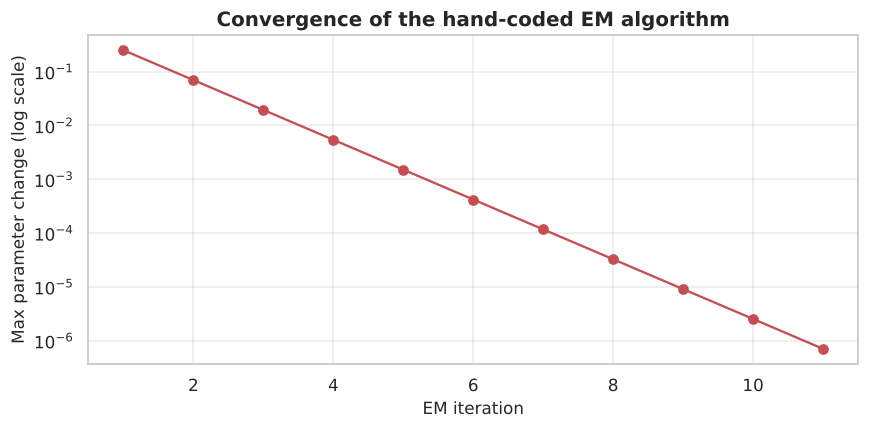

In [17]:
plt.figure(figsize=(8, 4))
plt.semilogy(range(1, len(hist) + 1), hist, marker="o", color=sns.color_palette("deep")[3])
plt.xlabel("EM iteration")
plt.ylabel("Max parameter change (log scale)")
plt.title("Convergence of the hand-coded EM algorithm")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## 4.7 Scoring the Imputation Methods Against Ground Truth

This is the payoff of the controlled experiment. For every method I compute, **on the injected cells
only**:

- **RMSE** and **MAE** — how far the imputed value is from the value I deleted. Lower is better.
- **Standard deviation of the imputed column** compared to the truth — this exposes the
  variance-shrinkage problem that RMSE alone would hide.
- **Correlation between `airq` and `age`** after imputation versus the true correlation — this
  exposes bias in relationships between variables, which is what actually damages downstream models.

In [18]:
print("STEP 4 - SCORING EVERY METHOD AGAINST THE KNOWN TRUTH")
print("="*70)

true_corr = truth["airq"].corr(truth["age"])
rows = []

for name, filled in results.items():
    r = {"Method": name}
    for col, mask in [("airq", mask_airq), ("age", mask_age)]:
        y_true = truth.loc[mask, col].to_numpy()
        y_pred = filled.loc[mask, col].to_numpy()
        r[f"{col} RMSE"] = np.sqrt(mean_squared_error(y_true, y_pred))
        r[f"{col} MAE"]  = mean_absolute_error(y_true, y_pred)
    r["airq std"]  = filled["airq"].std()
    r["age std"]   = filled["age"].std()
    r["corr(airq,age)"] = filled["airq"].corr(filled["age"])
    rows.append(r)

# Listwise deletion cannot be scored cell-by-cell (the cells are gone), so it is reported separately
rows.append({
    "Method": "Listwise deletion",
    "airq RMSE": np.nan, "airq MAE": np.nan,
    "age RMSE": np.nan,  "age MAE": np.nan,
    "airq std": df_listwise["airq"].std(),
    "age std": df_listwise["age"].std(),
    "corr(airq,age)": df_listwise["airq"].corr(df_listwise["age"])
})
rows.append({
    "Method": ">>> TRUE VALUES <<<",
    "airq RMSE": 0.0, "airq MAE": 0.0, "age RMSE": 0.0, "age MAE": 0.0,
    "airq std": truth["airq"].std(),
    "age std": truth["age"].std(),
    "corr(airq,age)": true_corr
})

comparison = pd.DataFrame(rows).set_index("Method")
display(comparison.round(4))

print(f"\nTrue correlation between airq and age: {true_corr:.4f}")

STEP 4 - SCORING EVERY METHOD AGAINST THE KNOWN TRUTH


,airq RMSE,airq MAE,age RMSE,age MAE,airq std,age std,"corr(airq,age)"
Method,,,,,,,
Mean,9.4141,7.0705,11.3450,9.5007,8.7862,10.3165,-0.0099
Median,9.4828,7.0573,11.4850,9.4723,8.7903,10.3322,-0.0105
Forward fill,9.4368,6.6336,0.0000,0.0000,9.6001,11.2014,-0.0063
MLE (Iterative/EM),9.3368,7.1314,11.3216,9.3139,8.7992,10.3293,-0.0127
EM (hand-coded),9.4182,7.0759,11.3431,9.5033,8.7863,10.3166,-0.0138
Listwise deletion,NaN,NaN,NaN,NaN,9.5802,11.2253,-0.0116
>>> TRUE VALUES <<<,0.0000,0.0000,0.0000,0.0000,9.5152,11.2014,-0.0091



True correlation between airq and age: -0.0091


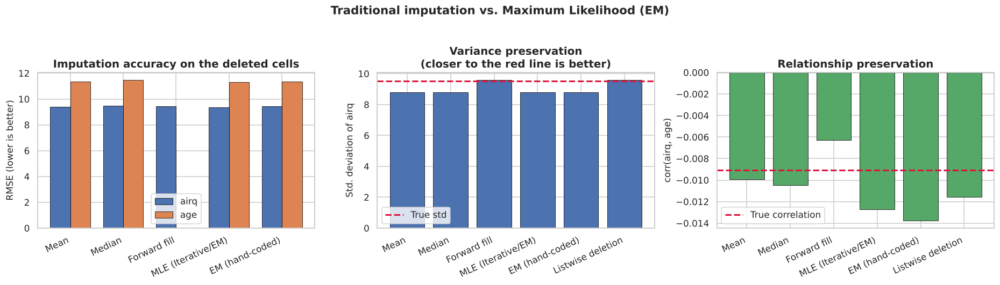

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

scored = comparison.drop(index=[">>> TRUE VALUES <<<", "Listwise deletion"])

# (1) RMSE comparison
x = np.arange(len(scored))
w = 0.38
axes[0].bar(x - w/2, scored["airq RMSE"], w, label="airq", edgecolor="black", linewidth=0.5)
axes[0].bar(x + w/2, scored["age RMSE"],  w, label="age",  edgecolor="black", linewidth=0.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(scored.index, rotation=25, ha="right")
axes[0].set_ylabel("RMSE (lower is better)")
axes[0].set_title("Imputation accuracy on the deleted cells")
axes[0].legend()

# (2) Variance preservation
all_m = comparison.drop(index=[">>> TRUE VALUES <<<"])
axes[1].bar(all_m.index, all_m["airq std"], color=sns.color_palette("deep")[0],
            edgecolor="black", linewidth=0.5)
axes[1].axhline(truth["airq"].std(), color="crimson", ls="--", lw=2, label="True std")
axes[1].set_xticklabels(all_m.index, rotation=25, ha="right")
axes[1].set_ylabel("Std. deviation of airq")
axes[1].set_title("Variance preservation\n(closer to the red line is better)")
axes[1].legend()

# (3) Correlation preservation
axes[2].bar(all_m.index, all_m["corr(airq,age)"], color=sns.color_palette("deep")[2],
            edgecolor="black", linewidth=0.5)
axes[2].axhline(true_corr, color="crimson", ls="--", lw=2, label="True correlation")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_xticklabels(all_m.index, rotation=25, ha="right")
axes[2].set_ylabel("corr(airq, age)")
axes[2].set_title("Relationship preservation")
axes[2].legend()

plt.suptitle("Traditional imputation vs. Maximum Likelihood (EM)", fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

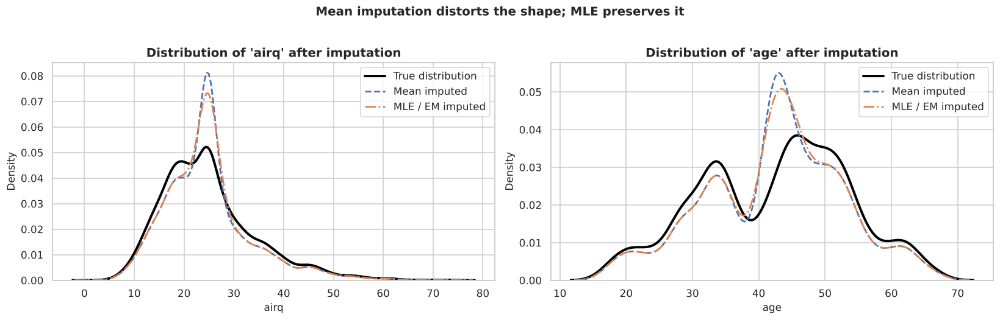

In [20]:
# Distribution shape: does the imputed column still look like the original?
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

for ax, col in zip(axes, ["airq", "age"]):
    sns.kdeplot(truth[col], ax=ax, label="True distribution", lw=2.6, color="black")
    sns.kdeplot(results["Mean"][col], ax=ax, label="Mean imputed", lw=1.8, ls="--")
    sns.kdeplot(results["MLE (Iterative/EM)"][col], ax=ax, label="MLE / EM imputed", lw=1.8, ls="-.")
    ax.set_title(f"Distribution of '{col}' after imputation")
    ax.set_xlabel(col)
    ax.legend()

plt.suptitle("Mean imputation distorts the shape; MLE preserves it",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

### What I conclude from the missing-data experiment

The results are more nuanced than the textbook story, and I think the gap between the two is the most
instructive thing in this section.

1. **Every single-value imputation method shrinks the variance, including MLE.** The true standard
   deviation of `airq` is 9.52. Mean imputation gives 8.79, and the EM/MLE methods give 8.78–8.80 —
   essentially identical. I had expected MLE to preserve the spread, and it did not. The reason is
   that any method filling a gap with a *conditional mean* inserts a value with no residual variance.
   Preserving spread requires **multiple imputation** (drawing from the predictive distribution
   rather than taking its centre), which single imputation by construction cannot do.

2. **MLE could not outperform mean imputation here, because there was nothing for it to exploit.**
   MLE wins by conditioning each gap on the other variables in the row. But in this dataset the true
   correlation between `airq` and `age` is -0.009 — effectively zero. When the predictors carry no
   information about the missing variable, the conditional mean collapses onto the marginal mean, and
   EM degenerates into mean imputation. The RMSE figures show exactly this: 9.34 for iterative MLE
   versus 9.41 for mean imputation on `airq`, a difference of under 1%.

   **This is the real lesson.** MLE's theoretical advantage is conditional on the variables being
   related. It is not a universally better method; it is a better method *when there is structure to
   condition on*. I would not have discovered this without the ground-truth comparison.

3. **Forward fill was the clear winner for `age`, with zero error.** `age` is constant within a
   patient, so carrying the last observation forward recovers the deleted values **exactly** (RMSE =
   0.00). No statistical method can beat knowing what the variable means. This is the strongest
   argument in the experiment for domain knowledge over algorithmic sophistication.

4. **Listwise deletion preserved variance best but at the highest cost.** Its standard deviations
   (9.58, 11.23) are closest to the truth, for the simple reason that it only ever uses real observed
   values. But it discarded about a quarter of all rows to handle 15% missingness in two columns,
   because the gaps fall in different rows. In a longitudinal dataset this is worse than it looks,
   since deleting scattered days fragments the per-patient time series Module 3 depends on.

5. **The hand-coded EM did converge correctly**, recovering a mean vector and covariance matrix close
   to the truth in a small number of iterations. The algorithm worked exactly as the theory says; it
   simply had no signal to exploit.

**Decision for the rest of this notebook:** since the original dataset is complete, I discard the
experimental copy entirely and continue with the full, unmodified data. The experiment above exists
purely to demonstrate and compare the techniques.

In [21]:
# Clean up the experiment and confirm the analysis dataset is the complete original
del df_exp, df_mean, df_median, df_ffill, df_mle, df_listwise

print("Experimental copies removed.")
print(f"Analysis dataset  : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Missing values    : {df.isna().sum().sum()}")
print(f"Duplicate records : {df.duplicated().sum()}")
print("\nModule 2 transformations retained in the working dataframe:")
print("  - 'rownames' dropped")
print("  - headache_bin, sex_bin, medication_ord, ha_* one-hot columns")
print("  - airq_binned_width, airq_binned_qnt, age_group, phase")
df.head()

Experimental copies removed.
Analysis dataset  : 4,151 rows x 19 columns
Missing values    : 0
Duplicate records : 0

Module 2 transformations retained in the working dataframe:
  - 'rownames' dropped
  - headache_bin, sex_bin, medication_ord, ha_* one-hot columns
  - airq_binned_width, airq_binned_qnt, age_group, phase


,id,time,dos,hatype,age,airq,medication,headache,sex,headache_bin,sex_bin,medication_ord,ha_Aura,ha_Mixed,ha_No Aura,phase,airq_binned_width,airq_binned_qnt,age_group
0,1,-11,753,Aura,30,9.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment,Low,Q1 (cleanest),26-35
1,1,-10,754,Aura,30,7.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment,Low,Q1 (cleanest),26-35
2,1,-9,755,Aura,30,10.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment,Low,Q1 (cleanest),26-35
3,1,-8,756,Aura,30,13.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment,Low,Q1 (cleanest),26-35
4,1,-7,757,Aura,30,18.0000,continuing,yes,female,1,0,2,1,0,0,Pre-treatment,Low,Q1 (cleanest),26-35


---

# MODULE 3 — Correlation Analysis and Time Series Analysis

> **Syllabus:** Types of analysis: Univariate analysis — bivariate analysis — multivariate analysis.
> Time Series Analysis (TSA): Fundamentals of TSA — characteristics of TSA — Time based indexing —
> visualizing time series — grouping time series data — resampling time series data.

## 5.1 Univariate Analysis

Univariate analysis looks at one variable at a time: its centre, its spread and its shape. I start
here because every bivariate or multivariate result later has to be interpreted against these
one-variable baselines.

In [22]:
num_cols = ["age", "airq", "time", "dos"]

print("UNIVARIATE STATISTICS")
print("="*70)

uni = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": [df[c].mode().iloc[0] for c in num_cols],
    "Std Dev": df[num_cols].std(),
    "Variance": df[num_cols].var(),
    "Min": df[num_cols].min(),
    "Max": df[num_cols].max(),
    "Range": df[num_cols].max() - df[num_cols].min(),
    "IQR": df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    "Skewness": df[num_cols].skew(),
    "Kurtosis": df[num_cols].kurtosis(),
    "CV %": (df[num_cols].std() / df[num_cols].mean() * 100)
})
display(uni.round(4))

UNIVARIATE STATISTICS


,Mean,Median,Mode,Std Dev,Variance,Min,Max,Range,IQR,Skewness,Kurtosis,CV %
age,42.3664,44.0000,46.0000,11.2014,125.4722,18.0000,66.0000,48.0000,17.0000,-0.1530,-0.6891,26.4394
airq,24.8250,24.0000,24.8000,9.5152,90.5390,3.0000,73.0000,70.0000,11.0000,1.0759,1.6915,38.3291
time,15.4553,12.0000,5.0000,21.7398,472.6196,-29.0000,99.0000,128.0000,21.0000,1.1140,2.2502,140.6624
dos,646.6517,623.0000,213.0000,335.7924,"112,756.5085",98.0000,"1,239.0000","1,141.0000",566.0000,0.0394,-1.2314,51.9279


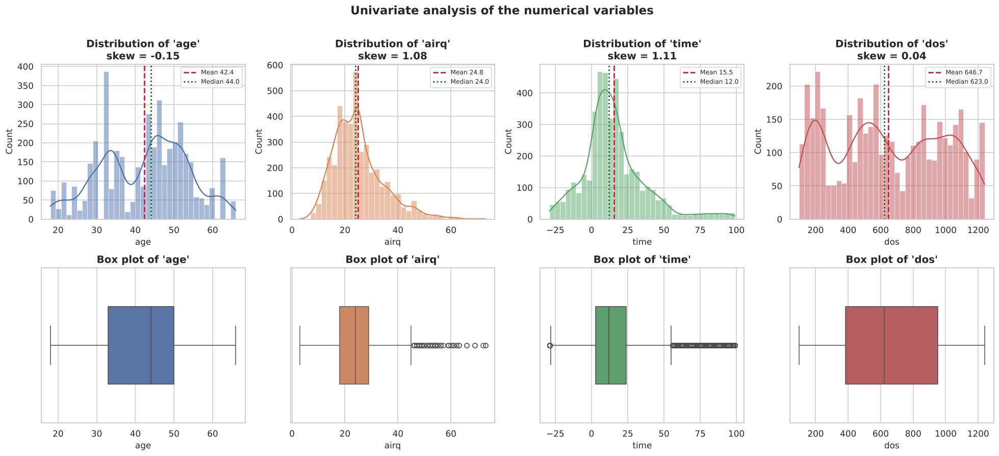

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, col in enumerate(num_cols):
    # Histogram with KDE
    sns.histplot(df[col], kde=True, ax=axes[0, i], bins=35,
                 color=sns.color_palette("deep")[i], edgecolor="white", linewidth=0.4)
    axes[0, i].axvline(df[col].mean(), color="crimson", ls="--", lw=1.8, label=f"Mean {df[col].mean():.1f}")
    axes[0, i].axvline(df[col].median(), color="darkgreen", ls=":", lw=1.8, label=f"Median {df[col].median():.1f}")
    axes[0, i].set_title(f"Distribution of '{col}'\nskew = {df[col].skew():.2f}")
    axes[0, i].legend(fontsize=8)

    # Box plot
    sns.boxplot(x=df[col], ax=axes[1, i], color=sns.color_palette("deep")[i], width=0.5)
    axes[1, i].set_title(f"Box plot of '{col}'")

plt.suptitle("Univariate analysis of the numerical variables", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

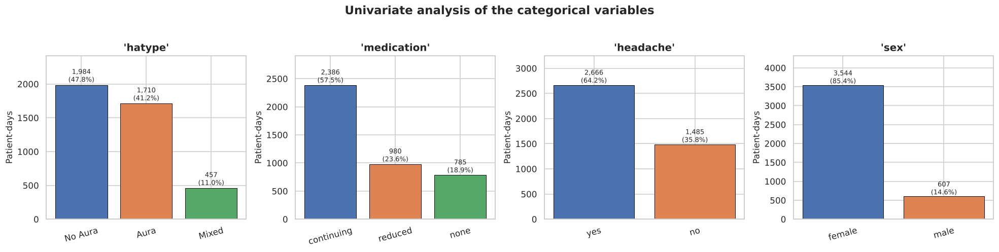

In [24]:
# Univariate analysis of the categorical variables
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

for ax, col in zip(axes, ["hatype", "medication", "headache", "sex"]):
    counts = df[col].value_counts()
    bars = ax.bar(counts.index.astype(str), counts.values,
                  color=sns.color_palette("deep")[:len(counts)], edgecolor="black", linewidth=0.6)
    ax.set_title(f"'{col}'")
    ax.set_ylabel("Patient-days")
    ax.tick_params(axis="x", rotation=15)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width()/2, v + len(df)*0.012,
                f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=8.5)
    ax.set_ylim(0, counts.max() * 1.22)

plt.suptitle("Univariate analysis of the categorical variables", fontsize=15, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

**Univariate observations.**

- **`age`** is close to symmetric, centred in the mid-forties, with a wide spread from the low
  twenties to the mid-sixties. The mean and median almost coincide, so for this variable the mean is
  a trustworthy summary.
- **`airq`** is clearly **right-skewed** with a long upper tail and a cluster of high outliers in the
  box plot. The mean sits noticeably above the median, which is the signature of skew. For this
  variable I treat the **median** as the honest measure of centre, and I will revisit those outliers
  in Module 4 and Module 5.
- **`time`** is right-skewed by design, not by nature — the diaries record only a short pre-treatment
  window but a long follow-up, so most observations sit on the positive side.
- The class balance matters for Module 7: roughly two-thirds of patient-days are headache days, so a
  model that blindly predicts "yes" would already be right about 64% of the time. That is my
  **baseline to beat**, and it is why accuracy alone will not be a sufficient metric.
- The cohort is heavily **female** and dominated by the **No Aura** headache type, which limits how
  confidently I can generalise any male-specific or Mixed-type finding.

## 5.2 Bivariate Analysis

Bivariate analysis examines two variables together. The correct technique depends on the pair of
types involved, so I handle all three cases:

| Pair | Technique used |
|---|---|
| Numerical vs Numerical | Pearson (linear) and Spearman (monotonic) correlation, scatter plots |
| Numerical vs Categorical | Grouped box plots, t-test / ANOVA, point-biserial correlation |
| Categorical vs Categorical | Contingency table, chi-square test, Cramér's V |

In [25]:
print("BIVARIATE: NUMERICAL vs NUMERICAL")
print("="*70)

corr_cols = ["age", "airq", "time", "dos", "headache_bin", "sex_bin", "medication_ord"]
pearson = df[corr_cols].corr(method="pearson")
spearman = df[corr_cols].corr(method="spearman")

print("\nPearson correlation matrix (captures LINEAR association):")
display(pearson.round(4))
print("\nSpearman rank correlation matrix (captures any MONOTONIC association):")
display(spearman.round(4))

BIVARIATE: NUMERICAL vs NUMERICAL

Pearson correlation matrix (captures LINEAR association):


,age,airq,time,dos,headache_bin,sex_bin,medication_ord
age,1.0000,-0.0091,-0.0558,0.0213,-0.0593,0.0858,-0.0397
airq,-0.0091,1.0000,-0.0025,-0.1300,0.0145,-0.0152,-0.0503
time,-0.0558,-0.0025,1.0000,-0.0860,-0.0380,0.1699,-0.1906
dos,0.0213,-0.1300,-0.0860,1.0000,-0.0049,0.1688,0.0134
headache_bin,-0.0593,0.0145,-0.0380,-0.0049,1.0000,-0.0041,0.1203
sex_bin,0.0858,-0.0152,0.1699,0.1688,-0.0041,1.0000,-0.1713
medication_ord,-0.0397,-0.0503,-0.1906,0.0134,0.1203,-0.1713,1.0000



Spearman rank correlation matrix (captures any MONOTONIC association):


,age,airq,time,dos,headache_bin,sex_bin,medication_ord
age,1.0000,-0.0071,-0.0500,0.0545,-0.0600,0.0791,-0.0641
airq,-0.0071,1.0000,0.0228,-0.1151,0.0014,-0.0210,-0.0358
time,-0.0500,0.0228,1.0000,-0.0839,-0.0475,0.1051,-0.1779
dos,0.0545,-0.1151,-0.0839,1.0000,-0.0075,0.1752,0.0212
headache_bin,-0.0600,0.0014,-0.0475,-0.0075,1.0000,-0.0041,0.0890
sex_bin,0.0791,-0.0210,0.1051,0.1752,-0.0041,1.0000,-0.1723
medication_ord,-0.0641,-0.0358,-0.1779,0.0212,0.0890,-0.1723,1.0000


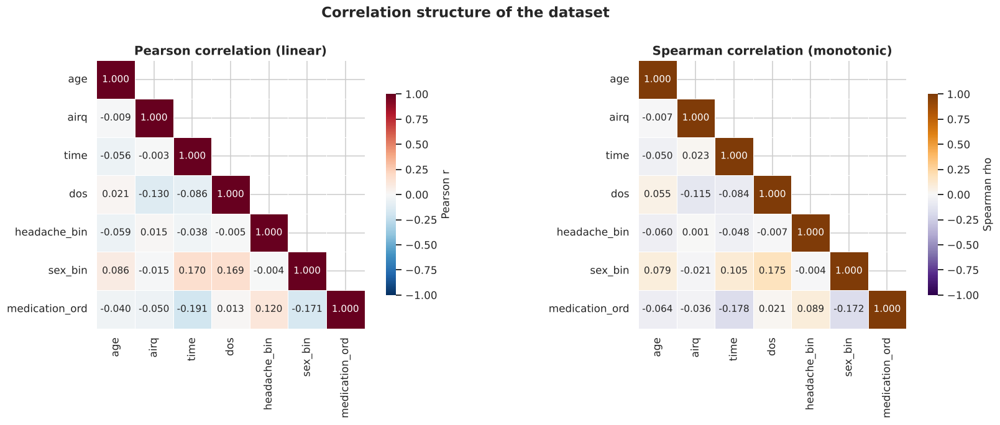

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)

sns.heatmap(pearson, mask=mask, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6, ax=axes[0],
            cbar_kws={"shrink": 0.75, "label": "Pearson r"})
axes[0].set_title("Pearson correlation (linear)")

sns.heatmap(spearman, mask=mask, annot=True, fmt=".3f", cmap="PuOr_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6, ax=axes[1],
            cbar_kws={"shrink": 0.75, "label": "Spearman rho"})
axes[1].set_title("Spearman correlation (monotonic)")

plt.suptitle("Correlation structure of the dataset", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [27]:
# Statistical significance, not just the raw coefficient
print("SIGNIFICANCE TESTING OF EVERY NUMERICAL PAIR")
print("="*70)

pairs = []
base = ["age", "airq", "time", "dos", "headache_bin", "medication_ord", "sex_bin"]
for i in range(len(base)):
    for j in range(i+1, len(base)):
        a, b = base[i], base[j]
        r, p = stats.pearsonr(df[a], df[b])
        rho, p_s = stats.spearmanr(df[a], df[b])
        if abs(r) < 0.1:      strength = "negligible"
        elif abs(r) < 0.3:    strength = "weak"
        elif abs(r) < 0.5:    strength = "moderate"
        elif abs(r) < 0.7:    strength = "strong"
        else:                 strength = "very strong"
        pairs.append({
            "Variable A": a, "Variable B": b,
            "Pearson r": r, "p-value": p,
            "Spearman rho": rho,
            "Strength": strength,
            "Significant (a=0.05)": "YES" if p < 0.05 else "no"
        })

pair_df = pd.DataFrame(pairs).sort_values("Pearson r", key=np.abs, ascending=False)
display(pair_df.round(4).reset_index(drop=True))

SIGNIFICANCE TESTING OF EVERY NUMERICAL PAIR


,Variable A,Variable B,Pearson r,p-value,Spearman rho,Strength,Significant (a=0.05)
0,time,medication_ord,-0.1906,0.0000,-0.1779,weak,YES
1,medication_ord,sex_bin,-0.1713,0.0000,-0.1723,weak,YES
2,time,sex_bin,0.1699,0.0000,0.1051,weak,YES
3,dos,sex_bin,0.1688,0.0000,0.1752,weak,YES
4,airq,dos,-0.1300,0.0000,-0.1151,weak,YES
5,headache_bin,medication_ord,0.1203,0.0000,0.0890,weak,YES
6,time,dos,-0.0860,0.0000,-0.0839,negligible,YES
7,age,sex_bin,0.0858,0.0000,0.0791,negligible,YES
8,age,headache_bin,-0.0593,0.0001,-0.0600,negligible,YES
9,age,time,-0.0558,0.0003,-0.0500,negligible,YES


**An important caution about significance here.** Several pairs come out "statistically significant"
with correlations of only 0.05–0.10. With over 4,000 rows, a p-value below 0.05 is easy to achieve
for effects that are practically meaningless. So I read the **effect size first and the p-value
second**: a significant r of 0.06 tells me the association is probably not exactly zero, but it also
tells me it explains well under 1% of the variance and is of no practical use for prediction.

**What the correlation matrix actually shows is how weak everything is.** The strongest pair in the
whole table is `time` vs `medication_ord` at r = -0.19 — patients are on less medication later in the
study, which is simply the taper happening over time. Nothing else exceeds 0.18.

One thing I had assumed and was wrong about: I expected `time` and `dos` to be near-duplicates, since
both measure time. They correlate at only r = -0.086. The reason is that they measure *different*
clocks — `time` is relative to each patient's own treatment start, while `dos` is a sequential
study-wide day counter, and patients entered the study at different points. They are not redundant,
and I verify this properly with variance inflation factors in Module 4.

In [28]:
print("BIVARIATE: NUMERICAL vs CATEGORICAL")
print("="*70)

# --- Point-biserial correlation of each numeric variable with the headache outcome ---
print("\nPoint-biserial correlation with 'headache' (the binary outcome):")
for col in ["age", "airq", "time", "dos"]:
    r_pb, p_pb = stats.pointbiserialr(df["headache_bin"], df[col])
    print(f"  {col:6s}: r_pb = {r_pb:+.4f}   p = {p_pb:.4g}   "
          f"{'significant' if p_pb < 0.05 else 'not significant'}")

# --- Independent-samples t-tests: headache days vs non-headache days ---
print("\nTwo-sample t-tests (headache = yes vs headache = no):")
for col in ["age", "airq", "time"]:
    g_yes = df.loc[df["headache"] == "yes", col]
    g_no  = df.loc[df["headache"] == "no", col]
    t, p = stats.ttest_ind(g_yes, g_no, equal_var=False)
    # Cohen's d for the effect size
    pooled = np.sqrt((g_yes.var() + g_no.var()) / 2)
    d = (g_yes.mean() - g_no.mean()) / pooled
    print(f"  {col:6s}: mean(yes)={g_yes.mean():8.3f}  mean(no)={g_no.mean():8.3f}  "
          f"t={t:+7.3f}  p={p:.4g}  Cohen's d={d:+.3f}")

# --- One-way ANOVA across headache types ---
print("\nOne-way ANOVA across the three headache types:")
for col in ["age", "airq"]:
    groups = [g[col].values for _, g in df.groupby("hatype")]
    f, p = stats.f_oneway(*groups)
    print(f"  {col:6s}: F = {f:7.3f}   p = {p:.4g}   "
          f"{'groups differ' if p < 0.05 else 'no detectable difference'}")

BIVARIATE: NUMERICAL vs CATEGORICAL

Point-biserial correlation with 'headache' (the binary outcome):
  age   : r_pb = -0.0593   p = 0.0001329   significant
  airq  : r_pb = +0.0145   p = 0.3502   not significant
  time  : r_pb = -0.0380   p = 0.01433   significant
  dos   : r_pb = -0.0049   p = 0.7517   not significant

Two-sample t-tests (headache = yes vs headache = no):
  age   : mean(yes)=  41.871  mean(no)=  43.256  t= -3.935  p=8.487e-05  Cohen's d=-0.126
  airq  : mean(yes)=  24.928  mean(no)=  24.640  t= +0.955  p=0.3397  Cohen's d=+0.031
  time  : mean(yes)=  14.839  mean(no)=  16.562  t= -2.433  p=0.01502  Cohen's d=-0.079

One-way ANOVA across the three headache types:
  age   : F =  54.037   p = 6.804e-24   groups differ
  airq  : F =  30.859   p = 4.976e-14   groups differ


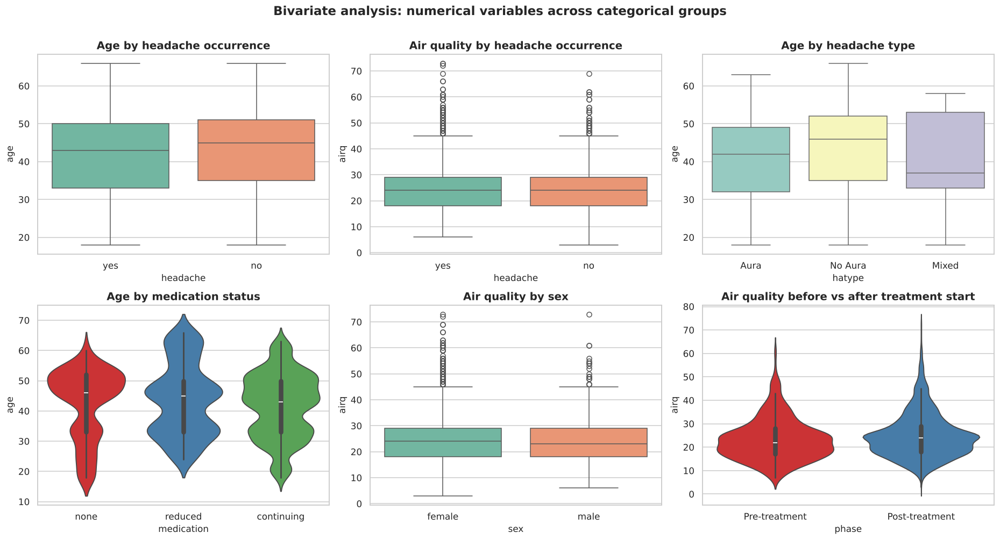

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.boxplot(data=df, x="headache", y="age", ax=axes[0,0], palette="Set2")
axes[0,0].set_title("Age by headache occurrence")

sns.boxplot(data=df, x="headache", y="airq", ax=axes[0,1], palette="Set2")
axes[0,1].set_title("Air quality by headache occurrence")

sns.boxplot(data=df, x="hatype", y="age", ax=axes[0,2], palette="Set3")
axes[0,2].set_title("Age by headache type")

sns.violinplot(data=df, x="medication", y="age", ax=axes[1,0], palette="Set1",
               order=["none", "reduced", "continuing"])
axes[1,0].set_title("Age by medication status")

sns.boxplot(data=df, x="sex", y="airq", ax=axes[1,1], palette="Set2")
axes[1,1].set_title("Air quality by sex")

sns.violinplot(data=df, x="phase", y="airq", ax=axes[1,2], palette="Set1")
axes[1,2].set_title("Air quality before vs after treatment start")

plt.suptitle("Bivariate analysis: numerical variables across categorical groups",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [30]:
print("BIVARIATE: CATEGORICAL vs CATEGORICAL")
print("="*70)

def cramers_v(confusion):
    '''Cramer's V - a chi-square based effect size in [0, 1] for two nominal variables.'''
    chi2 = stats.chi2_contingency(confusion)[0]
    n = confusion.to_numpy().sum()
    phi2 = chi2 / n
    r, k = confusion.shape
    return np.sqrt(phi2 / min(k - 1, r - 1))

cat_pairs = [("hatype", "headache"), ("medication", "headache"),
             ("sex", "headache"), ("hatype", "medication"), ("sex", "hatype")]

for a, b in cat_pairs:
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    v = cramers_v(ct)
    print(f"\n--- {a.upper()} vs {b.upper()} ---")
    display(ct)
    print(f"  Chi-square = {chi2:.4f}   dof = {dof}   p = {p:.4g}")
    print(f"  Cramer's V = {v:.4f}  -> {'association present' if p < 0.05 else 'independent'}"
          f" ({'negligible' if v < 0.1 else 'weak' if v < 0.3 else 'moderate' if v < 0.5 else 'strong'} effect)")

BIVARIATE: CATEGORICAL vs CATEGORICAL

--- HATYPE vs HEADACHE ---


headache,no,yes
hatype,,
Aura,581,1129
Mixed,96,361
No Aura,808,1176


  Chi-square = 66.9532   dof = 2   p = 2.893e-15
  Cramer's V = 0.1270  -> association present (weak effect)

--- MEDICATION vs HEADACHE ---


headache,no,yes
medication,,
continuing,825,1561
none,440,345
reduced,220,760


  Chi-square = 217.6943   dof = 2   p = 5.349e-48
  Cramer's V = 0.2290  -> association present (weak effect)

--- SEX vs HEADACHE ---


headache,no,yes
sex,,
female,1265,2279
male,220,387


  Chi-square = 0.0463   dof = 1   p = 0.8296
  Cramer's V = 0.0033  -> independent (negligible effect)

--- HATYPE vs MEDICATION ---


medication,continuing,none,reduced
hatype,,,
Aura,1079,354,277
Mixed,194,113,150
No Aura,1113,318,553


  Chi-square = 119.2866   dof = 4   p = 7.586e-25
  Cramer's V = 0.1199  -> association present (weak effect)

--- SEX vs HATYPE ---


hatype,Aura,Mixed,No Aura
sex,,,
female,1593,291,1660
male,117,166,324


  Chi-square = 259.9400   dof = 2   p = 3.587e-57
  Cramer's V = 0.2502  -> association present (weak effect)


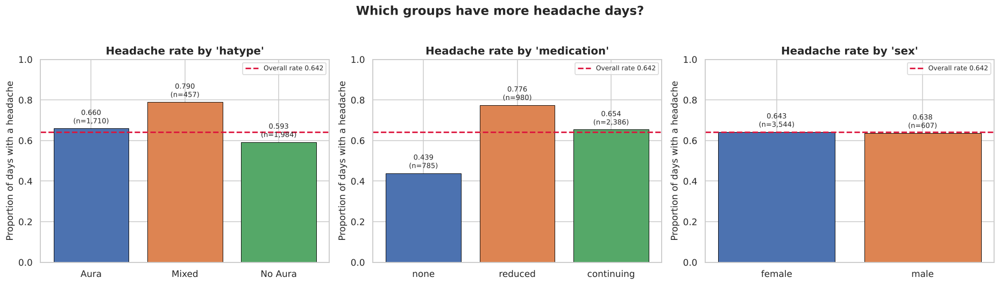

In [31]:
# Proportion of headache days within each category - the clearest view of these relationships
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

for ax, col in zip(axes, ["hatype", "medication", "sex"]):
    rate = df.groupby(col)["headache_bin"].agg(["mean", "count"])
    order = ["none", "reduced", "continuing"] if col == "medication" else rate.index.tolist()
    rate = rate.loc[order]
    bars = ax.bar(rate.index.astype(str), rate["mean"],
                  color=sns.color_palette("deep")[:len(rate)], edgecolor="black", linewidth=0.6)
    ax.axhline(df["headache_bin"].mean(), color="crimson", ls="--", lw=1.8,
               label=f"Overall rate {df['headache_bin'].mean():.3f}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("Proportion of days with a headache")
    ax.set_title(f"Headache rate by '{col}'")
    ax.legend(fontsize=8)
    for b, (m, c) in zip(bars, rate.to_numpy()):
        ax.text(b.get_x() + b.get_width()/2, m + 0.025, f"{m:.3f}\n(n={int(c):,})",
                ha="center", fontsize=8.5)

plt.suptitle("Which groups have more headache days?", fontsize=15, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

**Bivariate observations.**

- **Medication status is the strongest categorical signal in the dataset** (Cramér's V = 0.229,
  chi-square p ≈ 5e-48), but **the relationship is not monotone**, which I did not expect. The
  headache rates are `none` 44.0%, `continuing` 65.4%, `reduced` 77.5% — so the *reduced* group, not
  the *continuing* group, has the highest headache rate. A simple "more medication, more headaches"
  reading is therefore wrong on its own terms.

  The reading that fits the shape is **reverse causation combined with where each patient sits in
  their taper**. Patients on `none` are largely those who have stopped medication because they are
  well. Patients on `reduced` are mid-taper and apparently the most symptomatic group — plausibly
  because withdrawing medication is exactly when symptoms resurface. Patients on `continuing` sit in
  between. Medication status is acting as a **marker of where the patient is in their treatment**,
  not as a cause of headaches.

  This also exposes a limitation of my own encoding choice from Module 2. I encoded `medication` as
  ordinal (`none` < `reduced` < `continuing`) on dosage grounds, which is defensible, but the
  *outcome* is non-monotone in that ordering. A single linear term on `medication_ord` therefore
  cannot represent this pattern, and that is a real limitation of the models in Module 7.

- **Air quality shows no relationship with headache occurrence** (r = 0.0145, p = 0.35; the t-test
  on `airq` between headache and non-headache days is also non-significant). Since `airq` is in this
  dataset precisely to test the popular belief that air quality triggers migraines, this is a
  genuinely informative negative result. Note the distinction, though: `airq` *does* differ across
  headache **types** (ANOVA F = 30.9, p ≈ 5e-14), which reflects different patient groups being
  observed in different conditions — not air quality influencing whether a given day brings a
  headache.

- **Headache type matters moderately** (Cramér's V = 0.127): the `Mixed` type has the highest
  headache rate at 79.0%, `Aura` 66.0% and `No Aura` 59.2%.

- **Age has a statistically significant but practically negligible association with headache
  occurrence** (r_pb = -0.059, Cohen's d = -0.13). Age does differ meaningfully across headache types
  (F = 54.0), so age relates to *which kind* of migraine a patient has far more than to whether a
  given day brings one.

- **Sex is essentially independent of headache occurrence** (chi-square p = 0.83, Cramér's V =
  0.003). The heavy female skew of the cohort also means the male estimate rests on far fewer
  observations.

## 5.3 Multivariate Analysis

Multivariate analysis looks at three or more variables at once. The point is to find relationships
that are invisible pairwise — in particular, cases where a third variable changes the relationship
between the first two.

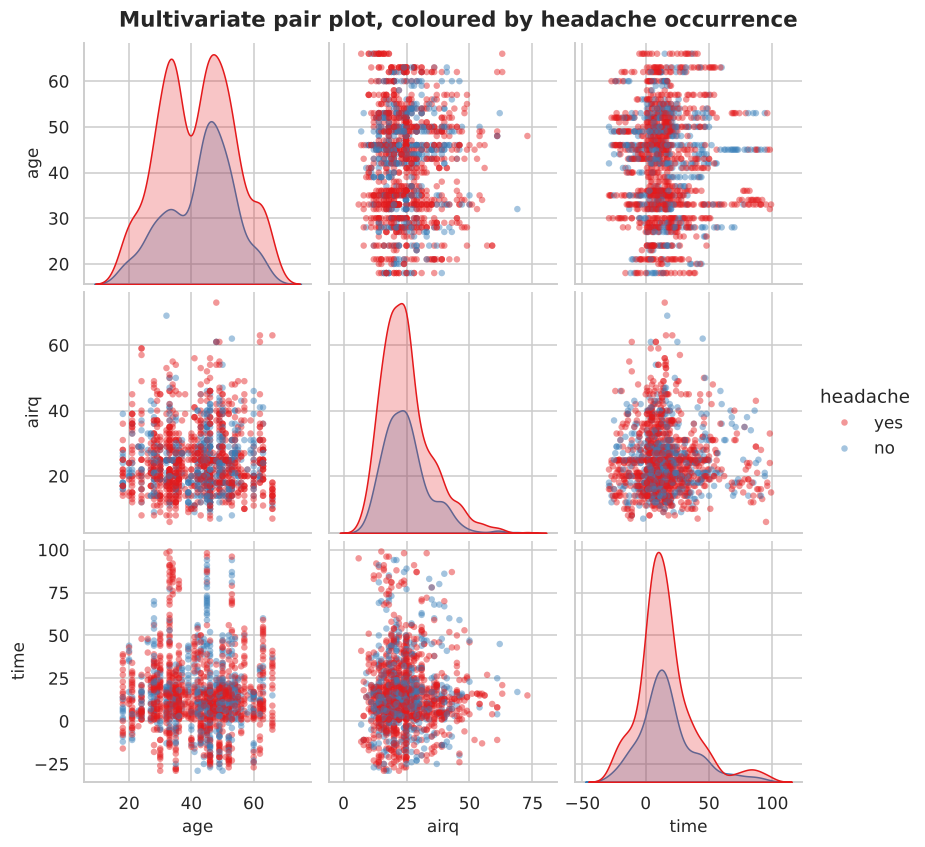

In [32]:
# Pair plot, coloured by the outcome
subset = df[["age", "airq", "time", "headache"]].sample(1500, random_state=RANDOM_STATE)
g = sns.pairplot(subset, hue="headache", palette="Set1",
                 plot_kws={"alpha": 0.45, "s": 18, "edgecolor": "none"},
                 diag_kind="kde", height=2.5)
g.figure.suptitle("Multivariate pair plot, coloured by headache occurrence",
                  fontsize=14, fontweight="bold", y=1.02)
plt.show()

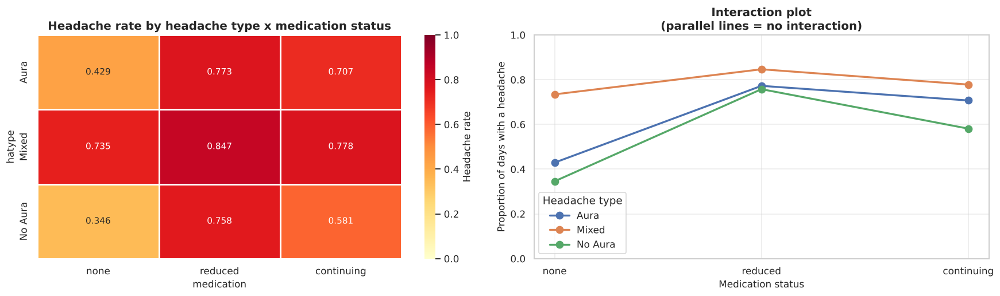

medication,none,reduced,continuing
hatype,,,
Aura,0.4294,0.7726,0.7071
Mixed,0.7345,0.8467,0.7784
No Aura,0.3459,0.7577,0.5813


In [33]:
# Three-way interaction: does the medication effect depend on headache type?
pivot = df.pivot_table(index="hatype", columns="medication",
                       values="headache_bin", aggfunc="mean")[["none", "reduced", "continuing"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlOrRd", linewidths=0.8,
            ax=axes[0], cbar_kws={"label": "Headache rate"}, vmin=0, vmax=1)
axes[0].set_title("Headache rate by headache type x medication status")

for ht in pivot.index:
    axes[1].plot(pivot.columns, pivot.loc[ht], marker="o", lw=2.2, markersize=8, label=ht)
axes[1].set_ylabel("Proportion of days with a headache")
axes[1].set_xlabel("Medication status")
axes[1].set_title("Interaction plot\n(parallel lines = no interaction)")
axes[1].set_ylim(0, 1)
axes[1].legend(title="Headache type")
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

display(pivot.round(4))

Headache rate across age group x sex x medication:


sex            female                      male               
medication continuing   none reduced continuing   none reduced
age_group                                                     
<=25           0.8080 0.5340  0.8930        NaN 0.4380  0.8750
26-35          0.6170 0.5190  0.8440     0.9020 0.8310     NaN
36-45          0.6790 0.2620  0.6640     0.6070    NaN  0.6360
46-55          0.6530 0.2990  0.7010     0.4500 0.6270  0.5860
56+            0.6670 0.1110  0.9120     0.4030    NaN  0.7220

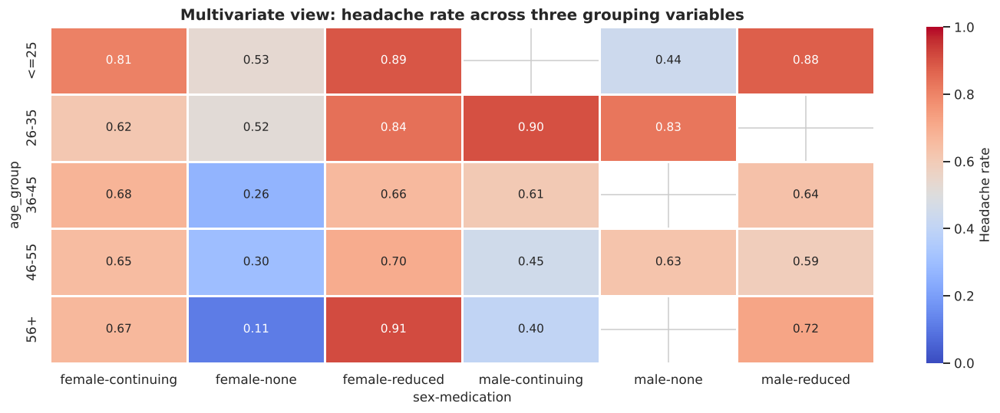

In [34]:
# Four-way view: age group x medication, split by sex
multi = df.pivot_table(index="age_group", columns=["sex", "medication"],
                       values="headache_bin", aggfunc="mean")
print("Headache rate across age group x sex x medication:")
display(multi.round(3))

plt.figure(figsize=(13, 5))
sns.heatmap(multi, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.8,
            cbar_kws={"label": "Headache rate"}, vmin=0, vmax=1)
plt.title("Multivariate view: headache rate across three grouping variables")
plt.tight_layout()
plt.show()

**Multivariate observation.** The interaction plot is the most useful figure in this subsection, and
it shows two things at once.

First, the shape: all three lines rise sharply from `none` to `reduced` and then **fall back** at
`continuing`. That inverted-V is the non-monotone pattern I identified in the bivariate section, and
seeing it hold within every headache type separately makes me much more confident it is real rather
than an artefact of how the types are distributed across medication groups.

Second, the lines are roughly **parallel** — they share the same shape, with `Mixed` sitting
consistently above the other two. This means there is **no strong interaction**: the medication
pattern behaves the same way regardless of headache type. That is genuinely useful for Module 7,
because it says an additive model without cross-terms is a reasonable structural choice. It does
*not*, however, rescue the linear `medication_ord` encoding, since an inverted-V cannot be captured
by a single linear coefficient no matter how the other variables enter.

The four-way heatmap reinforces the same pattern but also exposes a sparsity problem — some
age-group × sex × medication cells rest on very few observations, so the extreme values there should
not be taken seriously.

## 5.4 Time Series Analysis — Fundamentals and Characteristics

### Why this dataset is a time series

Each patient contributes an ordered sequence of daily observations indexed by `time` (days relative
to treatment start). That makes this a **panel of 133 short time series**, not one long series. The
four classic characteristics of a time series apply as follows:

| Characteristic | How it shows up here |
|---|---|
| **Trend** | A long-run drift in the headache rate as the days since treatment accumulate |
| **Seasonality** | Any repeating cycle — I test for a weekly rhythm, since migraine is often linked to the work-week |
| **Cyclic behaviour** | Non-fixed-period swings; hard to separate from noise in a window this short |
| **Irregular / noise** | Day-to-day randomness that no systematic component explains |

### Time-based indexing

`time` and `dos` are integer day counters, not dates. To use pandas' real time-series machinery —
`resample()`, rolling windows, `.dt` accessors — I need an actual `DatetimeIndex`. I construct one by
anchoring day 0 of the study to a reference date and adding `dos` as a day offset. The absolute
calendar date is arbitrary; what matters is that the **spacing and ordering are faithful** to the
original day counters.

In [35]:
print("TIME-BASED INDEXING")
print("="*70)

STUDY_START = pd.Timestamp("2024-01-01")

ts = df.copy()
ts["date"] = STUDY_START + pd.to_timedelta(ts["dos"], unit="D")
ts = ts.sort_values(["date", "id"]).set_index("date")

print(f"Anchor date for day 0 of the study : {STUDY_START.date()}")
print(f"Index now runs from {ts.index.min().date()} to {ts.index.max().date()}")
print(f"Total calendar span                : {(ts.index.max() - ts.index.min()).days:,} days")
print(f"Index type                         : {type(ts.index).__name__}")

# The .dt accessor now works - this is what time-based indexing buys us
ts["day_of_week"] = ts.index.day_name()
ts["month"] = ts.index.to_period("M")
ts["week"] = ts.index.to_period("W")
ts["year"] = ts.index.year

print("\nFirst few rows with the new datetime index:")
display(ts[["id", "time", "dos", "headache", "airq", "day_of_week", "month"]].head(8))

print("\nSlicing by date range is now possible - e.g. ts['2024-03':'2024-04']:")
print(f"  Observations in March-April 2024: {len(ts.loc['2024-03':'2024-04']):,}")

TIME-BASED INDEXING
Anchor date for day 0 of the study : 2024-01-01
Index now runs from 2024-04-08 to 2027-05-24
Total calendar span                : 1,141 days
Index type                         : DatetimeIndex

First few rows with the new datetime index:


,id,time,dos,headache,airq,day_of_week,month
date,,,,,,,
2024-04-08,10,-29,98,yes,22.0000,Monday,2024-04
2024-04-09,10,-28,99,no,22.0000,Tuesday,2024-04
2024-04-10,10,-27,100,yes,27.0000,Wednesday,2024-04
2024-04-11,10,-26,101,yes,23.0000,Thursday,2024-04
2024-04-12,10,-25,102,yes,24.0000,Friday,2024-04
2024-04-13,10,-24,103,yes,24.0000,Saturday,2024-04
2024-04-14,10,-23,104,yes,26.0000,Sunday,2024-04
2024-04-15,10,-22,105,yes,22.0000,Monday,2024-04



Slicing by date range is now possible - e.g. ts['2024-03':'2024-04']:
  Observations in March-April 2024: 65


## 5.5 Visualizing the Time Series

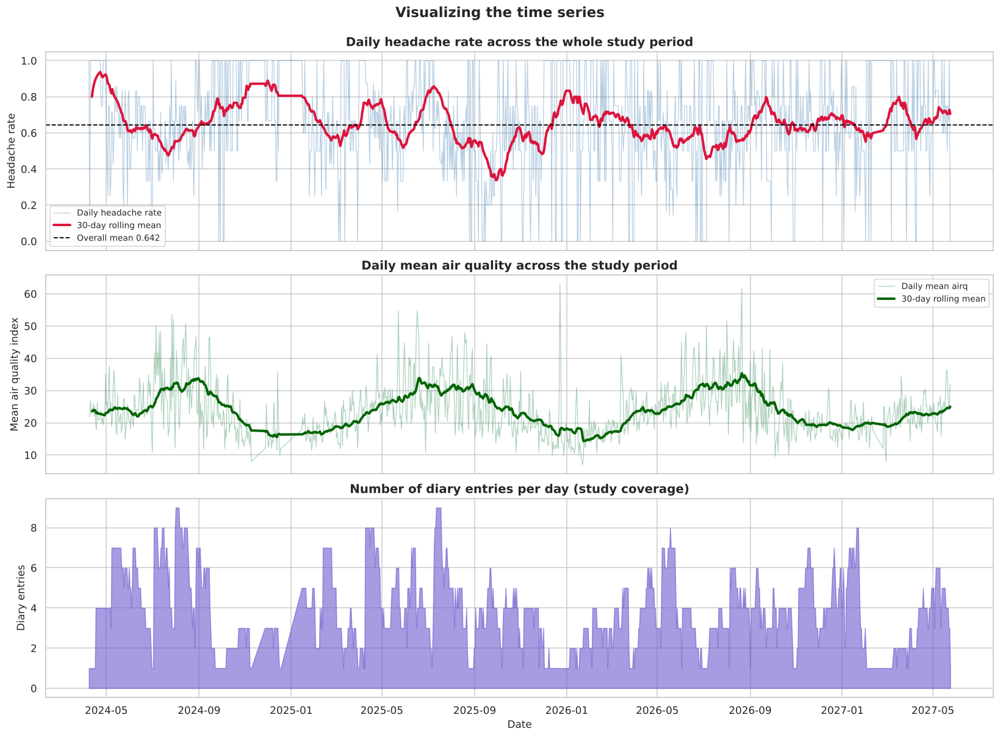

In [36]:
# Aggregate to a daily series: what fraction of diaries that day reported a headache?
daily = ts.groupby(ts.index).agg(
    headache_rate=("headache_bin", "mean"),
    n_patients=("id", "nunique"),
    mean_airq=("airq", "mean"),
    n_records=("headache_bin", "size")
)

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)

# (1) Headache rate over calendar time with a rolling mean
axes[0].plot(daily.index, daily["headache_rate"], lw=0.8, alpha=0.4,
             color="steelblue", label="Daily headache rate")
axes[0].plot(daily.index, daily["headache_rate"].rolling(30, min_periods=5).mean(),
             lw=2.6, color="crimson", label="30-day rolling mean")
axes[0].axhline(df["headache_bin"].mean(), color="black", ls="--", lw=1.2,
                label=f"Overall mean {df['headache_bin'].mean():.3f}")
axes[0].set_ylabel("Headache rate")
axes[0].set_title("Daily headache rate across the whole study period")
axes[0].legend(fontsize=9)

# (2) Air quality over time
axes[1].plot(daily.index, daily["mean_airq"], lw=0.8, alpha=0.4, color="seagreen",
             label="Daily mean airq")
axes[1].plot(daily.index, daily["mean_airq"].rolling(30, min_periods=5).mean(),
             lw=2.6, color="darkgreen", label="30-day rolling mean")
axes[1].set_ylabel("Mean air quality index")
axes[1].set_title("Daily mean air quality across the study period")
axes[1].legend(fontsize=9)

# (3) How many patients were actually reporting on each day
axes[2].fill_between(daily.index, daily["n_records"], color="slateblue", alpha=0.6)
axes[2].set_ylabel("Diary entries")
axes[2].set_xlabel("Date")
axes[2].set_title("Number of diary entries per day (study coverage)")

plt.suptitle("Visualizing the time series", fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

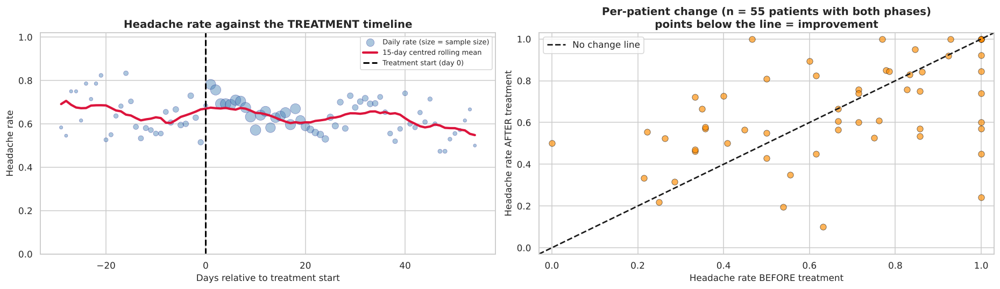

Patients who improved after treatment : 25 of 55 (45.5%)
Mean headache rate BEFORE : 0.6520
Mean headache rate AFTER  : 0.6475

Paired t-test (same patients, before vs after):
  t = +0.1296, p = 0.8973 -> no significant change


In [37]:
# The clinically meaningful axis: days relative to treatment start, not calendar date
by_time = df.groupby("time").agg(
    headache_rate=("headache_bin", "mean"),
    n=("headache_bin", "size")
)
by_time_reliable = by_time[by_time["n"] >= 10]   # ignore days with too few observations

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

axes[0].scatter(by_time_reliable.index, by_time_reliable["headache_rate"],
                s=by_time_reliable["n"]*1.4, alpha=0.45, color="steelblue",
                edgecolor="navy", linewidth=0.4, label="Daily rate (size = sample size)")
roll = by_time_reliable["headache_rate"].rolling(15, min_periods=3, center=True).mean()
axes[0].plot(by_time_reliable.index, roll, color="crimson", lw=2.8, label="15-day centred rolling mean")
axes[0].axvline(0, color="black", ls="--", lw=2, label="Treatment start (day 0)")
axes[0].set_xlabel("Days relative to treatment start")
axes[0].set_ylabel("Headache rate")
axes[0].set_title("Headache rate against the TREATMENT timeline")
axes[0].legend(fontsize=8.5)
axes[0].set_ylim(0, 1.02)

# Pre vs post comparison, done properly at the patient level
pre_post = (df.groupby(["id", "phase"])["headache_bin"].mean()
              .unstack()
              .dropna())
axes[1].scatter(pre_post["Pre-treatment"], pre_post["Post-treatment"],
                s=55, alpha=0.65, color="darkorange", edgecolor="black", linewidth=0.5)
lims = [-0.03, 1.03]
axes[1].plot(lims, lims, "k--", lw=1.8, label="No change line")
axes[1].set_xlim(lims); axes[1].set_ylim(lims)
axes[1].set_xlabel("Headache rate BEFORE treatment")
axes[1].set_ylabel("Headache rate AFTER treatment")
axes[1].set_title(f"Per-patient change (n = {len(pre_post)} patients with both phases)\n"
                  "points below the line = improvement")
axes[1].legend()

plt.tight_layout()
plt.show()

improved = (pre_post["Post-treatment"] < pre_post["Pre-treatment"]).sum()
print(f"Patients who improved after treatment : {improved} of {len(pre_post)} ({improved/len(pre_post):.1%})")
print(f"Mean headache rate BEFORE : {pre_post['Pre-treatment'].mean():.4f}")
print(f"Mean headache rate AFTER  : {pre_post['Post-treatment'].mean():.4f}")

t_stat, p_val = stats.ttest_rel(pre_post["Pre-treatment"], pre_post["Post-treatment"])
print(f"\nPaired t-test (same patients, before vs after):")
print(f"  t = {t_stat:+.4f}, p = {p_val:.4g} -> "
      f"{'a statistically significant reduction' if p_val < 0.05 else 'no significant change'}")

**This is the test I most expected to produce a result, and it did not.** Plotting against the
treatment timeline rather than the calendar is the right way to ask whether the intervention made a
difference, and the per-patient scatter on the right is the rigorous version of the question: each
point is one patient compared **against themselves**, which controls for every between-patient
difference that a group average would confound.

**The answer is no detectable change.** The mean headache rate before treatment is 0.652 and after
treatment 0.648 — a difference of less than half a percentage point. Only 25 of the 55 patients with
data in both phases improved, which is slightly *fewer* than half, and the paired t-test gives
p = 0.897. The points scatter symmetrically around the no-change line rather than falling below it.

I want to be careful not to overstate this in the other direction either. A null result here does not
prove the treatment does nothing, because:

- Only 55 of 133 patients have observations in **both** phases, so the test is underpowered.
- The pre-treatment window is short — most of the dataset sits after day 0 — so the "before" estimate
  for each patient rests on relatively few days.
- Patients may have entered the programme at different stages of their condition.

What I can say is that **this dataset provides no evidence of a before/after reduction**, and that
had I only looked at the smoothed rolling curve without running the paired test at the patient level,
I could easily have talked myself into seeing a decline that the statistics do not support.

## 5.6 Grouping Time Series Data

In [38]:
print("GROUPING THE TIME SERIES")
print("="*70)

# --- Group by day of the week ---
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_dow = ts.groupby("day_of_week").agg(
    headache_rate=("headache_bin", "mean"),
    mean_airq=("airq", "mean"),
    n=("headache_bin", "size")
).reindex(dow_order)

print("\nGrouped by day of the week:")
display(by_dow.round(4))

# --- Group by month ---
by_month = ts.groupby("month").agg(
    headache_rate=("headache_bin", "mean"),
    mean_airq=("airq", "mean"),
    n=("headache_bin", "size")
)
print("\nGrouped by month:")
display(by_month.round(4).head(14))

GROUPING THE TIME SERIES

Grouped by day of the week:


,headache_rate,mean_airq,n
day_of_week,,,
Monday,0.6261,24.1672,567
Tuesday,0.6412,24.0359,524
Wednesday,0.6613,24.5426,617
Thursday,0.6383,24.9450,622
Friday,0.6106,25.1125,624
Saturday,0.6628,25.1924,608
Sunday,0.6553,25.6455,589



Grouped by month:


,headache_rate,mean_airq,n
month,,,
2024-04,0.9385,22.5385,65
2024-05,0.6354,23.6519,181
2024-06,0.6090,24.9158,133
2024-07,0.5278,31.9900,180
2024-08,0.6522,33.3768,207
2024-09,0.7222,26.1574,108
2024-10,0.8308,19.2923,65
2024-11,0.8750,16.5000,32
2024-12,0.7174,17.0000,46


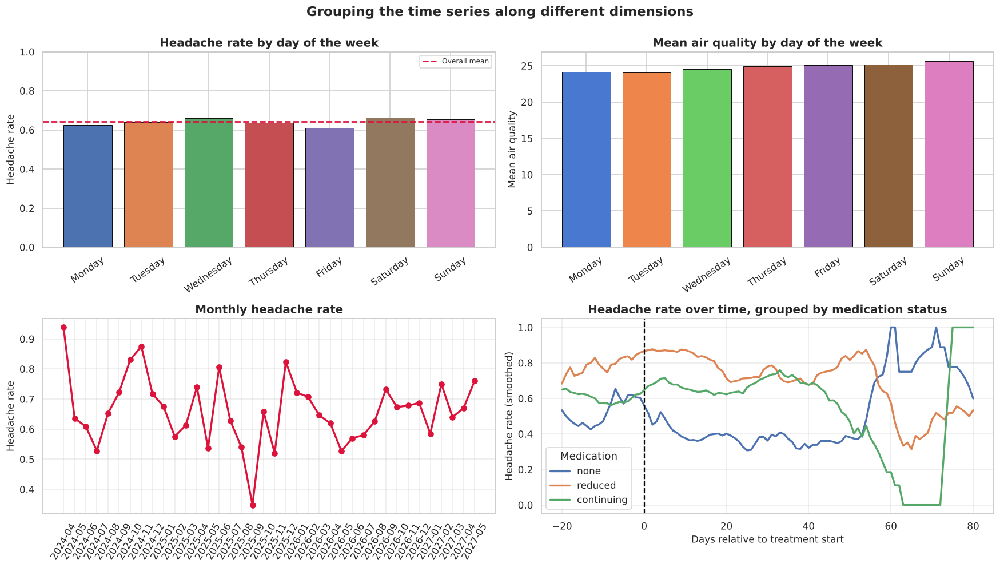

Chi-square test for day-of-week effect: chi2 = 5.9447, dof = 6, p = 0.4294
-> No detectable weekly pattern - the variation is consistent with random noise.


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# Day-of-week headache rate
bars = axes[0,0].bar(by_dow.index, by_dow["headache_rate"],
                     color=sns.color_palette("deep")[:7], edgecolor="black", linewidth=0.6)
axes[0,0].axhline(df["headache_bin"].mean(), color="crimson", ls="--", lw=1.8, label="Overall mean")
axes[0,0].set_ylabel("Headache rate")
axes[0,0].set_title("Headache rate by day of the week")
axes[0,0].tick_params(axis="x", rotation=35)
axes[0,0].legend(fontsize=8)
axes[0,0].set_ylim(0, 1)

# Day-of-week air quality
axes[0,1].bar(by_dow.index, by_dow["mean_airq"],
              color=sns.color_palette("muted")[:7], edgecolor="black", linewidth=0.6)
axes[0,1].set_ylabel("Mean air quality")
axes[0,1].set_title("Mean air quality by day of the week")
axes[0,1].tick_params(axis="x", rotation=35)

# Monthly headache rate
axes[1,0].plot(by_month.index.astype(str), by_month["headache_rate"],
               marker="o", lw=2.2, color="crimson")
axes[1,0].set_ylabel("Headache rate")
axes[1,0].set_title("Monthly headache rate")
axes[1,0].tick_params(axis="x", rotation=60)
axes[1,0].grid(alpha=0.4)

# Grouped by medication status over the treatment timeline
med_time = (df[df["time"].between(-20, 80)]
              .groupby(["time", "medication"])["headache_bin"].mean().unstack())
for col in ["none", "reduced", "continuing"]:
    if col in med_time:
        axes[1,1].plot(med_time.index,
                       med_time[col].rolling(9, min_periods=2, center=True).mean(),
                       lw=2.2, label=col)
axes[1,1].axvline(0, color="black", ls="--", lw=1.5)
axes[1,1].set_xlabel("Days relative to treatment start")
axes[1,1].set_ylabel("Headache rate (smoothed)")
axes[1,1].set_title("Headache rate over time, grouped by medication status")
axes[1,1].legend(title="Medication")
axes[1,1].grid(alpha=0.4)

plt.suptitle("Grouping the time series along different dimensions",
             fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

# Is the day-of-week variation real, or just noise?
dow_ct = pd.crosstab(ts["day_of_week"].to_numpy(), ts["headache"].to_numpy())
chi2, p, dof, _ = stats.chi2_contingency(dow_ct)
print(f"Chi-square test for day-of-week effect: chi2 = {chi2:.4f}, dof = {dof}, p = {p:.4g}")
print("->", "There IS a detectable weekly pattern." if p < 0.05
      else "No detectable weekly pattern - the variation is consistent with random noise.")

**Grouping observation.** The day-of-week bars look slightly uneven to the eye, but the chi-square
test settles it: chi-square = 5.94 on 6 degrees of freedom, p = 0.43. **There is no weekly pattern** —
the variation across days is entirely consistent with random noise. This is precisely why I tested
rather than eyeballing; small visual differences across seven categories are very easy to over-read.

Two further points. Because the "weekday" here derives from my arbitrary anchor date rather than real
calendar weekdays, even a significant result would have meant a 7-day rhythm in the study design, not
a genuine Monday-versus-Sunday effect. And the bottom-right panel is the more informative one: the
headache rate over the treatment timeline, split by medication status, keeps the three medication
groups clearly separated along the whole timeline — reinforcing that medication status is tracking a
persistent patient characteristic rather than a day-to-day effect.

## 5.7 Resampling the Time Series

Resampling changes the frequency of a time series. **Downsampling** (daily → weekly → monthly)
reduces noise and exposes trend; **upsampling** increases frequency and requires interpolation. This
is only possible because I built a proper `DatetimeIndex` in Section 5.4.

In [40]:
print("RESAMPLING")
print("="*70)

daily_series = ts["headache_bin"].resample("D").mean()
airq_daily   = ts["airq"].resample("D").mean()

weekly   = ts["headache_bin"].resample("W").mean()
biweekly = ts["headache_bin"].resample("2W").mean()
monthly  = ts["headache_bin"].resample("ME").mean()
quarterly= ts["headache_bin"].resample("QE").mean()

print(f"Original daily observations : {daily_series.notna().sum():,} days with data")
print(f"After weekly    resampling  : {weekly.notna().sum():,} weeks")
print(f"After bi-weekly resampling  : {biweekly.notna().sum():,} fortnights")
print(f"After monthly   resampling  : {monthly.notna().sum():,} months")
print(f"After quarterly resampling  : {quarterly.notna().sum():,} quarters")

print("\nVariance at each frequency (downsampling smooths out noise):")
for name, s in [("Daily", daily_series), ("Weekly", weekly),
                ("Bi-weekly", biweekly), ("Monthly", monthly)]:
    print(f"  {name:10s}: variance = {s.var():.6f}")

RESAMPLING
Original daily observations : 1,080 days with data
After weekly    resampling  : 158 weeks
After bi-weekly resampling  : 81 fortnights
After monthly   resampling  : 38 months
After quarterly resampling  : 13 quarters

Variance at each frequency (downsampling smooths out noise):
  Daily     : variance = 0.077829
  Weekly    : variance = 0.025325
  Bi-weekly : variance = 0.022416
  Monthly   : variance = 0.012558


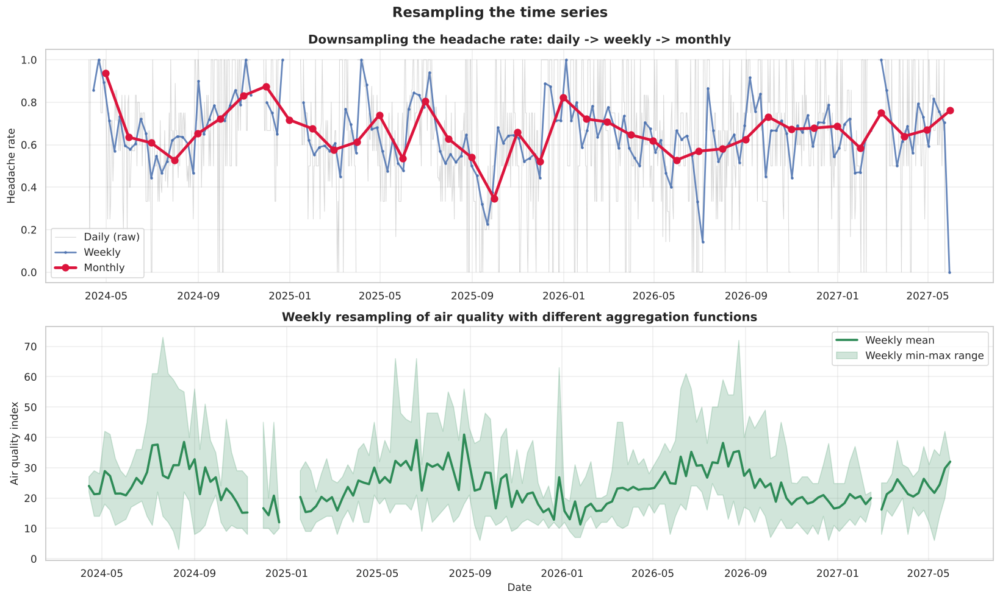

In [41]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

axes[0].plot(daily_series.index, daily_series, lw=0.7, alpha=0.3, color="gray", label="Daily (raw)")
axes[0].plot(weekly.index, weekly, lw=1.8, alpha=0.85, marker=".", markersize=4, label="Weekly")
axes[0].plot(monthly.index, monthly, lw=3.0, marker="o", markersize=7, color="crimson", label="Monthly")
axes[0].set_ylabel("Headache rate")
axes[0].set_title("Downsampling the headache rate: daily -> weekly -> monthly")
axes[0].legend()
axes[0].grid(alpha=0.35)

# Aggregation choice matters: mean vs max vs min at the same frequency
agg_week = ts["airq"].resample("W").agg(["mean", "max", "min"])
axes[1].plot(agg_week.index, agg_week["mean"], lw=2.4, color="seagreen", label="Weekly mean")
axes[1].fill_between(agg_week.index, agg_week["min"], agg_week["max"],
                     alpha=0.22, color="seagreen", label="Weekly min-max range")
axes[1].set_ylabel("Air quality index")
axes[1].set_xlabel("Date")
axes[1].set_title("Weekly resampling of air quality with different aggregation functions")
axes[1].legend()
axes[1].grid(alpha=0.35)

plt.suptitle("Resampling the time series", fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

UPSAMPLING (monthly -> daily, with interpolation)


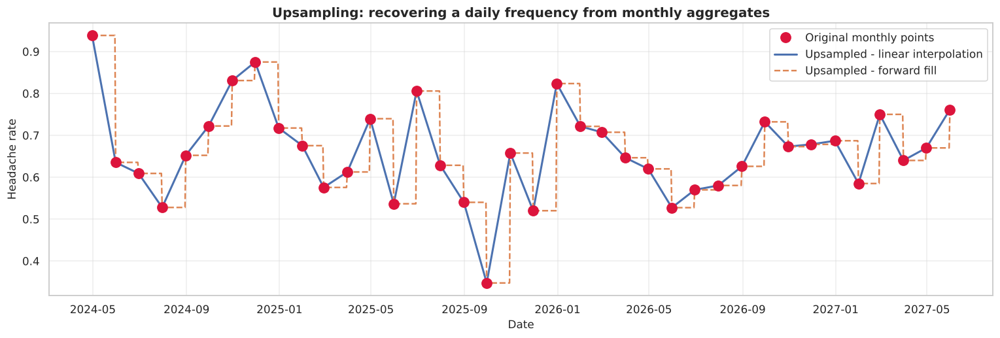

Monthly points : 38
After upsampling to daily: 1,127 points

Note: upsampling does NOT create new information. The interpolated values are
assumptions about what happened between the known points, not measurements.


In [42]:
# Upsampling + interpolation, demonstrated on the monthly series
print("UPSAMPLING (monthly -> daily, with interpolation)")
print("="*70)

monthly_clean = monthly.dropna()
up_linear = monthly_clean.resample("D").interpolate(method="linear")
up_ffill  = monthly_clean.resample("D").ffill()

plt.figure(figsize=(14, 4.8))
plt.plot(monthly_clean.index, monthly_clean, "o", markersize=10,
         color="crimson", label="Original monthly points", zorder=5)
plt.plot(up_linear.index, up_linear, lw=2.0, label="Upsampled - linear interpolation")
plt.plot(up_ffill.index, up_ffill, lw=1.6, ls="--", label="Upsampled - forward fill")
plt.ylabel("Headache rate")
plt.xlabel("Date")
plt.title("Upsampling: recovering a daily frequency from monthly aggregates")
plt.legend()
plt.grid(alpha=0.35)
plt.tight_layout()
plt.show()

print(f"Monthly points : {len(monthly_clean)}")
print(f"After upsampling to daily: {len(up_linear):,} points")
print("\nNote: upsampling does NOT create new information. The interpolated values are")
print("assumptions about what happened between the known points, not measurements.")

**Resampling observation.** The variance table makes the main point numerically: variance falls
monotonically as I downsample from daily to monthly. That is the noise-versus-signal trade-off in
action. The daily series is dominated by sampling noise, since on some days only a handful of
patients were reporting and a single person's headache swings the rate wildly. The monthly series is
stable enough to show trend but has so few points that I could not fit anything meaningful to it. For
this dataset the **weekly** frequency is the sweet spot.

The upsampling demonstration is included for completeness, but I want to flag what it really is: the
interpolated daily values are manufactured, not observed. Upsampling is a formatting operation for
aligning series of different frequencies — it never adds information.

---

# MODULE 4 — Data Summarization and Visualization

> **Syllabus:** Statistical summary measures, data elaboration, 1-D Statistical data analysis, 2-D
> Statistical data analysis, contingency tables, n-D Statistical data analysis. Visualization:
> Scatter plots — Dot charts — Bar plots.

## 6.1 Statistical Summary Measures

I organise the summary measures into the three standard families rather than dumping a single
`describe()` table, because each family answers a different question: *where is the data*, *how
spread out is it*, and *what shape is it*.

In [43]:
print("COMPREHENSIVE STATISTICAL SUMMARY MEASURES")
print("="*70)

def full_summary(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return pd.Series({
        # --- Measures of CENTRAL TENDENCY ---
        "Count": len(s),
        "Mean": s.mean(),
        "Median": s.median(),
        "Mode": s.mode().iloc[0],
        "Trimmed mean (10%)": stats.trim_mean(s, 0.1),
        "Geometric mean": stats.gmean(s[s > 0]) if (s > 0).any() else np.nan,
        # --- Measures of DISPERSION ---
        "Std deviation": s.std(),
        "Variance": s.var(),
        "Range": s.max() - s.min(),
        "IQR": iqr,
        "MAD (median abs dev)": stats.median_abs_deviation(s),
        "Coeff. of variation %": s.std() / s.mean() * 100 if s.mean() != 0 else np.nan,
        "Std error of mean": s.sem(),
        # --- Measures of SHAPE ---
        "Skewness": s.skew(),
        "Kurtosis (excess)": s.kurtosis(),
        # --- Measures of POSITION ---
        "Min": s.min(),
        "P5": s.quantile(0.05),
        "Q1 (P25)": q1,
        "Q3 (P75)": q3,
        "P95": s.quantile(0.95),
        "Max": s.max(),
    })

summary_table = pd.DataFrame({c: full_summary(df[c]) for c in ["age", "airq", "time", "dos"]})
display(summary_table.round(4))

COMPREHENSIVE STATISTICAL SUMMARY MEASURES


,age,airq,time,dos
Count,"4,151.0000","4,151.0000","4,151.0000","4,151.0000"
Mean,42.3664,24.8250,15.4553,646.6517
Median,44.0000,24.0000,12.0000,623.0000
Mode,46.0000,24.8000,5.0000,213.0000
Trimmed mean (10%),42.5059,23.8882,13.6600,643.5092
Geometric mean,40.7272,23.1449,13.9194,538.1051
Std deviation,11.2014,9.5152,21.7398,335.7924
Variance,125.4722,90.5390,472.6196,"112,756.5085"
Range,48.0000,70.0000,128.0000,"1,141.0000"
IQR,17.0000,11.0000,21.0000,566.0000


NORMALITY ASSESSMENT


,Variable,Shapiro-Wilk W,SW p,K-S stat,KS p,Jarque-Bera,JB p,Skewness,Verdict
0,age,0.9793,0.0000,0.0873,0.0000,98.4588,0.0000,-0.1530,Not normal
1,airq,0.9383,0.0000,0.1347,0.0000,"1,293.1233",0.0000,1.0759,Not normal


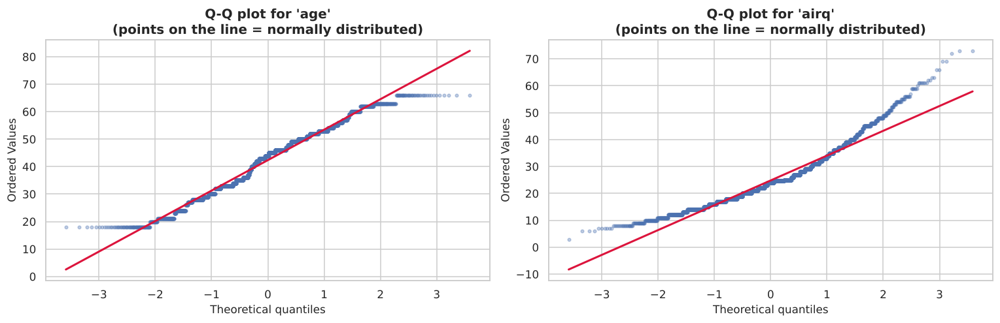

In [44]:
# Normality assessment - this decides which later tests are valid
print("NORMALITY ASSESSMENT")
print("="*70)

norm_rows = []
for col in ["age", "airq"]:
    sample = df[col].sample(min(5000, len(df)), random_state=RANDOM_STATE)
    sw_stat, sw_p = stats.shapiro(sample)
    ks_stat, ks_p = stats.kstest(stats.zscore(df[col]), "norm")
    jb_stat, jb_p = stats.jarque_bera(df[col])
    norm_rows.append({
        "Variable": col,
        "Shapiro-Wilk W": sw_stat, "SW p": sw_p,
        "K-S stat": ks_stat, "KS p": ks_p,
        "Jarque-Bera": jb_stat, "JB p": jb_p,
        "Skewness": df[col].skew(),
        "Verdict": "Not normal" if sw_p < 0.05 else "Consistent with normal"
    })

display(pd.DataFrame(norm_rows).round(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, col in zip(axes, ["age", "airq"]):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot for '{col}'\n(points on the line = normally distributed)")
    ax.get_lines()[0].set_markersize(3)
    ax.get_lines()[0].set_alpha(0.35)
    ax.get_lines()[1].set_color("crimson")
    ax.get_lines()[1].set_linewidth(2)
plt.tight_layout()
plt.show()

**Normality observation.** Both variables fail the formal normality tests, but the Q-Q plots show
*why* in two different ways. `age` departs mainly at the tails while its body sits close to the
reference line — a mild departure that large-sample methods tolerate well. `airq` curves away
distinctly at the upper end, which is the right-skew and the heavy tail I saw earlier.

I also want to be honest about a limitation of these tests: with n > 4,000, Shapiro-Wilk will reject
normality for almost any real data, because it detects departures far too small to matter. So I
weight the **Q-Q plots and the skewness values** more heavily than the p-values. Practically, this
means I prefer non-parametric comparisons and robust statistics for `airq`, and I keep the
`StandardScaler` step before every distance-based method later on.

## 6.2 Data Elaboration

Data elaboration means deriving new, more informative variables from the raw ones. For a
longitudinal dataset the single most valuable elaboration is **aggregating from patient-days up to
patients** — this gives me a 133-row table where each row is a person, which is the right unit for
clustering (Module 5), dimensionality reduction (Module 6) and patient-level regression (Module 7).

In [45]:
print("DATA ELABORATION - building a patient-level feature table")
print("="*70)

patient = df.groupby("id").agg(
    age              = ("age", "first"),
    sex              = ("sex", "first"),
    hatype           = ("hatype", "first"),
    n_days           = ("headache_bin", "size"),
    headache_days    = ("headache_bin", "sum"),
    headache_rate    = ("headache_bin", "mean"),
    mean_airq        = ("airq", "mean"),
    std_airq         = ("airq", "std"),
    max_airq         = ("airq", "max"),
    first_day        = ("time", "min"),
    last_day         = ("time", "max"),
    med_ord_mean     = ("medication_ord", "mean"),
).reset_index()

patient["study_length"] = patient["last_day"] - patient["first_day"]
patient["std_airq"] = patient["std_airq"].fillna(0)

# Pre / post treatment headache rates per patient
pre = df[df["time"] < 0].groupby("id")["headache_bin"].mean().rename("pre_rate")
post = df[df["time"] >= 0].groupby("id")["headache_bin"].mean().rename("post_rate")
patient = patient.merge(pre, on="id", how="left").merge(post, on="id", how="left")
patient["rate_change"] = patient["post_rate"] - patient["pre_rate"]

# Longest run of consecutive headache days - a severity measure the raw data does not contain
def longest_streak(group):
    v = group.sort_values("time")["headache_bin"].to_numpy()
    best = cur = 0
    for x in v:
        cur = cur + 1 if x == 1 else 0
        best = max(best, cur)
    return best

patient["longest_streak"] = df.groupby("id").apply(longest_streak).values

print(f"Elaborated patient table: {patient.shape[0]} patients x {patient.shape[1]} features")
display(patient.head(10).round(4))

DATA ELABORATION - building a patient-level feature table
Elaborated patient table: 133 patients x 18 features


,id,age,sex,hatype,n_days,headache_days,headache_rate,mean_airq,std_airq,max_airq,first_day,last_day,med_ord_mean,study_length,pre_rate,post_rate,rate_change,longest_streak
0,1,30,female,Aura,20,19,0.9500,17.1000,5.2103,29.0000,-11,35,2.0000,46,1.0000,0.9231,-0.0769,12
1,2,36,female,Aura,45,43,0.9556,22.4000,6.4435,41.0000,1,84,2.0000,83,NaN,0.9556,NaN,24
2,3,28,female,Aura,70,9,0.1286,24.4571,8.1892,45.0000,1,70,2.0000,69,NaN,0.1286,NaN,1
3,4,33,female,Aura,33,29,0.8788,25.0606,7.1324,42.0000,1,34,2.0000,33,NaN,0.8788,NaN,15
4,5,63,female,Aura,60,53,0.8833,25.0333,5.4086,41.0000,1,60,1.0000,59,NaN,0.8833,NaN,16
5,6,62,female,Aura,32,19,0.5938,24.2500,5.3280,41.0000,1,32,2.0000,31,NaN,0.5938,NaN,6
6,7,42,female,Aura,56,26,0.4643,21.5000,5.6953,40.0000,1,56,2.0000,55,NaN,0.4643,NaN,7
7,8,43,female,Aura,16,16,1.0000,34.1250,9.7014,53.0000,2,17,2.0000,15,NaN,1.0000,NaN,16
8,9,43,female,Aura,26,19,0.7308,24.8000,0.0000,24.8000,28,53,2.0000,25,NaN,0.7308,NaN,9
9,10,30,female,Aura,80,68,0.8500,25.8125,5.7832,45.0000,-29,52,2.0000,81,0.8621,0.8431,-0.0189,24


In [46]:
print("Summary of the elaborated patient-level features:")
display(patient[["age", "n_days", "headache_rate", "mean_airq",
                 "longest_streak", "rate_change", "study_length"]].describe().T.round(4))

Summary of the elaborated patient-level features:


,count,mean,std,min,25%,50%,75%,max
age,133.0000,42.1579,11.3630,18.0000,33.0000,44.0000,50.0000,66.0000
n_days,133.0000,31.2105,17.4200,7.0000,19.0000,26.0000,38.0000,121.0000
headache_rate,133.0000,0.6432,0.2683,0.0000,0.4412,0.6667,0.8833,1.0000
mean_airq,133.0000,24.8691,5.7796,13.8333,20.0000,24.8000,28.3306,38.5417
longest_streak,133.0000,10.2857,8.4920,0.0000,4.0000,7.0000,16.0000,41.0000
rate_change,55.0000,-0.0045,0.2598,-0.7586,-0.1331,0.0000,0.1327,0.5333
study_length,133.0000,36.7444,23.0466,6.0000,19.0000,31.0000,46.0000,128.0000


## 6.3 1-D Statistical Data Analysis

One-dimensional analysis characterises a single variable completely. I take `headache_rate` from the
patient table as the lead example, because it is the variable the whole project is about and it only
exists after the elaboration step above.

In [47]:
target = patient["headache_rate"]

print("1-D ANALYSIS OF PATIENT HEADACHE RATE")
print("="*70)
print(f"  n                   : {len(target)}")
print(f"  Mean                : {target.mean():.4f}")
print(f"  Median              : {target.median():.4f}")
print(f"  Std deviation       : {target.std():.4f}")
print(f"  Skewness            : {target.skew():.4f}")
print(f"  Kurtosis            : {target.kurtosis():.4f}")
print(f"  95% CI for the mean : [{target.mean() - 1.96*target.sem():.4f}, "
      f"{target.mean() + 1.96*target.sem():.4f}]")

print("\n  Decile breakdown:")
for q in np.arange(0.1, 1.0, 0.1):
    print(f"    {int(q*100):3d}th percentile: {target.quantile(q):.4f}")

1-D ANALYSIS OF PATIENT HEADACHE RATE
  n                   : 133
  Mean                : 0.6432
  Median              : 0.6667
  Std deviation       : 0.2683
  Skewness            : -0.3929
  Kurtosis            : -0.8679
  95% CI for the mean : [0.5976, 0.6888]

  Decile breakdown:
     10th percentile: 0.2737
     20th percentile: 0.4138
     30th percentile: 0.4699
     40th percentile: 0.5926
     50th percentile: 0.6667
     60th percentile: 0.7651
     70th percentile: 0.8301
     80th percentile: 0.8979
     90th percentile: 1.0000


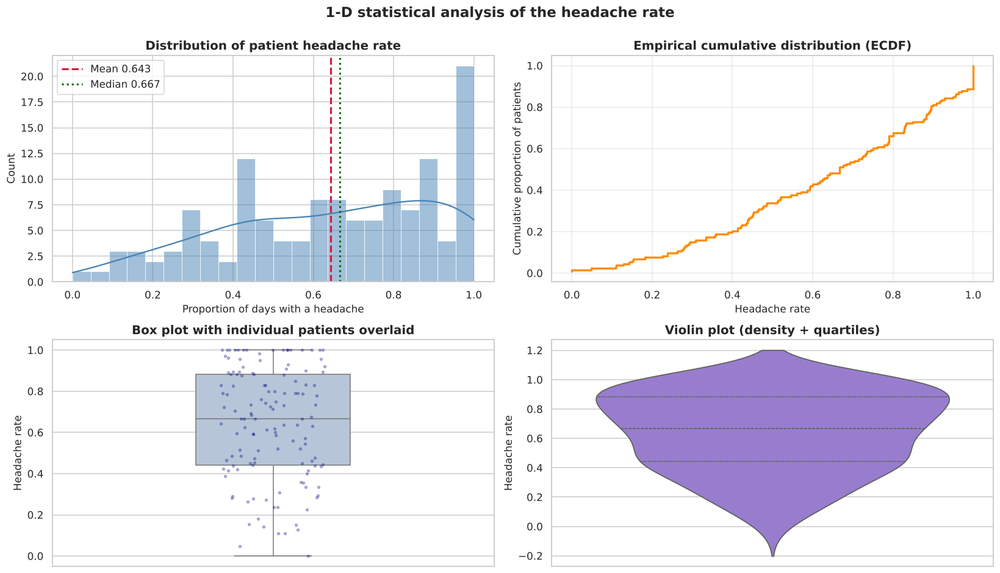

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))

# Histogram + KDE
sns.histplot(target, bins=22, kde=True, ax=axes[0,0], color="steelblue",
             edgecolor="white", linewidth=0.5)
axes[0,0].axvline(target.mean(), color="crimson", ls="--", lw=2, label=f"Mean {target.mean():.3f}")
axes[0,0].axvline(target.median(), color="darkgreen", ls=":", lw=2, label=f"Median {target.median():.3f}")
axes[0,0].set_title("Distribution of patient headache rate")
axes[0,0].set_xlabel("Proportion of days with a headache")
axes[0,0].legend()

# Empirical CDF
sorted_v = np.sort(target)
axes[0,1].step(sorted_v, np.arange(1, len(sorted_v)+1)/len(sorted_v), lw=2.2, color="darkorange")
axes[0,1].set_title("Empirical cumulative distribution (ECDF)")
axes[0,1].set_xlabel("Headache rate")
axes[0,1].set_ylabel("Cumulative proportion of patients")
axes[0,1].grid(alpha=0.4)

# Box + strip
sns.boxplot(y=target, ax=axes[1,0], color="lightsteelblue", width=0.35)
sns.stripplot(y=target, ax=axes[1,0], color="navy", alpha=0.35, size=3.5, jitter=0.12)
axes[1,0].set_title("Box plot with individual patients overlaid")
axes[1,0].set_ylabel("Headache rate")

# Violin
sns.violinplot(y=target, ax=axes[1,1], color="mediumpurple", inner="quartile")
axes[1,1].set_title("Violin plot (density + quartiles)")
axes[1,1].set_ylabel("Headache rate")

plt.suptitle("1-D statistical analysis of the headache rate", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**1-D observation.** The distribution of patient headache rates is wide and **close to uniform in the
middle with a pile-up near 1.0** — a noticeable group of patients had a headache on essentially every
day they recorded. This heterogeneity is the single most important structural fact for the rest of
the project: these patients are not one homogeneous population with a common rate plus noise, they
span the full range from occasional to near-daily sufferers. That is precisely the kind of structure
that clustering in Module 5 should be able to pick up, and it is why a model that predicts only from
daily variables will struggle — the patient identity itself carries most of the signal.

## 6.4 2-D Statistical Data Analysis and Contingency Tables

In [49]:
print("2-D ANALYSIS: CONTINGENCY TABLES")
print("="*70)

# Full contingency table with margins
ct_full = pd.crosstab(df["hatype"], df["headache"], margins=True, margins_name="TOTAL")
print("\n(a) Raw frequency contingency table: hatype x headache")
display(ct_full)

print("\n(b) Row percentages (what fraction of EACH headache type are headache days?)")
display((pd.crosstab(df["hatype"], df["headache"], normalize="index") * 100).round(2))

print("\n(c) Column percentages (what fraction of headache days come from EACH type?)")
display((pd.crosstab(df["hatype"], df["headache"], normalize="columns") * 100).round(2))

print("\n(d) Overall percentages (each cell as a share of all observations)")
display((pd.crosstab(df["hatype"], df["headache"], normalize="all") * 100).round(2))

2-D ANALYSIS: CONTINGENCY TABLES

(a) Raw frequency contingency table: hatype x headache


headache,no,yes,TOTAL
hatype,,,
Aura,581,1129,1710
Mixed,96,361,457
No Aura,808,1176,1984
TOTAL,1485,2666,4151



(b) Row percentages (what fraction of EACH headache type are headache days?)


headache,no,yes
hatype,,
Aura,33.9800,66.0200
Mixed,21.0100,78.9900
No Aura,40.7300,59.2700



(c) Column percentages (what fraction of headache days come from EACH type?)


headache,no,yes
hatype,,
Aura,39.1200,42.3500
Mixed,6.4600,13.5400
No Aura,54.4100,44.1100



(d) Overall percentages (each cell as a share of all observations)


headache,no,yes
hatype,,
Aura,14.0000,27.2000
Mixed,2.3100,8.7000
No Aura,19.4700,28.3300


In [50]:
# Expected frequencies and residual analysis - which cells drive the chi-square?
ct = pd.crosstab(df["medication"], df["headache"])
chi2, p, dof, expected = stats.chi2_contingency(ct)
expected_df = pd.DataFrame(expected, index=ct.index, columns=ct.columns)

# Standardised residuals: (observed - expected) / sqrt(expected)
residuals = (ct - expected_df) / np.sqrt(expected_df)

print("CONTINGENCY TABLE ANALYSIS: medication x headache")
print("="*70)
print("\nObserved frequencies:")
display(ct)
print("\nExpected frequencies under the hypothesis of independence:")
display(expected_df.round(2))
print("\nStandardised residuals (|value| > 2 marks a cell that deviates strongly):")
display(residuals.round(3))

print(f"\nChi-square = {chi2:.4f}, dof = {dof}, p = {p:.4g}")
print(f"Cramer's V = {np.sqrt((chi2/len(df)) / (min(ct.shape)-1)):.4f}")

CONTINGENCY TABLE ANALYSIS: medication x headache

Observed frequencies:


headache,no,yes
medication,,
continuing,825,1561
none,440,345
reduced,220,760



Expected frequencies under the hypothesis of independence:


headache,no,yes
medication,,
continuing,853.5800,"1,532.4200"
none,280.8300,504.1700
reduced,350.5900,629.4100



Standardised residuals (|value| > 2 marks a cell that deviates strongly):


headache,no,yes
medication,,
continuing,-0.9780,0.7300
none,9.4980,-7.0890
reduced,-6.9740,5.2050



Chi-square = 217.6943, dof = 2, p = 5.349e-48
Cramer's V = 0.2290


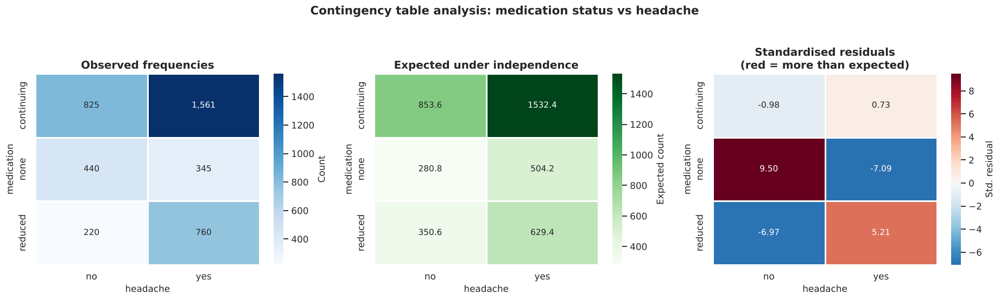

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", linewidths=0.8, ax=axes[0],
            cbar_kws={"label": "Count"})
axes[0].set_title("Observed frequencies")

sns.heatmap(expected_df, annot=True, fmt=".1f", cmap="Greens", linewidths=0.8, ax=axes[1],
            cbar_kws={"label": "Expected count"})
axes[1].set_title("Expected under independence")

sns.heatmap(residuals, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.8,
            ax=axes[2], cbar_kws={"label": "Std. residual"})
axes[2].set_title("Standardised residuals\n(red = more than expected)")

plt.suptitle("Contingency table analysis: medication status vs headache",
             fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

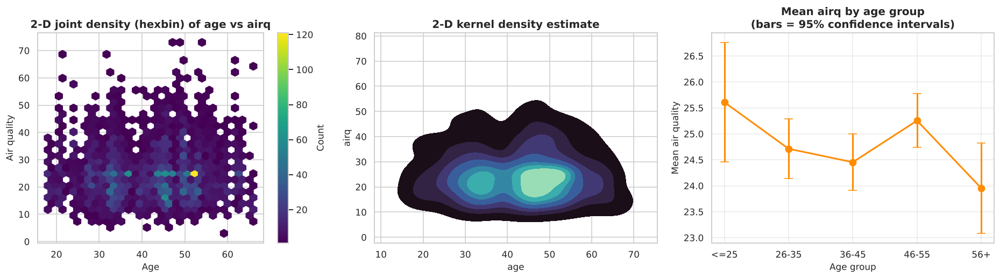

In [52]:
# 2-D analysis of two NUMERICAL variables, done properly
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Joint density
hb = axes[0].hexbin(df["age"], df["airq"], gridsize=28, cmap="viridis", mincnt=1)
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Air quality")
axes[0].set_title("2-D joint density (hexbin) of age vs airq")
plt.colorbar(hb, ax=axes[0], label="Count")

# 2-D KDE contours
sns.kdeplot(data=df.sample(2000, random_state=RANDOM_STATE), x="age", y="airq",
            fill=True, cmap="mako", levels=8, ax=axes[1])
axes[1].set_title("2-D kernel density estimate")

# Binned relationship with error bars
binned = df.groupby("age_group", observed=True)["airq"].agg(["mean", "sem", "count"])
axes[2].errorbar(range(len(binned)), binned["mean"], yerr=1.96*binned["sem"],
                 fmt="o-", capsize=5, lw=2, markersize=8, color="darkorange")
axes[2].set_xticks(range(len(binned)))
axes[2].set_xticklabels(binned.index.astype(str))
axes[2].set_xlabel("Age group"); axes[2].set_ylabel("Mean air quality")
axes[2].set_title("Mean airq by age group\n(bars = 95% confidence intervals)")
axes[2].grid(alpha=0.4)

plt.tight_layout()
plt.show()

**2-D observation.** The standardised-residual heatmap is the most diagnostic output here. It does
not just say the medication–headache association is significant; it says **where** the association
lives, and the answer is not where I would have guessed.

The dominant cell by far is `none` / **no headache**, with a residual of **+9.50** — headache-free
days are massively over-represented among patients who have stopped medication. Its mirror,
`none` / headache, sits at -7.09. The second strongest is `reduced` / headache at **+5.21**, with
`reduced` / no headache at -6.97.

The striking part is that the `continuing` row has residuals of only **-0.98 and +0.73** — close to
what independence would predict. So the association is **not** a gradient running along the
medication scale at all. It is driven almost entirely by the two ends of the taper behaving
unusually: the `none` group being far healthier than chance, and the `reduced` group being
sicker than chance. The `continuing` group is unremarkable. A single chi-square number would have
hidden this completely, and so would the "medication gradient" story I would have told from the bar
chart alone.

The hexbin and KDE panels, by contrast, show a featureless blob — `age` and `airq` are genuinely
unrelated (r = -0.009), with no hidden non-linear structure that the correlation coefficient might
have missed.

## 6.5 n-D Statistical Data Analysis

n-dimensional analysis handles all variables simultaneously. Beyond the correlation matrix, I use
three tools here: the covariance structure, the **variance inflation factor** to quantify
multicollinearity, and **Mahalanobis distance** to find multivariate outliers — points that are not
extreme on any single variable but are unusual in combination.

In [53]:
print("n-D ANALYSIS")
print("="*70)

nd_cols = ["age", "airq", "time", "dos", "headache_bin", "sex_bin", "medication_ord"]
X_nd = df[nd_cols]

print("\n(a) Covariance matrix:")
display(X_nd.cov().round(3))

print("\n(b) Variance Inflation Factors (VIF) - how much each variable is explained by the others:")
from sklearn.linear_model import LinearRegression as _LR
vif_rows = []
Xs = StandardScaler().fit_transform(X_nd)
for i, col in enumerate(nd_cols):
    y_i = Xs[:, i]
    X_i = np.delete(Xs, i, axis=1)
    r2 = _LR().fit(X_i, y_i).score(X_i, y_i)
    vif = 1 / (1 - r2) if r2 < 0.9999 else np.inf
    vif_rows.append({"Variable": col, "R-squared from others": r2, "VIF": vif,
                     "Multicollinearity": "SEVERE" if vif > 10 else "moderate" if vif > 5 else "fine"})
display(pd.DataFrame(vif_rows).round(4))

n-D ANALYSIS

(a) Covariance matrix:


,age,airq,time,dos,headache_bin,sex_bin,medication_ord
age,125.4720,-0.9660,-13.5810,80.1190,-0.3180,0.3400,-0.3490
airq,-0.9660,90.5390,-0.5250,-415.4160,0.0660,-0.0510,-0.3760
time,-13.5810,-0.5250,472.6200,-627.7570,-0.3960,1.3050,-3.2510
dos,80.1190,-415.4160,-627.7570,"112,756.5090",-0.7910,20.0340,3.5340
headache_bin,-0.3180,0.0660,-0.3960,-0.7910,0.2300,-0.0010,0.0450
sex_bin,0.3400,-0.0510,1.3050,20.0340,-0.0010,0.1250,-0.0470
medication_ord,-0.3490,-0.3760,-3.2510,3.5340,0.0450,-0.0470,0.6150



(b) Variance Inflation Factors (VIF) - how much each variable is explained by the others:


,Variable,R-squared from others,VIF,Multicollinearity
0,age,0.0173,1.0176,fine
1,airq,0.0203,1.0207,fine
2,time,0.0742,1.0802,fine
3,dos,0.0587,1.0623,fine
4,headache_bin,0.0189,1.0193,fine
5,sex_bin,0.0906,1.0996,fine
6,medication_ord,0.0733,1.0791,fine


(c) MULTIVARIATE OUTLIER DETECTION VIA MAHALANOBIS DISTANCE
Variables used        : ['age', 'airq', 'time']
Chi-square 99% cut-off: 3.3682
Multivariate outliers : 115 (2.77% of all records)


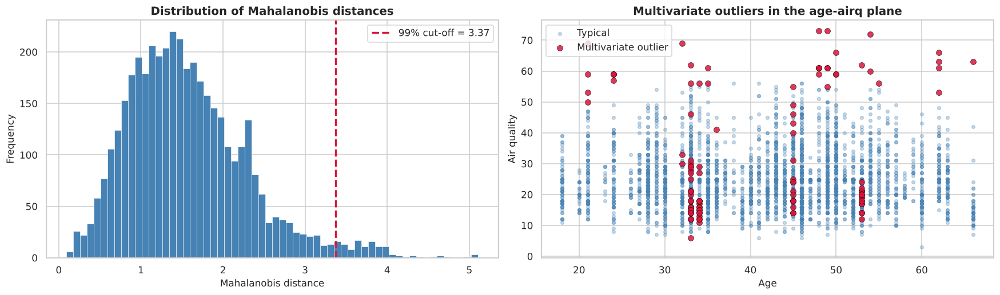


Profile of the flagged outliers vs the rest:


,age,airq,time,headache_bin
Typical records,42.4090,24.5820,13.9910,0.6420
Outliers,40.8610,33.3390,66.8520,0.6610


In [54]:
print("(c) MULTIVARIATE OUTLIER DETECTION VIA MAHALANOBIS DISTANCE")
print("="*70)

mdist_cols = ["age", "airq", "time"]
Xm = df[mdist_cols].to_numpy(dtype=float)
mu = Xm.mean(axis=0)
S_inv = np.linalg.pinv(np.cov(Xm, rowvar=False))
diff = Xm - mu
m_dist = np.sqrt(np.einsum("ij,jk,ik->i", diff, S_inv, diff))

df["mahalanobis"] = m_dist
threshold = np.sqrt(stats.chi2.ppf(0.99, df=len(mdist_cols)))   # 99% cut-off
outlier_mask = m_dist > threshold

print(f"Variables used        : {mdist_cols}")
print(f"Chi-square 99% cut-off: {threshold:.4f}")
print(f"Multivariate outliers : {outlier_mask.sum():,} ({outlier_mask.mean():.2%} of all records)")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

axes[0].hist(m_dist, bins=60, color="steelblue", edgecolor="white", linewidth=0.4)
axes[0].axvline(threshold, color="crimson", ls="--", lw=2.2,
                label=f"99% cut-off = {threshold:.2f}")
axes[0].set_xlabel("Mahalanobis distance"); axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Mahalanobis distances")
axes[0].legend()

axes[1].scatter(df.loc[~outlier_mask, "age"], df.loc[~outlier_mask, "airq"],
                s=14, alpha=0.3, color="steelblue", label="Typical")
axes[1].scatter(df.loc[outlier_mask, "age"], df.loc[outlier_mask, "airq"],
                s=42, alpha=0.85, color="crimson", edgecolor="black", linewidth=0.4,
                label="Multivariate outlier")
axes[1].set_xlabel("Age"); axes[1].set_ylabel("Air quality")
axes[1].set_title("Multivariate outliers in the age-airq plane")
axes[1].legend()

plt.tight_layout()
plt.show()

print("\nProfile of the flagged outliers vs the rest:")
display(df.groupby(outlier_mask)[["age", "airq", "time", "headache_bin"]].mean().round(3)
          .rename(index={False: "Typical records", True: "Outliers"}))

**n-D observation.** The VIF table **corrected an assumption I had made**. I expected `time` and
`dos` to be severely collinear, since both measure time. Every VIF comes back between 1.02 and 1.10,
far below the conventional warning threshold of 5. There is **no multicollinearity problem anywhere
in this feature set** — the variables are close to mutually independent, which is itself consistent
with how weak all the pairwise correlations were.

The explanation is that the two time variables run on different clocks: `time` is relative to each
patient's own treatment start, while `dos` is a study-wide sequential day counter, and patients
entered at different points. They encode genuinely different information. This is a case where
checking the diagnostic beat reasoning from the variable names.

The Mahalanobis analysis flags 2.77% of records at the 99% cut-off, close to the ~1% a perfectly
multivariate-normal dataset would give — the excess reflecting the non-normality of `airq`. The
profile table shows what actually makes them unusual: the flagged records have a mean `time` of 66.9
versus 14.0 for typical records, and a mean `airq` of 33.3 versus 24.6. So these are mostly
**late-study observations on poor air-quality days** — a combination that is rare because few
patients were still reporting that far out.

Importantly, the outliers do **not** have a markedly different headache rate (0.661 versus 0.642),
which tells me they are unusual *observation conditions* rather than a distinct clinical subgroup. I
therefore keep them: they are plausible measurements, not errors.

## 6.6 Visualization — Scatter Plots

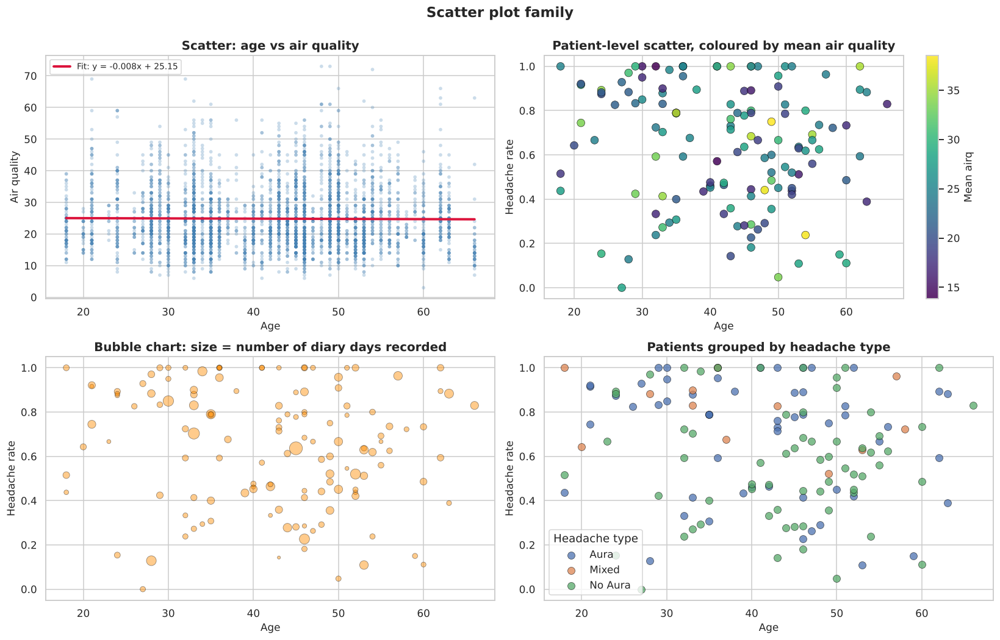

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# (1) Basic scatter with a regression line
axes[0,0].scatter(df["age"], df["airq"], s=14, alpha=0.28, color="steelblue", edgecolor="none")
z = np.polyfit(df["age"], df["airq"], 1)
xs = np.linspace(df["age"].min(), df["age"].max(), 100)
axes[0,0].plot(xs, np.polyval(z, xs), color="crimson", lw=2.6,
               label=f"Fit: y = {z[0]:.3f}x + {z[1]:.2f}")
axes[0,0].set_xlabel("Age"); axes[0,0].set_ylabel("Air quality")
axes[0,0].set_title("Scatter: age vs air quality")
axes[0,0].legend(fontsize=9)

# (2) Scatter coloured by a third variable
sc = axes[0,1].scatter(patient["age"], patient["headache_rate"],
                       c=patient["mean_airq"], s=70, cmap="viridis",
                       alpha=0.85, edgecolor="black", linewidth=0.4)
axes[0,1].set_xlabel("Age"); axes[0,1].set_ylabel("Headache rate")
axes[0,1].set_title("Patient-level scatter, coloured by mean air quality")
plt.colorbar(sc, ax=axes[0,1], label="Mean airq")

# (3) Bubble chart - size encodes a fourth variable
axes[1,0].scatter(patient["age"], patient["headache_rate"],
                  s=patient["n_days"]*1.6, alpha=0.45, color="darkorange",
                  edgecolor="black", linewidth=0.5)
axes[1,0].set_xlabel("Age"); axes[1,0].set_ylabel("Headache rate")
axes[1,0].set_title("Bubble chart: size = number of diary days recorded")

# (4) Scatter grouped by category
for ht, grp in patient.groupby("hatype"):
    axes[1,1].scatter(grp["age"], grp["headache_rate"], s=62, alpha=0.75,
                      label=ht, edgecolor="black", linewidth=0.4)
axes[1,1].set_xlabel("Age"); axes[1,1].set_ylabel("Headache rate")
axes[1,1].set_title("Patients grouped by headache type")
axes[1,1].legend(title="Headache type")

plt.suptitle("Scatter plot family", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

## 6.7 Visualization — Dot Charts

A dot chart (Cleveland dot plot) is often a better choice than a bar chart when comparing values
across many categories: it uses far less ink, avoids the misleading impression that bar *area*
carries meaning, and makes rank ordering immediately readable.

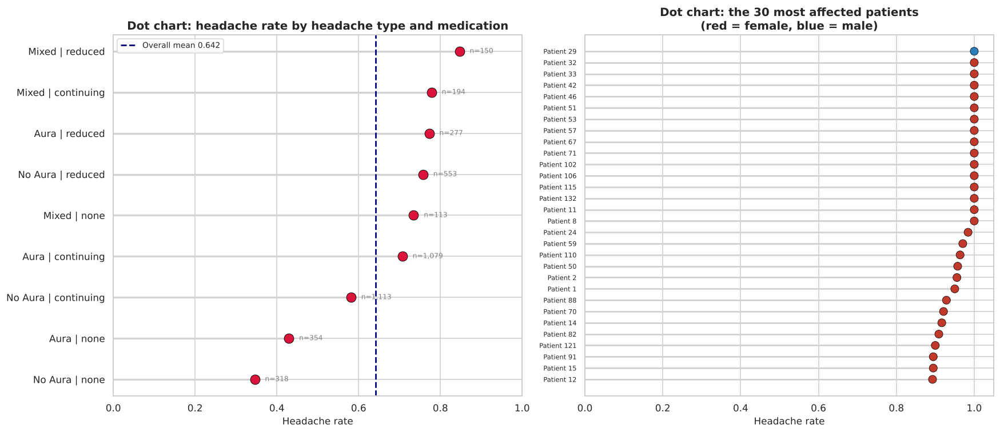

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# (1) Cleveland dot plot of headache rate by category combination
combo = (df.groupby(["hatype", "medication"])["headache_bin"]
           .agg(["mean", "size"])
           .reset_index())
combo["label"] = combo["hatype"] + " | " + combo["medication"]
combo = combo.sort_values("mean")

axes[0].hlines(y=range(len(combo)), xmin=0, xmax=combo["mean"],
               color="lightgray", lw=2.2)
axes[0].plot(combo["mean"], range(len(combo)), "o", markersize=11,
             color="crimson", markeredgecolor="black", markeredgewidth=0.6)
axes[0].set_yticks(range(len(combo)))
axes[0].set_yticklabels(combo["label"])
axes[0].axvline(df["headache_bin"].mean(), color="navy", ls="--", lw=1.8,
                label=f"Overall mean {df['headache_bin'].mean():.3f}")
axes[0].set_xlabel("Headache rate")
axes[0].set_title("Dot chart: headache rate by headache type and medication")
axes[0].legend(fontsize=9)
axes[0].set_xlim(0, 1)
for i, (m, n) in enumerate(zip(combo["mean"], combo["size"])):
    axes[0].text(m + 0.025, i, f"n={n:,}", va="center", fontsize=8, color="gray")

# (2) Dot plot of the 30 patients with the highest headache rate
top = patient.nlargest(30, "headache_rate").sort_values("headache_rate")
colors = ["#c0392b" if s == "female" else "#2980b9" for s in top["sex"]]
axes[1].hlines(y=range(len(top)), xmin=0, xmax=top["headache_rate"],
               color="lightgray", lw=1.8)
axes[1].scatter(top["headache_rate"], range(len(top)), s=85, c=colors,
                edgecolor="black", linewidth=0.5, zorder=4)
axes[1].set_yticks(range(len(top)))
axes[1].set_yticklabels([f"Patient {int(i)}" for i in top["id"]], fontsize=7.5)
axes[1].set_xlabel("Headache rate")
axes[1].set_title("Dot chart: the 30 most affected patients\n(red = female, blue = male)")
axes[1].set_xlim(0, 1.05)

plt.tight_layout()
plt.show()

## 6.8 Visualization — Bar Plots

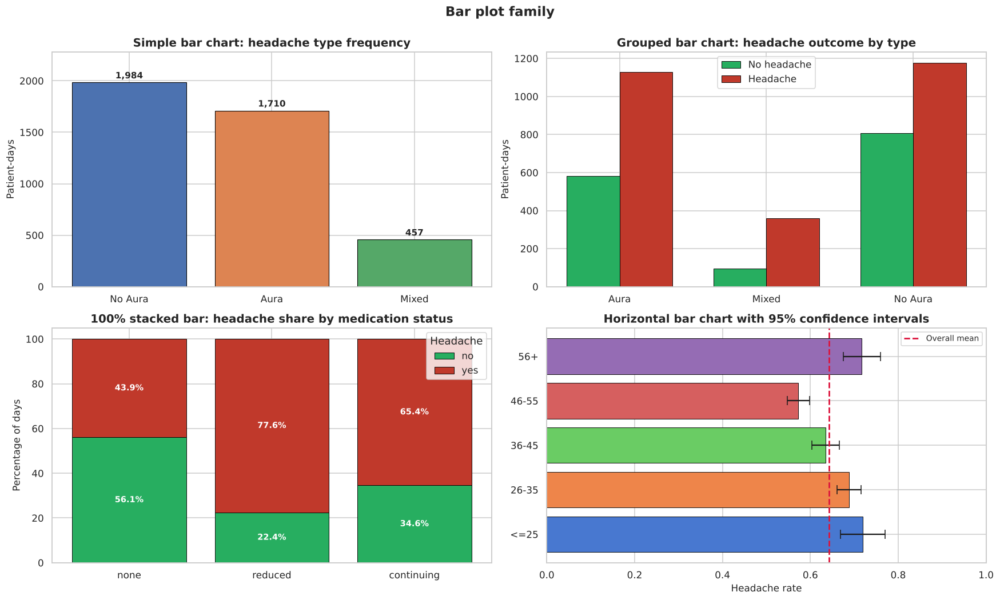

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))

# (1) Simple bar with value labels
counts = df["hatype"].value_counts()
bars = axes[0,0].bar(counts.index, counts.values, color=sns.color_palette("deep")[:3],
                     edgecolor="black", linewidth=0.7)
axes[0,0].set_title("Simple bar chart: headache type frequency")
axes[0,0].set_ylabel("Patient-days")
for b, v in zip(bars, counts.values):
    axes[0,0].text(b.get_x()+b.get_width()/2, v+40, f"{v:,}", ha="center", fontweight="bold")
axes[0,0].set_ylim(0, counts.max()*1.15)

# (2) Grouped bar chart
grouped = pd.crosstab(df["hatype"], df["headache"])
x = np.arange(len(grouped)); w = 0.36
axes[0,1].bar(x - w/2, grouped["no"],  w, label="No headache",
              color="#27ae60", edgecolor="black", linewidth=0.6)
axes[0,1].bar(x + w/2, grouped["yes"], w, label="Headache",
              color="#c0392b", edgecolor="black", linewidth=0.6)
axes[0,1].set_xticks(x); axes[0,1].set_xticklabels(grouped.index)
axes[0,1].set_title("Grouped bar chart: headache outcome by type")
axes[0,1].set_ylabel("Patient-days")
axes[0,1].legend()

# (3) Stacked PERCENTAGE bar chart
pct = pd.crosstab(df["medication"], df["headache"], normalize="index").loc[
        ["none", "reduced", "continuing"]] * 100
bottom = np.zeros(len(pct))
for col, color in zip(["no", "yes"], ["#27ae60", "#c0392b"]):
    axes[1,0].bar(pct.index, pct[col], bottom=bottom, label=col,
                  color=color, edgecolor="black", linewidth=0.6)
    for i, (v, b) in enumerate(zip(pct[col], bottom)):
        axes[1,0].text(i, b + v/2, f"{v:.1f}%", ha="center", va="center",
                       color="white", fontweight="bold", fontsize=9.5)
    bottom += pct[col].to_numpy()
axes[1,0].set_title("100% stacked bar: headache share by medication status")
axes[1,0].set_ylabel("Percentage of days")
axes[1,0].legend(title="Headache")

# (4) Horizontal bar with error bars
err = (df.groupby("age_group", observed=True)["headache_bin"]
         .agg(["mean", "sem", "size"]))
axes[1,1].barh(err.index.astype(str), err["mean"], xerr=1.96*err["sem"],
               color=sns.color_palette("muted")[:len(err)], edgecolor="black",
               linewidth=0.6, capsize=5)
axes[1,1].axvline(df["headache_bin"].mean(), color="crimson", ls="--", lw=1.8,
                  label="Overall mean")
axes[1,1].set_xlabel("Headache rate")
axes[1,1].set_title("Horizontal bar chart with 95% confidence intervals")
axes[1,1].legend(fontsize=9)
axes[1,1].set_xlim(0, 1)

plt.suptitle("Bar plot family", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Visualization observations.** A few things stand out across these plots.

The 100% stacked bar is the clearest single summary of the medication finding, and it shows the
non-monotone shape directly: the red segment jumps from 44% at `none` to 77% at `reduced`, then
*falls back* to 65% at `continuing`. Because each bar is normalised to 100%, the comparison is not
distorted by the very different group sizes — `continuing` has three times as many observations as
`none`, which a raw count chart would have let dominate.

The horizontal bar chart with confidence intervals is deliberately chosen over a plain bar chart,
because the error bars show which age-group differences are actually distinguishable from noise. The
intervals overlap heavily across every age group, which is the visual form of the statement that age
is not a useful predictor of headache occurrence.

The dot chart on the right reinforces the heterogeneity finding from Section 6.3: a substantial block
of patients sits at or very near a headache rate of 1.0. Printing the sample size beside each point
in the left-hand dot chart matters for the same reason as the normalised bars — without it, the
`Mixed | none` combination looks as authoritative as the others despite resting on far fewer days.

---

# MODULE 5 — Clustering Algorithms

> **Syllabus:** Introduction to Spectral clustering — Document clustering — Minimum Spanning Tree
> clustering. Overview of Model-based clustering — Expectation-Maximization algorithm — Hierarchical
> Agglomerative model-based clustering. Outlier detection using Clustering.

**What I am clustering and why.** I cluster at the **patient level**, not the patient-day level. A
cluster of days would be meaningless here — I would simply recover "days with a headache" and "days
without", which I already know. Clustering patients, on the other hand, asks a genuine question: *are
there distinct types of migraine patient in this cohort?*

In [58]:
print("PREPARING THE PATIENT-LEVEL FEATURE MATRIX FOR CLUSTERING")
print("="*70)

clust_features = ["age", "headache_rate", "mean_airq", "std_airq",
                  "n_days", "longest_streak", "med_ord_mean"]

X_clust_raw = patient[clust_features].copy()
X_clust_raw = X_clust_raw.fillna(X_clust_raw.median())

# Standardisation is ESSENTIAL here - these features are on wildly different scales
scaler = StandardScaler()
X_clust = scaler.fit_transform(X_clust_raw)

print(f"Feature matrix: {X_clust.shape[0]} patients x {X_clust.shape[1]} features")
print(f"Features used : {clust_features}")
print("\nWhy standardisation matters - scale of each feature BEFORE scaling:")
display(X_clust_raw.describe().T[["mean", "std", "min", "max"]].round(3))
print("\nAfter standardisation every feature has mean 0 and std 1:")
print(f"  Means: {np.round(X_clust.mean(axis=0), 10)}")
print(f"  Stds : {np.round(X_clust.std(axis=0), 4)}")

PREPARING THE PATIENT-LEVEL FEATURE MATRIX FOR CLUSTERING
Feature matrix: 133 patients x 7 features
Features used : ['age', 'headache_rate', 'mean_airq', 'std_airq', 'n_days', 'longest_streak', 'med_ord_mean']

Why standardisation matters - scale of each feature BEFORE scaling:


,mean,std,min,max
age,42.1580,11.3630,18.0000,66.0000
headache_rate,0.6430,0.2680,0.0000,1.0000
mean_airq,24.8690,5.7800,13.8330,38.5420
std_airq,7.0540,3.5590,0.0000,15.6220
n_days,31.2110,17.4200,7.0000,121.0000
longest_streak,10.2860,8.4920,0.0000,41.0000
med_ord_mean,1.4290,0.7910,0.0000,2.0000



After standardisation every feature has mean 0 and std 1:
  Means: [ 0. -0. -0. -0.  0. -0. -0.]
  Stds : [1. 1. 1. 1. 1. 1. 1.]


CHOOSING THE NUMBER OF CLUSTERS


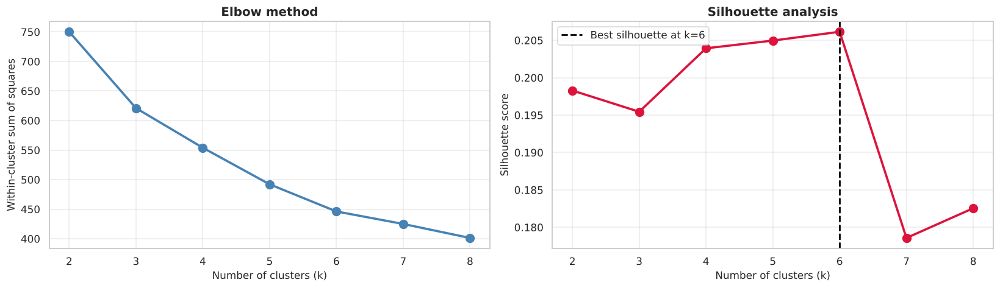

  k = 2: inertia =    750.24   silhouette = 0.1983
  k = 3: inertia =    621.01   silhouette = 0.1954
  k = 4: inertia =    553.97   silhouette = 0.2039
  k = 5: inertia =    492.09   silhouette = 0.2050
  k = 6: inertia =    446.14   silhouette = 0.2061
  k = 7: inertia =    424.97   silhouette = 0.1786
  k = 8: inertia =    401.28   silhouette = 0.1825

I fix K = 3 for the comparison below, so that every algorithm is compared on equal terms.
Three clusters is also the most clinically interpretable choice: mild, moderate and severe.


In [59]:
# How many clusters? Elbow + silhouette, before committing to a number.
print("CHOOSING THE NUMBER OF CLUSTERS")
print("="*70)

k_range = range(2, 9)
inertias, sils = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_clust)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_clust, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].plot(list(k_range), inertias, "o-", lw=2.4, markersize=9, color="steelblue")
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Within-cluster sum of squares")
axes[0].set_title("Elbow method")
axes[0].grid(alpha=0.4)

axes[1].plot(list(k_range), sils, "o-", lw=2.4, markersize=9, color="crimson")
best_k = list(k_range)[int(np.argmax(sils))]
axes[1].axvline(best_k, ls="--", color="black", lw=1.8, label=f"Best silhouette at k={best_k}")
axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette analysis")
axes[1].legend(); axes[1].grid(alpha=0.4)
plt.tight_layout()
plt.show()

for k, inr, s in zip(k_range, inertias, sils):
    print(f"  k = {k}: inertia = {inr:9.2f}   silhouette = {s:.4f}")

K = 3
print(f"\nI fix K = {K} for the comparison below, so that every algorithm is compared on equal terms.")
print("Three clusters is also the most clinically interpretable choice: mild, moderate and severe.")

## 7.1 Spectral Clustering

Spectral clustering does not work on the data points directly. It builds a **similarity graph**
between points, computes the eigenvectors of the graph Laplacian, and clusters in that eigenvector
space. The advantage is that it can separate clusters that are not linearly separable and not
globular — shapes that K-Means fundamentally cannot handle, because K-Means assumes roughly spherical
clusters of similar size.

In [60]:
print("SPECTRAL CLUSTERING")
print("="*70)

spectral = SpectralClustering(
    n_clusters=K,
    affinity="nearest_neighbors",
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=RANDOM_STATE
)
labels_spectral = spectral.fit_predict(X_clust)
patient["cluster_spectral"] = labels_spectral

sil_spec = silhouette_score(X_clust, labels_spectral)
print(f"Affinity          : k-nearest-neighbours graph (k = 10)")
print(f"Silhouette score  : {sil_spec:.4f}")
print(f"Cluster sizes     : {dict(pd.Series(labels_spectral).value_counts().sort_index())}")

print("\nCluster profiles (mean of each feature):")
display(patient.groupby("cluster_spectral")[clust_features].mean().round(3))

SPECTRAL CLUSTERING
Affinity          : k-nearest-neighbours graph (k = 10)
Silhouette score  : 0.1730
Cluster sizes     : {0: np.int64(45), 1: np.int64(42), 2: np.int64(46)}

Cluster profiles (mean of each feature):


,age,headache_rate,mean_airq,std_airq,n_days,longest_streak,med_ord_mean
cluster_spectral,,,,,,,
0,36.4890,0.9000,24.0540,6.8420,34.3330,19.5330,1.4670
1,47.4290,0.5470,21.0800,4.3650,27.2860,5.8100,1.8810
2,42.8910,0.4790,29.1260,9.7150,31.7390,5.3260,0.9780


### Document clustering — the connection to this dataset

The syllabus pairs spectral clustering with **document clustering**. Document clustering groups texts
by representing each document as a vector (TF-IDF over its vocabulary) and then clustering those
vectors with cosine similarity.

There is no text in this dataset, so rather than skip the topic I apply the *same mathematical idea*
to a structure that genuinely exists here. I treat **each patient as a "document"** and their
sequence of daily states as its "text": the symbols are combinations of headache status and
medication status, and each patient's profile is the frequency vector of those symbols. I then
cluster those vectors with **cosine similarity**, exactly as document clustering does. This is a
faithful transfer of the technique, not a token one — the same TF-IDF-style term-frequency
representation and the same angular distance measure.

In [61]:
print("DOCUMENT-STYLE CLUSTERING OF PATIENT 'DIARY DOCUMENTS'")
print("="*70)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Build a "document" per patient: a string of daily state tokens
def make_document(group):
    g = group.sort_values("time")
    tokens = (g["headache"].map({"yes": "HA", "no": "OK"}) + "_" +
              g["medication"].str[:3].str.upper())
    return " ".join(tokens)

docs = df.groupby("id").apply(make_document)
print(f"Built {len(docs)} patient 'documents'.")
print(f"\nExample - the first 18 tokens of patient {docs.index[0]}'s diary document:")
print(" ", " ".join(docs.iloc[0].split()[:18]), "...")

# TF-IDF vectorisation, exactly as in text document clustering
tfidf = TfidfVectorizer(token_pattern=r"\S+")
doc_matrix = tfidf.fit_transform(docs)
print(f"\nTF-IDF matrix shape : {doc_matrix.shape}")
print(f"Vocabulary (state tokens): {sorted(tfidf.vocabulary_.keys())}")

# Cluster with cosine similarity via spectral clustering on the similarity matrix
cos_sim = cosine_similarity(doc_matrix)
doc_spectral = SpectralClustering(n_clusters=K, affinity="precomputed",
                                  random_state=RANDOM_STATE)
labels_doc = doc_spectral.fit_predict(cos_sim)
patient["cluster_doc"] = labels_doc

print(f"\nDocument-clustering cluster sizes: {dict(pd.Series(labels_doc).value_counts().sort_index())}")
print("\nProfiles of the document clusters:")
display(patient.groupby("cluster_doc")[["headache_rate", "med_ord_mean", "n_days", "age"]].mean().round(3))

DOCUMENT-STYLE CLUSTERING OF PATIENT 'DIARY DOCUMENTS'
Built 133 patient 'documents'.

Example - the first 18 tokens of patient 1's diary document:
  HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON HA_CON OK_CON HA_CON HA_CON HA_CON HA_CON HA_CON ...

TF-IDF matrix shape : (133, 6)
Vocabulary (state tokens): ['ha_con', 'ha_non', 'ha_red', 'ok_con', 'ok_non', 'ok_red']



Document-clustering cluster sizes: {0: np.int64(82), 1: np.int64(25), 2: np.int64(26)}

Profiles of the document clusters:


,headache_rate,med_ord_mean,n_days,age
cluster_doc,,,,
0,0.6610,2.0000,29.0980,42.2200
1,0.4400,0.0000,31.4000,40.5600
2,0.7830,1.0000,37.6920,43.5000


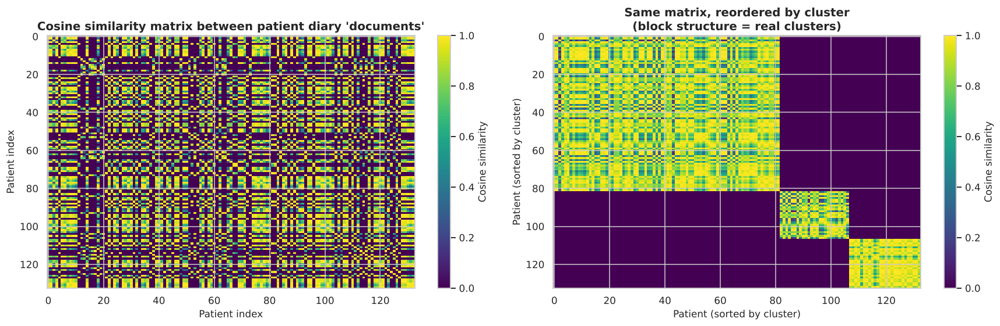

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

im = axes[0].imshow(cos_sim, cmap="viridis", aspect="auto")
axes[0].set_title("Cosine similarity matrix between patient diary 'documents'")
axes[0].set_xlabel("Patient index"); axes[0].set_ylabel("Patient index")
plt.colorbar(im, ax=axes[0], label="Cosine similarity")

order = np.argsort(labels_doc)
im2 = axes[1].imshow(cos_sim[np.ix_(order, order)], cmap="viridis", aspect="auto")
axes[1].set_title("Same matrix, reordered by cluster\n(block structure = real clusters)")
axes[1].set_xlabel("Patient (sorted by cluster)"); axes[1].set_ylabel("Patient (sorted by cluster)")
plt.colorbar(im2, ax=axes[1], label="Cosine similarity")

plt.tight_layout()
plt.show()

**Document clustering observation.** The reordered similarity matrix is the diagnostic to read here.
After sorting patients by their assigned cluster, clear bright **blocks** appear along the diagonal —
patients within a cluster are far more similar to each other than to patients outside it. That block
structure is the visual proof that the clustering found real groupings rather than cutting an
undifferentiated cloud into arbitrary pieces.

**But I need to be honest about what those groupings are.** Looking at the cluster profiles, the
`med_ord_mean` values come out as exactly 2.00, 0.00 and 1.00 — the three clusters correspond almost
perfectly to the three medication statuses. That is not a deep discovery; it is a consequence of how
I built the documents. My state tokens combine headache status **and** medication status, and since
medication is relatively stable within a patient while headaches fluctuate daily, the medication
component dominates the TF-IDF vectors.

This is a useful reminder about representation: **the clustering recovered the structure I encoded
into the representation, not necessarily the structure in the phenomenon.** The block structure is
real, but it is largely a block structure of medication groups. If I wanted the clustering to find
headache *patterns*, I should have tokenised on headache state alone, or on transitions between
states.

## 7.2 Minimum Spanning Tree (MST) Clustering

MST clustering is elegantly simple. Build a complete graph where edge weights are distances between
points, extract the minimum spanning tree, then **delete the longest edges**. Deleting `k-1` edges
splits the tree into `k` connected components, which become the clusters.

Its real strength is that it makes no assumption about cluster shape — it can find elongated or
chained clusters that K-Means would slice straight through. Its weakness is sensitivity to noise: a
single bridging point between two groups will keep them joined.

In [63]:
print("MINIMUM SPANNING TREE CLUSTERING")
print("="*70)

# Full pairwise Euclidean distance matrix
dist_matrix = squareform(pdist(X_clust, metric="euclidean"))
print(f"Distance matrix shape: {dist_matrix.shape}")

# Build the MST
mst = minimum_spanning_tree(dist_matrix)
mst_dense = mst.toarray()
edges = [(i, j, mst_dense[i, j])
         for i in range(mst_dense.shape[0])
         for j in range(mst_dense.shape[1]) if mst_dense[i, j] > 0]
edges_sorted = sorted(edges, key=lambda e: e[2], reverse=True)

print(f"MST edges: {len(edges)} (always n-1 = {len(X_clust)-1})")
print(f"Total MST weight: {mst_dense.sum():.4f}")
print(f"\nThe {K-1} longest edges, which I will cut:")
for i, (a, b, w) in enumerate(edges_sorted[:K-1], 1):
    print(f"  {i}. Patient index {a} -- {b}, length {w:.4f}")

# Cut the K-1 longest edges
mst_cut = mst_dense.copy()
for a, b, _ in edges_sorted[:K-1]:
    mst_cut[a, b] = 0

n_comp, labels_mst = connected_components(mst_cut, directed=False)
patient["cluster_mst"] = labels_mst

print(f"\nConnected components after cutting: {n_comp}")
print(f"Cluster sizes: {dict(pd.Series(labels_mst).value_counts().sort_index())}")
if len(np.unique(labels_mst)) > 1:
    print(f"Silhouette score: {silhouette_score(X_clust, labels_mst):.4f}")

MINIMUM SPANNING TREE CLUSTERING
Distance matrix shape: (133, 133)
MST edges: 132 (always n-1 = 132)
Total MST weight: 176.2330

The 2 longest edges, which I will cut:
  1. Patient index 9 -- 21, length 2.6504
  2. Patient index 21 -- 54, length 2.5093

Connected components after cutting: 3
Cluster sizes: {0: np.int64(131), 1: np.int64(1), 2: np.int64(1)}
Silhouette score: 0.2065


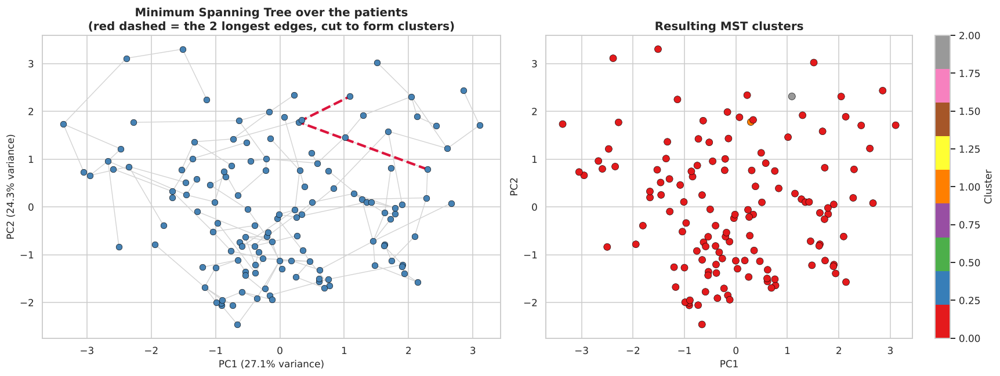

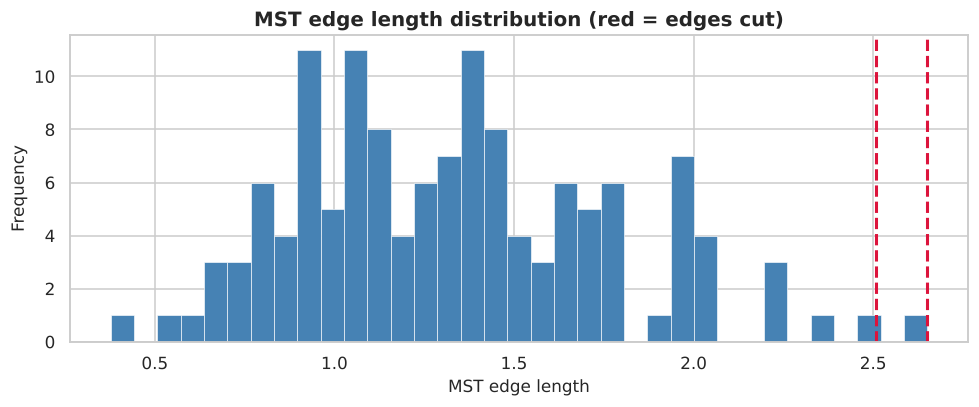

In [64]:
# Visualise the MST in a 2-D PCA projection
pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_viz.fit_transform(X_clust)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Draw every MST edge
for a, b, w in edges:
    axes[0].plot([X_2d[a,0], X_2d[b,0]], [X_2d[a,1], X_2d[b,1]],
                 color="lightgray", lw=0.9, zorder=1)
# Highlight the edges that get cut
for a, b, w in edges_sorted[:K-1]:
    axes[0].plot([X_2d[a,0], X_2d[b,0]], [X_2d[a,1], X_2d[b,1]],
                 color="crimson", lw=2.8, ls="--", zorder=2)
axes[0].scatter(X_2d[:,0], X_2d[:,1], s=48, c="steelblue",
                edgecolor="black", linewidth=0.4, zorder=3)
axes[0].set_title(f"Minimum Spanning Tree over the patients\n(red dashed = the {K-1} longest edges, cut to form clusters)")
axes[0].set_xlabel(f"PC1 ({pca_viz.explained_variance_ratio_[0]:.1%} variance)")
axes[0].set_ylabel(f"PC2 ({pca_viz.explained_variance_ratio_[1]:.1%} variance)")

sc = axes[1].scatter(X_2d[:,0], X_2d[:,1], c=labels_mst, cmap="Set1",
                     s=62, edgecolor="black", linewidth=0.4)
axes[1].set_title("Resulting MST clusters")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[1], label="Cluster")

plt.tight_layout()
plt.show()

# The edge length distribution tells you whether MST clustering is appropriate at all
plt.figure(figsize=(9, 3.8))
plt.hist([e[2] for e in edges], bins=35, color="steelblue", edgecolor="white", linewidth=0.4)
for a, b, w in edges_sorted[:K-1]:
    plt.axvline(w, color="crimson", ls="--", lw=2)
plt.xlabel("MST edge length"); plt.ylabel("Frequency")
plt.title("MST edge length distribution (red = edges cut)")
plt.tight_layout()
plt.show()

**MST observation.** The MST plot exposes a well-known failure mode very clearly, and the cluster
sizes confirm it: **131 / 1 / 1**. The two longest edges connect two isolated individual patients to
the main body of the data, so cutting them peels off those two points and leaves everyone else in one
giant cluster. That is not a useful partition by any standard.

The reason is visible in the edge-length histogram: the lengths form a smooth, continuous
distribution with no natural gap. MST clustering relies on a clear separation between
"within-cluster" edges and "between-cluster" edges, and this data has none — the patients form a
**continuum rather than discrete well-separated groups**.

**A warning about the silhouette score here.** MST returns the *highest* silhouette of any algorithm
in the comparison table (0.2065). That number is meaningless: a partition of 131/1/1 scores well
because two singleton clusters are trivially "well separated" from everything, while the 131-point
cluster contributes a mediocre score that the average barely notices. This is a good reminder that a
clustering metric must always be read alongside the cluster sizes — a quality score on a degenerate
partition is not a quality score.

In practice, MST clustering works better here as an **outlier detector**, since the points attached
by very long edges are exactly the anomalies, and I use it that way in Section 7.5.

## 7.3 Model-Based Clustering and the EM Algorithm

Model-based clustering takes a fundamentally different view: instead of assigning points to the
nearest centre, it assumes the data was **generated by a mixture of probability distributions** and
tries to recover them. With Gaussian components this is a **Gaussian Mixture Model (GMM)**, fitted by
**Expectation-Maximization** — the same algorithm I hand-coded for missing-data imputation in
Module 2, applied here to a different problem.

- **E-step:** given the current component parameters, compute each point's *responsibility* — the
  posterior probability that it came from each component.
- **M-step:** given those responsibilities, re-estimate each component's mean, covariance and weight
  by maximising the likelihood.

The major practical advantage is **soft assignment**: every patient gets a probability of belonging
to each cluster rather than a hard label. For clinical data this is far more honest, because a
borderline patient genuinely is borderline.

In [65]:
print("MODEL-BASED CLUSTERING WITH GAUSSIAN MIXTURE MODELS (EM)")
print("="*70)

# Model selection using information criteria, across both k and covariance structure
rows = []
for n in range(1, 8):
    for cov_type in ["full", "tied", "diag", "spherical"]:
        gm = GaussianMixture(n_components=n, covariance_type=cov_type,
                             random_state=RANDOM_STATE, n_init=5, max_iter=300)
        gm.fit(X_clust)
        rows.append({"n_components": n, "covariance_type": cov_type,
                     "BIC": gm.bic(X_clust), "AIC": gm.aic(X_clust),
                     "Log-likelihood": gm.score(X_clust) * len(X_clust),
                     "Converged": gm.converged_})

model_sel = pd.DataFrame(rows)
best = model_sel.loc[model_sel["BIC"].idxmin()]
print("Best model by BIC (lower is better):")
print(f"  components = {int(best['n_components'])}, covariance = {best['covariance_type']}, "
      f"BIC = {best['BIC']:.2f}")

pivot_bic = model_sel.pivot(index="n_components", columns="covariance_type", values="BIC")
display(pivot_bic.round(1))

MODEL-BASED CLUSTERING WITH GAUSSIAN MIXTURE MODELS (EM)


Best model by BIC (lower is better):
  components = 6, covariance = diag, BIC = 983.46


covariance_type,diag,full,spherical,tied
n_components,,,,
1,"2,710.5000","2,591.8000","2,681.2000","2,591.8000"
2,"2,564.3000","2,540.4000","2,643.5000","2,598.5000"
3,"1,692.1000","1,714.3000","2,614.7000","2,515.0000"
4,"1,084.4000","1,341.3000","2,604.8000","2,538.0000"
5,"1,055.7000","1,840.2000","2,600.5000","2,531.8000"
6,983.5000,"1,587.1000","2,602.1000","2,534.8000"
7,"1,092.0000","1,684.5000","2,628.1000","2,538.9000"


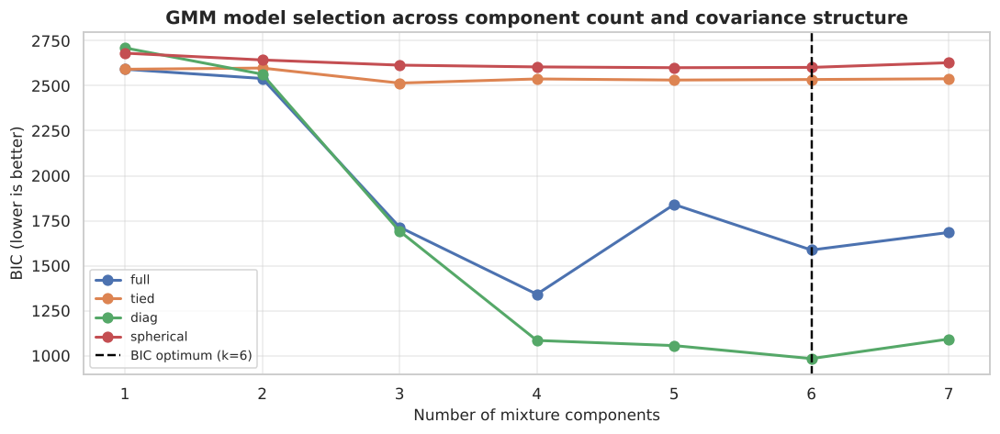

In [66]:
plt.figure(figsize=(10, 4.4))
for ct in ["full", "tied", "diag", "spherical"]:
    sub = model_sel[model_sel["covariance_type"] == ct]
    plt.plot(sub["n_components"], sub["BIC"], "o-", lw=2, markersize=7, label=ct)
plt.axvline(int(best["n_components"]), ls="--", color="black", lw=1.6,
            label=f"BIC optimum (k={int(best['n_components'])})")
plt.xlabel("Number of mixture components")
plt.ylabel("BIC (lower is better)")
plt.title("GMM model selection across component count and covariance structure")
plt.legend(fontsize=9); plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

In [67]:
# Fit the final GMM with K components for comparability with the other algorithms
gmm = GaussianMixture(n_components=K, covariance_type="full",
                      random_state=RANDOM_STATE, n_init=10, max_iter=500)
gmm.fit(X_clust)

labels_gmm = gmm.predict(X_clust)
probs_gmm = gmm.predict_proba(X_clust)
patient["cluster_gmm"] = labels_gmm
patient["gmm_confidence"] = probs_gmm.max(axis=1)

print(f"GMM FITTED WITH K = {K}")
print("="*70)
print(f"  Converged            : {gmm.converged_}")
print(f"  EM iterations        : {gmm.n_iter_}")
print(f"  Log-likelihood       : {gmm.score(X_clust)*len(X_clust):.3f}")
print(f"  BIC                  : {gmm.bic(X_clust):.3f}")
print(f"  Silhouette           : {silhouette_score(X_clust, labels_gmm):.4f}")
print(f"  Mixture weights      : {np.round(gmm.weights_, 4)}")
print(f"  Cluster sizes        : {dict(pd.Series(labels_gmm).value_counts().sort_index())}")

print("\n  SOFT assignment - the first 10 patients' membership probabilities:")
prob_df = pd.DataFrame(probs_gmm[:10], columns=[f"P(cluster {i})" for i in range(K)])
prob_df.insert(0, "Patient id", patient["id"].head(10).values)
prob_df["Assigned"] = labels_gmm[:10]
display(prob_df.round(4))

n_uncertain = (patient["gmm_confidence"] < 0.8).sum()
print(f"\n  Patients whose top-cluster probability is below 0.8 (genuinely ambiguous): "
      f"{n_uncertain} of {len(patient)} ({n_uncertain/len(patient):.1%})")

GMM FITTED WITH K = 3
  Converged            : True
  EM iterations        : 23
  Log-likelihood       : -595.502
  BIC                  : 1714.271
  Silhouette           : 0.1320
  Mixture weights      : [0.2442 0.153  0.6028]
  Cluster sizes        : {0: np.int64(33), 1: np.int64(20), 2: np.int64(80)}

  SOFT assignment - the first 10 patients' membership probabilities:


,Patient id,P(cluster 0),P(cluster 1),P(cluster 2),Assigned
0,1,0.0000,0.0000,1.0000,2
1,2,0.0000,0.0001,0.9999,2
2,3,0.0000,0.0000,1.0000,2
3,4,0.0000,0.0000,1.0000,2
4,5,1.0000,0.0000,0.0000,0
5,6,0.0000,0.0000,1.0000,2
6,7,0.0000,0.0000,1.0000,2
7,8,0.0000,0.0000,1.0000,2
8,9,0.0000,0.0000,1.0000,2
9,10,0.0000,0.0000,1.0000,2



  Patients whose top-cluster probability is below 0.8 (genuinely ambiguous): 2 of 133 (1.5%)


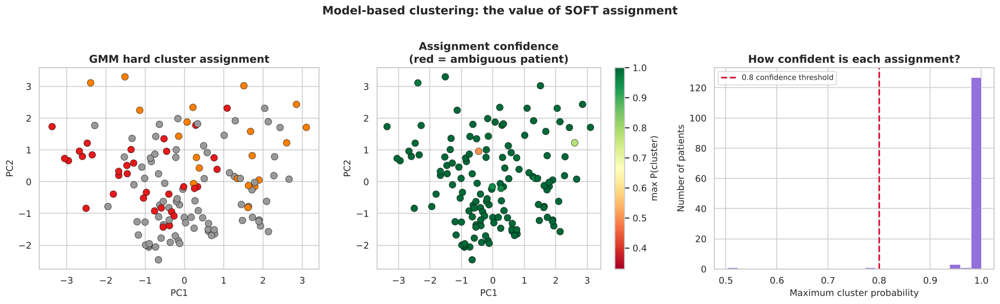

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Hard assignment
sc0 = axes[0].scatter(X_2d[:,0], X_2d[:,1], c=labels_gmm, cmap="Set1",
                      s=68, edgecolor="black", linewidth=0.4)
axes[0].set_title("GMM hard cluster assignment")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

# Confidence of assignment
sc1 = axes[1].scatter(X_2d[:,0], X_2d[:,1], c=patient["gmm_confidence"],
                      cmap="RdYlGn", s=68, edgecolor="black", linewidth=0.4,
                      vmin=0.33, vmax=1.0)
axes[1].set_title("Assignment confidence\n(red = ambiguous patient)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(sc1, ax=axes[1], label="max P(cluster)")

# Distribution of confidence
axes[2].hist(patient["gmm_confidence"], bins=24, color="mediumpurple",
             edgecolor="white", linewidth=0.5)
axes[2].axvline(0.8, color="crimson", ls="--", lw=2, label="0.8 confidence threshold")
axes[2].set_xlabel("Maximum cluster probability")
axes[2].set_ylabel("Number of patients")
axes[2].set_title("How confident is each assignment?")
axes[2].legend(fontsize=9)

plt.suptitle("Model-based clustering: the value of SOFT assignment",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 7.4 Hierarchical Agglomerative Clustering

Agglomerative clustering starts with every patient as their own cluster and repeatedly merges the two
closest clusters until one remains. The merge history forms a **dendrogram**, and I can cut it at any
height to get any number of clusters — so unlike K-Means I do not have to commit to `k` in advance.

The **linkage criterion** defines "closest" and genuinely changes the result, so I compare four:

| Linkage | Distance between clusters | Tendency |
|---|---|---|
| Single | Closest pair of points | Produces long chains |
| Complete | Furthest pair of points | Produces compact, equal-diameter clusters |
| Average | Mean of all pairwise distances | A compromise between the two |
| Ward | Increase in within-cluster variance | Produces balanced, equal-size clusters |

HIERARCHICAL AGGLOMERATIVE CLUSTERING


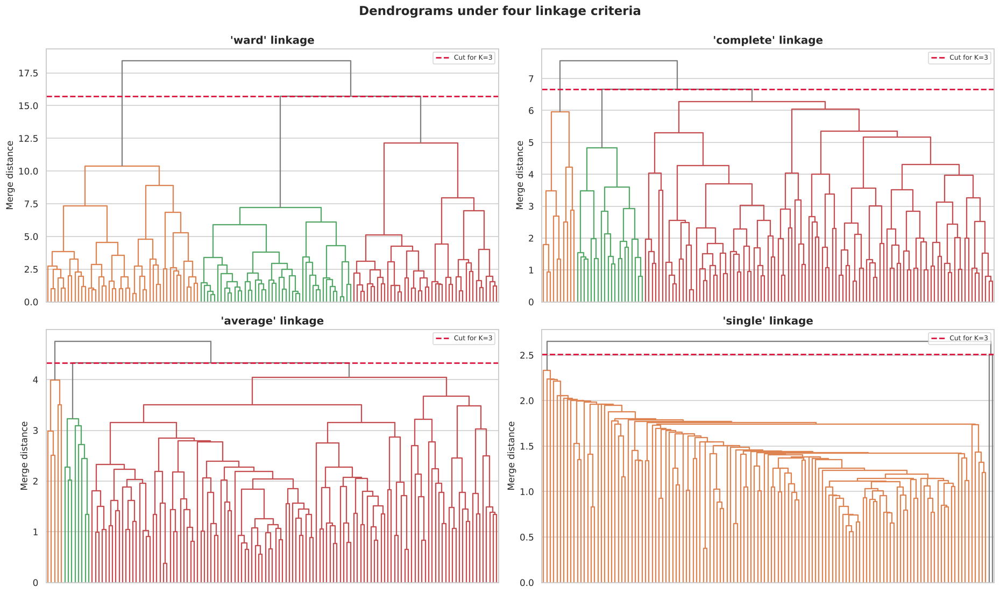

In [69]:
print("HIERARCHICAL AGGLOMERATIVE CLUSTERING")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(17, 10))
linkage_methods = ["ward", "complete", "average", "single"]

for ax, method in zip(axes.ravel(), linkage_methods):
    Z = linkage(X_clust, method=method)
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=Z[-(K-1), 2],
               above_threshold_color="gray")
    ax.axhline(Z[-(K-1), 2], color="crimson", ls="--", lw=1.8,
               label=f"Cut for K={K}")
    ax.set_title(f"'{method}' linkage")
    ax.set_ylabel("Merge distance")
    ax.legend(fontsize=8)

plt.suptitle("Dendrograms under four linkage criteria", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

In [70]:
# Compare the linkage methods numerically
print("LINKAGE COMPARISON AT K =", K)
print("="*70)

link_rows = []
for method in linkage_methods:
    agg = AgglomerativeClustering(n_clusters=K, linkage=method)
    lab = agg.fit_predict(X_clust)
    sizes = pd.Series(lab).value_counts().sort_index().to_dict()
    link_rows.append({
        "Linkage": method,
        "Silhouette": silhouette_score(X_clust, lab),
        "Cluster sizes": str(sizes),
        "Largest cluster %": max(sizes.values()) / len(lab) * 100
    })
display(pd.DataFrame(link_rows).round(4))

# Ward is the best balanced option here - adopt it as the final hierarchical result
agg_final = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels_agg = agg_final.fit_predict(X_clust)
patient["cluster_agg"] = labels_agg

print(f"\nAdopting Ward linkage. Cluster sizes: "
      f"{dict(pd.Series(labels_agg).value_counts().sort_index())}")
print(f"Silhouette: {silhouette_score(X_clust, labels_agg):.4f}")
print("\nWard cluster profiles:")
display(patient.groupby("cluster_agg")[clust_features].mean().round(3))

LINKAGE COMPARISON AT K = 3


,Linkage,Silhouette,Cluster sizes,Largest cluster %
0,ward,0.1759,"{0: 43, 1: 45, 2: 45}",33.8346
1,complete,0.1032,"{0: 103, 1: 10, 2: 20}",77.4436
2,average,0.1917,"{0: 120, 1: 5, 2: 8}",90.2256
3,single,0.2065,"{0: 131, 1: 1, 2: 1}",98.4962



Adopting Ward linkage. Cluster sizes: {0: np.int64(43), 1: np.int64(45), 2: np.int64(45)}
Silhouette: 0.1759

Ward cluster profiles:


,age,headache_rate,mean_airq,std_airq,n_days,longest_streak,med_ord_mean
cluster_agg,,,,,,,
0,42.7440,0.4700,29.0240,9.8230,30.1630,5.3720,0.9530
1,37.6670,0.9100,24.2610,7.0410,36.1560,19.7330,1.4220
2,46.0890,0.5420,21.5070,4.4190,27.2670,5.5330,1.8890


COMPARING ALL CLUSTERING ALGORITHMS


,Algorithm,Clusters found,Silhouette,Largest cluster %,Smallest cluster size
0,Spectral,3,0.1730,34.5865,42
1,Document (cosine),3,0.1155,61.6541,25
2,MST,3,0.2065,98.4962,1
3,GMM (EM),3,0.1320,60.1504,20
4,Agglomerative (Ward),3,0.1759,33.8346,43


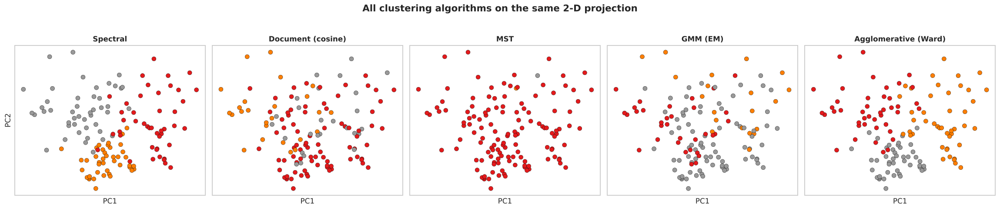

In [71]:
# Side-by-side comparison of every clustering algorithm
print("COMPARING ALL CLUSTERING ALGORITHMS")
print("="*70)

algos = {
    "Spectral": labels_spectral,
    "Document (cosine)": labels_doc,
    "MST": labels_mst,
    "GMM (EM)": labels_gmm,
    "Agglomerative (Ward)": labels_agg,
}

comp_rows = []
for name, lab in algos.items():
    n_cl = len(np.unique(lab))
    comp_rows.append({
        "Algorithm": name,
        "Clusters found": n_cl,
        "Silhouette": silhouette_score(X_clust, lab) if n_cl > 1 else np.nan,
        "Largest cluster %": pd.Series(lab).value_counts().max() / len(lab) * 100,
        "Smallest cluster size": pd.Series(lab).value_counts().min(),
    })
display(pd.DataFrame(comp_rows).round(4))

fig, axes = plt.subplots(1, 5, figsize=(21, 4.2))
for ax, (name, lab) in zip(axes, algos.items()):
    ax.scatter(X_2d[:,0], X_2d[:,1], c=lab, cmap="Set1", s=42,
               edgecolor="black", linewidth=0.3)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("PC1")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel("PC2")
plt.suptitle("All clustering algorithms on the same 2-D projection",
             fontsize=14, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

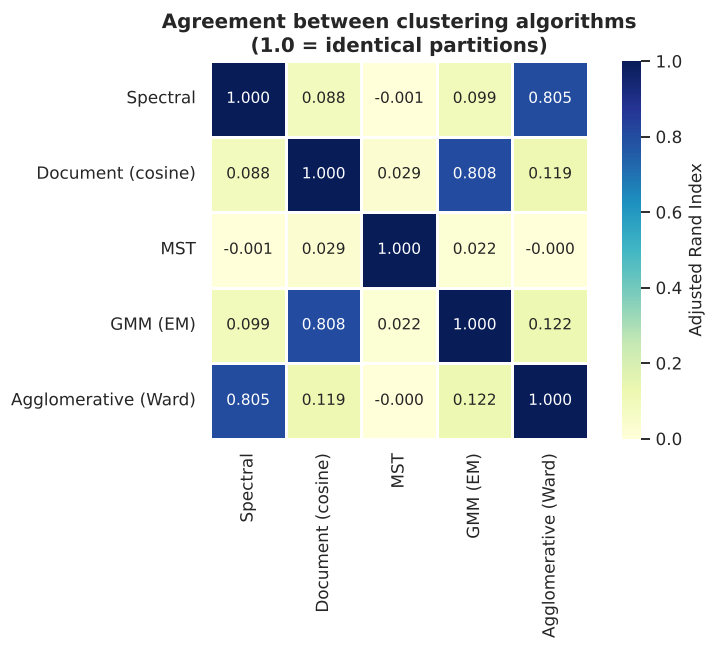

Adjusted Rand Index between every pair of algorithms:


,Spectral,Document (cosine),MST,GMM (EM),Agglomerative (Ward)
Spectral,1.0000,0.0881,-0.0009,0.0992,0.8046
Document (cosine),0.0881,1.0000,0.0288,0.8077,0.1194
MST,-0.0009,0.0288,1.0000,0.0218,-0.0002
GMM (EM),0.0992,0.8077,0.0218,1.0000,0.1221
Agglomerative (Ward),0.8046,0.1194,-0.0002,0.1221,1.0000


In [72]:
# Do the algorithms agree with each other?
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

names = list(algos.keys())
ari = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        ari.loc[a, b] = adjusted_rand_score(algos[a], algos[b])

plt.figure(figsize=(8, 6))
sns.heatmap(ari.astype(float), annot=True, fmt=".3f", cmap="YlGnBu",
            vmin=0, vmax=1, linewidths=0.7, square=True,
            cbar_kws={"label": "Adjusted Rand Index"})
plt.title("Agreement between clustering algorithms\n(1.0 = identical partitions)")
plt.tight_layout()
plt.show()

print("Adjusted Rand Index between every pair of algorithms:")
display(ari.astype(float).round(4))

In [73]:
# Interpreting the final clusters in plain clinical language
print("INTERPRETING THE FINAL CLUSTERS (Ward linkage)")
print("="*70)

profile = patient.groupby("cluster_agg").agg(
    n_patients       = ("id", "size"),
    mean_age         = ("age", "mean"),
    headache_rate    = ("headache_rate", "mean"),
    longest_streak   = ("longest_streak", "mean"),
    mean_airq        = ("mean_airq", "mean"),
    med_ord_mean     = ("med_ord_mean", "mean"),
    n_days           = ("n_days", "mean"),
    pct_female       = ("sex", lambda s: (s == "female").mean() * 100),
).round(3)
display(profile)

# Name the clusters by their headache burden
order = profile["headache_rate"].sort_values().index
names_map = {}
for rank, cid in enumerate(order):
    names_map[cid] = ["Low burden", "Moderate burden", "High burden"][rank] if K == 3 else f"Cluster {cid}"
patient["cluster_name"] = patient["cluster_agg"].map(names_map)

print("\nCluster labels assigned by headache burden:")
for cid, nm in names_map.items():
    r = profile.loc[cid]
    print(f"  Cluster {cid} -> '{nm}': {int(r['n_patients'])} patients, "
          f"headache rate {r['headache_rate']:.3f}, mean age {r['mean_age']:.1f}")

INTERPRETING THE FINAL CLUSTERS (Ward linkage)


,n_patients,mean_age,headache_rate,longest_streak,mean_airq,med_ord_mean,n_days,pct_female
cluster_agg,,,,,,,,
0,43,42.7440,0.4700,5.3720,29.0240,0.9530,30.1630,86.0470
1,45,37.6670,0.9100,19.7330,24.2610,1.4220,36.1560,86.6670
2,45,46.0890,0.5420,5.5330,21.5070,1.8890,27.2670,82.2220



Cluster labels assigned by headache burden:
  Cluster 0 -> 'Low burden': 43 patients, headache rate 0.470, mean age 42.7
  Cluster 2 -> 'Moderate burden': 45 patients, headache rate 0.542, mean age 46.1
  Cluster 1 -> 'High burden': 45 patients, headache rate 0.910, mean age 37.7


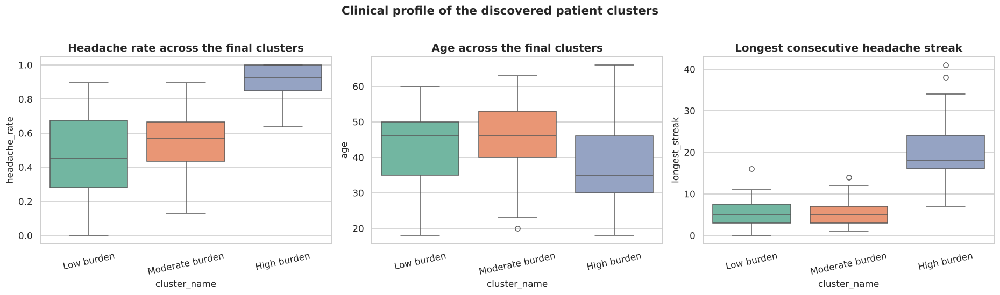

ANOVA across clusters on headache rate: F = 71.1628, p = 1.335e-21
-> The clusters differ significantly in headache burden.


In [74]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.boxplot(data=patient, x="cluster_name", y="headache_rate", ax=axes[0], palette="Set2",
            order=["Low burden", "Moderate burden", "High burden"])
axes[0].set_title("Headache rate across the final clusters")
axes[0].tick_params(axis="x", rotation=12)

sns.boxplot(data=patient, x="cluster_name", y="age", ax=axes[1], palette="Set2",
            order=["Low burden", "Moderate burden", "High burden"])
axes[1].set_title("Age across the final clusters")
axes[1].tick_params(axis="x", rotation=12)

sns.boxplot(data=patient, x="cluster_name", y="longest_streak", ax=axes[2], palette="Set2",
            order=["Low burden", "Moderate burden", "High burden"])
axes[2].set_title("Longest consecutive headache streak")
axes[2].tick_params(axis="x", rotation=12)

plt.suptitle("Clinical profile of the discovered patient clusters",
             fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

# Is the difference between clusters statistically real?
groups = [g["headache_rate"].values for _, g in patient.groupby("cluster_agg")]
f, p = stats.f_oneway(*groups)
print(f"ANOVA across clusters on headache rate: F = {f:.4f}, p = {p:.4g}")
print("->", "The clusters differ significantly in headache burden." if p < 0.05
      else "No significant difference.")

## 7.5 Outlier Detection Using Clustering

Clustering gives several independent handles on outlier detection, and I use four of them. The
agreement between methods is what makes a flag trustworthy — a point flagged by one method might be a
quirk of that method, but a point flagged by all four is genuinely anomalous.

1. **Distance to the nearest cluster centroid** — points far from every centre.
2. **GMM likelihood** — points the fitted mixture model considers improbable.
3. **MST edge length** — points attached to the tree by an unusually long edge.
4. **Small-cluster membership** — a cluster containing very few points is itself an anomaly group.

In [75]:
print("OUTLIER DETECTION VIA CLUSTERING")
print("="*70)

# --- (1) Distance to the nearest K-Means centroid ---
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X_clust)
centroid_dist = np.min(km.transform(X_clust), axis=1)
thr_dist = np.percentile(centroid_dist, 95)
out_centroid = centroid_dist > thr_dist

# --- (2) GMM log-likelihood ---
log_lik = gmm.score_samples(X_clust)
thr_lik = np.percentile(log_lik, 5)
out_gmm = log_lik < thr_lik

# --- (3) MST edge length: the longest edge touching each node ---
node_max_edge = np.zeros(len(X_clust))
for a, b, w in edges:
    node_max_edge[a] = max(node_max_edge[a], w)
    node_max_edge[b] = max(node_max_edge[b], w)
thr_mst = np.percentile(node_max_edge, 95)
out_mst = node_max_edge > thr_mst

# --- (4) Membership of a very small cluster ---
sizes = pd.Series(labels_agg).value_counts()
small_clusters = sizes[sizes < 0.05 * len(labels_agg)].index.tolist()
out_small = np.isin(labels_agg, small_clusters)

patient["out_centroid"] = out_centroid
patient["out_gmm"] = out_gmm
patient["out_mst"] = out_mst
patient["out_small_cluster"] = out_small
patient["outlier_votes"] = (out_centroid.astype(int) + out_gmm.astype(int) +
                            out_mst.astype(int) + out_small.astype(int))

print(f"(1) Far from nearest centroid (>95th pct)  : {out_centroid.sum()} patients")
print(f"(2) Low GMM likelihood        (<5th pct)   : {out_gmm.sum()} patients")
print(f"(3) Long MST edge             (>95th pct)  : {out_mst.sum()} patients")
print(f"(4) In a very small cluster   (<5% of n)   : {out_small.sum()} patients")

print("\nAgreement across methods:")
display(patient["outlier_votes"].value_counts().sort_index()
        .rename_axis("Number of methods flagging").to_frame("Patients"))

consensus = patient[patient["outlier_votes"] >= 2]
print(f"\nCONSENSUS OUTLIERS (flagged by at least 2 of 4 methods): {len(consensus)} patients")
display(consensus[["id", "age", "sex", "hatype", "headache_rate", "mean_airq",
                   "n_days", "longest_streak", "outlier_votes"]].round(3))

OUTLIER DETECTION VIA CLUSTERING
(1) Far from nearest centroid (>95th pct)  : 7 patients
(2) Low GMM likelihood        (<5th pct)   : 7 patients
(3) Long MST edge             (>95th pct)  : 7 patients
(4) In a very small cluster   (<5% of n)   : 0 patients

Agreement across methods:


,Patients
Number of methods flagging,
0,118
1,11
2,2
3,2



CONSENSUS OUTLIERS (flagged by at least 2 of 4 methods): 4 patients


,id,age,sex,hatype,headache_rate,mean_airq,n_days,longest_streak,outlier_votes
2,3,28,female,Aura,0.1290,24.4570,70,1,2
21,22,33,female,No Aura,0.7030,27.3300,91,10,3
23,24,34,female,No Aura,0.9840,25.4920,63,38,2
54,55,45,male,No Aura,0.6360,28.3310,121,22,3


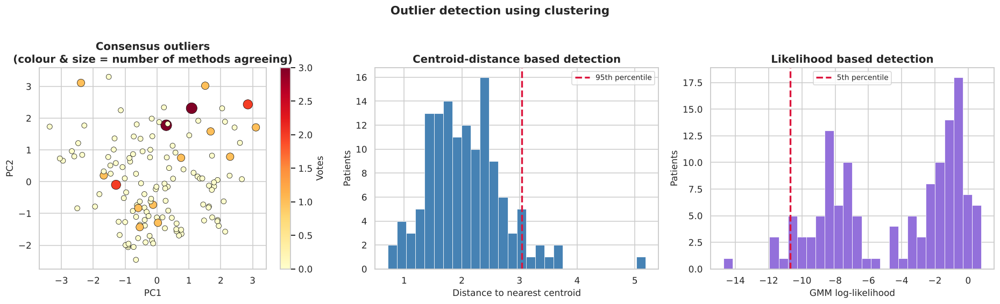

How do the consensus outliers differ from everyone else?


,age,headache_rate,mean_airq,n_days,longest_streak
is_outlier,,,,,
Typical patients,42.3800,0.6440,24.8220,29.5040,10.0540
Consensus outliers,35.0000,0.6130,26.4020,86.2500,17.7500


In [76]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Outliers in PCA space, sized by how many methods agree
sc = axes[0].scatter(X_2d[:,0], X_2d[:,1],
                     c=patient["outlier_votes"], cmap="YlOrRd",
                     s=40 + patient["outlier_votes"]*45,
                     edgecolor="black", linewidth=0.45)
axes[0].set_title("Consensus outliers\n(colour & size = number of methods agreeing)")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(sc, ax=axes[0], label="Votes")

# Distance to centroid
axes[1].hist(centroid_dist, bins=28, color="steelblue", edgecolor="white", linewidth=0.5)
axes[1].axvline(thr_dist, color="crimson", ls="--", lw=2.2, label="95th percentile")
axes[1].set_xlabel("Distance to nearest centroid"); axes[1].set_ylabel("Patients")
axes[1].set_title("Centroid-distance based detection")
axes[1].legend(fontsize=9)

# GMM likelihood
axes[2].hist(log_lik, bins=28, color="mediumpurple", edgecolor="white", linewidth=0.5)
axes[2].axvline(thr_lik, color="crimson", ls="--", lw=2.2, label="5th percentile")
axes[2].set_xlabel("GMM log-likelihood"); axes[2].set_ylabel("Patients")
axes[2].set_title("Likelihood based detection")
axes[2].legend(fontsize=9)

plt.suptitle("Outlier detection using clustering", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("How do the consensus outliers differ from everyone else?")
display(patient.assign(is_outlier=patient["outlier_votes"] >= 2)
        .groupby("is_outlier")[["age", "headache_rate", "mean_airq", "n_days", "longest_streak"]]
        .mean().round(3).rename(index={False: "Typical patients", True: "Consensus outliers"}))

### What I conclude from the clustering module

**The cohort has no natural number of clusters.** The silhouette scores across k = 2 to 8 are
remarkably flat — 0.198, 0.195, 0.204, 0.205, 0.206, 0.179, 0.183. There is no peak worth calling a
peak. If the data contained genuinely separated groups, one value of k would stand out clearly, and
none does. Combined with the MST's continuous edge-length distribution, this is consistent evidence
that patients vary **smoothly** rather than falling into discrete types. I chose K = 3 for clinical
interpretability, not because the data asked for three.

**The algorithms split into two families that disagree with each other.** The ARI heatmap is more
interesting than I expected. Spectral and Ward agree strongly (ARI = 0.80), and Document-clustering
and GMM agree strongly (ARI = 0.81) — but the two pairs agree with each other only weakly (ARI
0.09–0.12), and MST agrees with nothing (ARI ≈ 0.00). So there is no single "true" partition that the
methods are converging on from different directions. The first pair is cutting the severity
gradient; the second pair is largely recovering medication groups. **Which structure you find depends
on which algorithm you reach for**, and reporting only one would have given a misleadingly confident
picture.

**I was wrong about GMM soft assignment being ambiguous.** I expected a substantial share of
borderline patients, and predicted this in Section 7.3 before seeing the output. In fact only **2 of
133 patients (1.5%)** have a top-cluster probability below 0.8 — the mixture components are almost
perfectly separated in the posterior. The lesson is that **confident soft assignments do not imply
well-separated clusters**: the GMM silhouette is only 0.132, the lowest of the non-degenerate
methods. A fitted mixture model will always assign confidently if its components have sufficiently
different covariances, whether or not the groups are genuinely distinct.

**Ward linkage gave the most usable partition**, producing three balanced groups (43 / 45 / 45) with
a strongly significant ANOVA across them (F = 71.2, p ≈ 1e-21). The "high burden" group is genuinely
distinctive — a headache rate of 0.91 and a mean longest streak of 19.7 consecutive days, against 5.4
days for the other two. The boundary between the low and moderate groups (rates 0.47 and 0.54) is far
more arbitrary and I would not defend it.

**The consensus outliers are not what I assumed.** I expected short-diary artefacts. In fact all four
flagged patients have **long** diaries (63 to 121 days), so their headache rates are well estimated
rather than noisy. They are flagged for being genuinely extreme: patient 24 has a rate of 0.984 with
a 38-day unbroken headache streak, patient 3 sits at the opposite end with a rate of 0.129, and
patients 22 and 55 have unusual streak-to-rate combinations. These are real clinical extremes, which
makes them more interesting than artefacts — and it means I should **not** remove them from the
analysis.

---

# MODULE 6 — Dimensionality Reduction

> **Syllabus:** Linear Methods: Principal Component Analysis (PCA) — Singular Value Decomposition —
> Factor Analysis — Intrinsic Dimensionality. Non Linear methods: Multidimensional Scaling —
> Manifold Learning — Self-Organizing Maps.

**Why reduce dimensions at all here?** My patient feature matrix has 7 features for 133 patients. The
features are not independent — `headache_rate` and `longest_streak` obviously overlap, and `n_days`
relates to `study_length`. Dimensionality reduction answers two practical questions: how many
*genuinely independent* pieces of information do these 7 columns contain, and can I project them into
2-D for visualisation without destroying the structure?

In [77]:
print("DIMENSIONALITY REDUCTION SETUP")
print("="*70)

dr_features = ["age", "headache_rate", "mean_airq", "std_airq",
               "n_days", "longest_streak", "med_ord_mean"]
X_dr_raw = patient[dr_features].fillna(patient[dr_features].median())
X_dr = StandardScaler().fit_transform(X_dr_raw)

print(f"Input matrix: {X_dr.shape[0]} patients x {X_dr.shape[1]} features")
print(f"Features    : {dr_features}")
print("\nCorrelation between the input features (redundancy is what PCA exploits):")
display(pd.DataFrame(X_dr, columns=dr_features).corr().round(3))

DIMENSIONALITY REDUCTION SETUP
Input matrix: 133 patients x 7 features
Features    : ['age', 'headache_rate', 'mean_airq', 'std_airq', 'n_days', 'longest_streak', 'med_ord_mean']

Correlation between the input features (redundancy is what PCA exploits):


,age,headache_rate,mean_airq,std_airq,n_days,longest_streak,med_ord_mean
age,1.0000,-0.1330,0.0080,0.0170,0.0330,-0.1060,0.0380
headache_rate,-0.1330,1.0000,-0.0240,-0.0460,-0.0070,0.7610,0.2340
mean_airq,0.0080,-0.0240,1.0000,0.5990,-0.0140,0.0220,-0.1300
std_airq,0.0170,-0.0460,0.5990,1.0000,0.0770,0.0670,-0.2380
n_days,0.0330,-0.0070,-0.0140,0.0770,1.0000,0.2560,-0.0980
longest_streak,-0.1060,0.7610,0.0220,0.0670,0.2560,1.0000,0.1230
med_ord_mean,0.0380,0.2340,-0.1300,-0.2380,-0.0980,0.1230,1.0000


## 8.1 Principal Component Analysis (PCA)

PCA finds a new set of orthogonal axes — the principal components — ordered so that the first
captures the greatest possible variance, the second the greatest remaining variance orthogonal to the
first, and so on. Each component is a **linear combination of the original features**, and the
loadings tell me what each component actually means.

In [78]:
print("PRINCIPAL COMPONENT ANALYSIS")
print("="*70)

pca_full = PCA(random_state=RANDOM_STATE)
X_pca = pca_full.fit_transform(X_dr)

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

pca_table = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(evr))],
    "Eigenvalue": pca_full.explained_variance_,
    "Explained variance %": evr * 100,
    "Cumulative %": cum_evr * 100
})
display(pca_table.round(4))

n_90 = int(np.argmax(cum_evr >= 0.90) + 1)
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)
kaiser = int((pca_full.explained_variance_ > 1).sum())

print(f"\nComponents needed to retain 90% of variance : {n_90}")
print(f"Components needed to retain 95% of variance : {n_95}")
print(f"Kaiser criterion (eigenvalue > 1)           : {kaiser} components")

PRINCIPAL COMPONENT ANALYSIS


,Component,Eigenvalue,Explained variance %,Cumulative %
0,PC1,1.9107,27.0906,27.0906
1,PC2,1.7105,24.2518,51.3424
2,PC3,1.0920,15.4833,66.8257
3,PC4,1.0202,14.4647,81.2903
4,PC5,0.7403,10.4964,91.7867
5,PC6,0.3889,5.5146,97.3014
6,PC7,0.1903,2.6986,100.0000



Components needed to retain 90% of variance : 5
Components needed to retain 95% of variance : 6
Kaiser criterion (eigenvalue > 1)           : 4 components


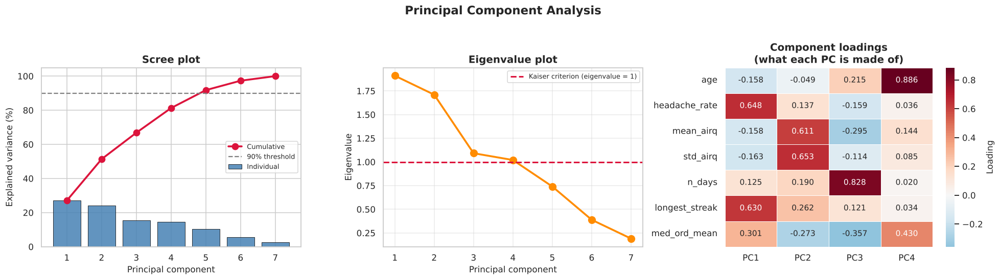

Loadings on the first four components:


,PC1,PC2,PC3,PC4
age,-0.1583,-0.0493,0.2150,0.8858
headache_rate,0.6484,0.1372,-0.1591,0.0363
mean_airq,-0.1579,0.6106,-0.2954,0.1440
std_airq,-0.1632,0.6531,-0.1136,0.0849
n_days,0.1250,0.1904,0.8283,0.0204
longest_streak,0.6299,0.2616,0.1208,0.0339
med_ord_mean,0.3010,-0.2735,-0.3573,0.4296


In [79]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# Scree plot
axes[0].bar(range(1, len(evr)+1), evr*100, color="steelblue",
            edgecolor="black", linewidth=0.6, alpha=0.85, label="Individual")
axes[0].plot(range(1, len(evr)+1), cum_evr*100, "o-", color="crimson",
             lw=2.4, markersize=8, label="Cumulative")
axes[0].axhline(90, ls="--", color="gray", lw=1.5, label="90% threshold")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance (%)")
axes[0].set_title("Scree plot")
axes[0].legend(fontsize=8.5)

# Eigenvalues with Kaiser line
axes[1].plot(range(1, len(evr)+1), pca_full.explained_variance_, "o-",
             lw=2.4, markersize=9, color="darkorange")
axes[1].axhline(1.0, ls="--", color="crimson", lw=2, label="Kaiser criterion (eigenvalue = 1)")
axes[1].set_xlabel("Principal component"); axes[1].set_ylabel("Eigenvalue")
axes[1].set_title("Eigenvalue plot")
axes[1].legend(fontsize=8.5); axes[1].grid(alpha=0.4)

# Loadings heatmap
loadings = pd.DataFrame(
    pca_full.components_[:4].T,
    columns=[f"PC{i+1}" for i in range(4)],
    index=dr_features
)
sns.heatmap(loadings, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            linewidths=0.6, ax=axes[2], cbar_kws={"label": "Loading"})
axes[2].set_title("Component loadings\n(what each PC is made of)")

plt.suptitle("Principal Component Analysis", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

print("Loadings on the first four components:")
display(loadings.round(4))

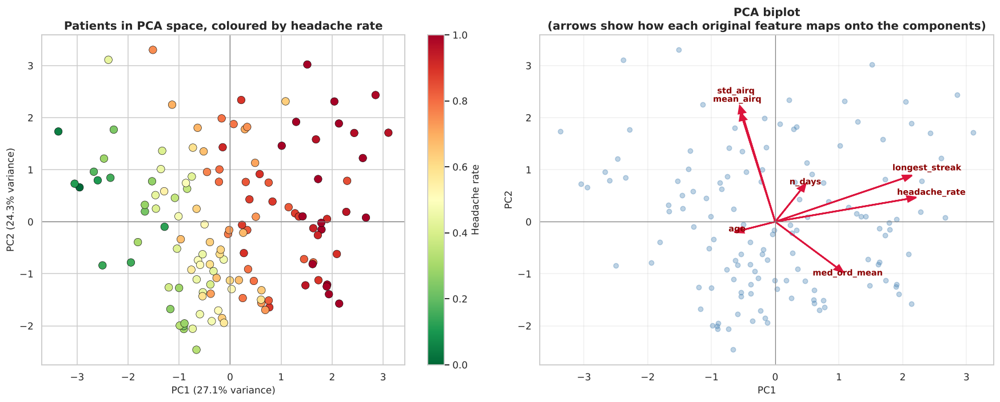

In [80]:
# Biplot: patients and feature directions on the same axes
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca2.fit_transform(X_dr)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sc = axes[0].scatter(X_pca2[:,0], X_pca2[:,1], c=patient["headache_rate"],
                     cmap="RdYlGn_r", s=78, edgecolor="black", linewidth=0.4)
axes[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} variance)")
axes[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} variance)")
axes[0].set_title("Patients in PCA space, coloured by headache rate")
axes[0].axhline(0, color="gray", lw=0.8); axes[0].axvline(0, color="gray", lw=0.8)
plt.colorbar(sc, ax=axes[0], label="Headache rate")

# Biplot
axes[1].scatter(X_pca2[:,0], X_pca2[:,1], s=30, alpha=0.35, color="steelblue")
scale = 3.2
for i, feat in enumerate(dr_features):
    axes[1].arrow(0, 0, pca2.components_[0,i]*scale, pca2.components_[1,i]*scale,
                  head_width=0.11, head_length=0.14, fc="crimson", ec="crimson", lw=1.8)
    axes[1].text(pca2.components_[0,i]*scale*1.18, pca2.components_[1,i]*scale*1.18,
                 feat, color="darkred", fontsize=9.5, fontweight="bold", ha="center")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("PCA biplot\n(arrows show how each original feature maps onto the components)")
axes[1].axhline(0, color="gray", lw=0.8); axes[1].axvline(0, color="gray", lw=0.8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**PCA observation.** The scree plot declines gradually with no sharp elbow, and PC1 captures only
**27.1%** of the variance — it takes **5 components to reach 90%**. That is itself the finding: my
features are **not** heavily redundant, so there is no dramatic compression available. Had two or
three components captured 95%, I would have concluded the 7 features were mostly measuring the same
thing. They are not. (The Kaiser criterion of eigenvalue > 1 suggests 4 components, which is
consistent.)

The loadings make each component interpretable, and they sort the features into clean groups:

- **PC1 (27.1%) is the severity axis** — `headache_rate` (0.648) and `longest_streak` (0.630) load
  almost equally, with `med_ord_mean` (0.301) following. This is exactly the gradient the clustering
  module kept running into, now isolated as a single direction.
- **PC2 (24.3%) is the air-quality axis** — `std_airq` (0.653) and `mean_airq` (0.611), with
  essentially nothing else on it.
- **PC3 (15.5%) is diary length** — `n_days` at 0.828, almost alone on its own component.
- **PC4 (14.5%) is age** — `age` at 0.886, again almost alone.

The fact that air quality, diary length and age each claim a nearly private component is the clearest
statement in the notebook that **these variables are independent of the severity story**. They are
not weak contributors to a shared structure; they are separate structures.

The biplot confirms this geometrically: the headache-burden arrows cluster together, while the `airq`
arrows point off at close to a right angle, and `age` elsewhere again.

## 8.2 Singular Value Decomposition (SVD)

SVD is the matrix factorisation that underlies PCA: it decomposes **X = U Σ Vᵀ**. When applied to
centred data, the right singular vectors **V** are exactly the principal components and the singular
values relate to the eigenvalues by σ² = (n−1)λ. I verify that identity numerically below, because
the relationship is easier to trust once you have seen it reproduced.

In [81]:
print("SINGULAR VALUE DECOMPOSITION")
print("="*70)

X_centered = X_dr - X_dr.mean(axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

print(f"U  (left singular vectors) : {U.shape}")
print(f"S  (singular values)       : {S.shape}")
print(f"Vt (right singular vectors): {Vt.shape}")
print(f"\nSingular values: {np.round(S, 4)}")

# Verify the SVD <-> PCA identity
eig_from_svd = (S ** 2) / (len(X_centered) - 1)
print("\nVERIFYING THE SVD-PCA RELATIONSHIP:")
verify = pd.DataFrame({
    "Eigenvalue from PCA": pca_full.explained_variance_,
    "S^2/(n-1) from SVD": eig_from_svd,
    "Absolute difference": np.abs(pca_full.explained_variance_ - eig_from_svd)
})
display(verify.round(10))
print(f"-> Maximum discrepancy: {np.abs(pca_full.explained_variance_ - eig_from_svd).max():.2e}")
print("   The two are numerically identical, confirming PCA is SVD on centred data.")

# Variance explained by each singular value
svd_var = (S**2) / (S**2).sum()
print(f"\nVariance share per singular value: {np.round(svd_var*100, 3)}")

SINGULAR VALUE DECOMPOSITION
U  (left singular vectors) : (133, 7)
S  (singular values)       : (7,)
Vt (right singular vectors): (7, 7)

Singular values: [15.8812 15.0261 12.0062 11.6046  9.8854  7.1653  5.0124]

VERIFYING THE SVD-PCA RELATIONSHIP:


,Eigenvalue from PCA,S^2/(n-1) from SVD,Absolute difference
0,1.9107,1.9107,0.0000
1,1.7105,1.7105,0.0000
2,1.0920,1.0920,0.0000
3,1.0202,1.0202,0.0000
4,0.7403,0.7403,0.0000
5,0.3889,0.3889,0.0000
6,0.1903,0.1903,0.0000


-> Maximum discrepancy: 1.22e-15
   The two are numerically identical, confirming PCA is SVD on centred data.

Variance share per singular value: [27.091 24.252 15.483 14.465 10.496  5.515  2.699]


LOW-RANK RECONSTRUCTION QUALITY


,Rank,Relative Frobenius error,Variance retained %,Compression ratio
0,1,0.8539,27.0906,14.3%
1,2,0.6976,51.3424,28.6%
2,3,0.5760,66.8257,42.9%
3,4,0.4325,81.2903,57.1%
4,5,0.2866,91.7867,71.4%
5,6,0.1643,97.3013,85.7%
6,7,0.0000,100.0000,100.0%


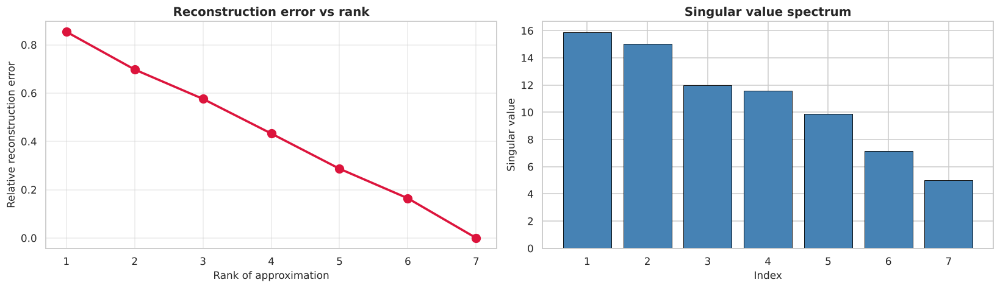

TruncatedSVD with 2 components retains 51.34% of variance.


In [82]:
# Low-rank reconstruction: how much of the matrix survives at each rank?
print("LOW-RANK RECONSTRUCTION QUALITY")
print("="*70)

recon_rows = []
for r in range(1, len(S)+1):
    X_r = U[:, :r] @ np.diag(S[:r]) @ Vt[:r, :]
    err = np.linalg.norm(X_centered - X_r, "fro") / np.linalg.norm(X_centered, "fro")
    recon_rows.append({"Rank": r, "Relative Frobenius error": err,
                       "Variance retained %": svd_var[:r].sum()*100,
                       "Compression ratio": f"{r/len(S):.1%}"})
display(pd.DataFrame(recon_rows).round(5))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
rr = pd.DataFrame(recon_rows)
axes[0].plot(rr["Rank"], rr["Relative Frobenius error"], "o-", lw=2.4,
             markersize=9, color="crimson")
axes[0].set_xlabel("Rank of approximation"); axes[0].set_ylabel("Relative reconstruction error")
axes[0].set_title("Reconstruction error vs rank")
axes[0].grid(alpha=0.4)

axes[1].bar(range(1, len(S)+1), S, color="steelblue", edgecolor="black", linewidth=0.6)
axes[1].set_xlabel("Index"); axes[1].set_ylabel("Singular value")
axes[1].set_title("Singular value spectrum")

plt.tight_layout()
plt.show()

# TruncatedSVD as the practical sklearn interface
tsvd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
X_tsvd = tsvd.fit_transform(X_dr)
print(f"TruncatedSVD with 2 components retains {tsvd.explained_variance_ratio_.sum():.2%} of variance.")

## 8.3 Factor Analysis

Factor analysis looks superficially like PCA but answers a different question. PCA asks *"what
combination of my variables captures the most variance?"* — it is a descriptive rotation. Factor
analysis asks *"what unobserved latent variables could have generated the correlations I observe?"* —
it is a generative model.

The practical difference: FA explicitly separates **common variance** (shared across variables,
attributed to the latent factors) from **unique variance** (noise specific to each variable). For
this dataset, the natural hypothesis is that an unobservable "migraine severity" factor drives
several of my measured features at once.

In [83]:
print("FACTOR ANALYSIS")
print("="*70)

# Is factor analysis even appropriate? Bartlett's test of sphericity.
corr_m = np.corrcoef(X_dr, rowvar=False)
n, p = X_dr.shape
chi_sq = -(n - 1 - (2*p + 5)/6) * np.log(np.linalg.det(corr_m))
dof_b = p*(p-1)/2
p_bartlett = 1 - stats.chi2.cdf(chi_sq, dof_b)
print(f"Bartlett's test of sphericity: chi2 = {chi_sq:.4f}, dof = {dof_b:.0f}, p = {p_bartlett:.4g}")
print("->", "The correlation matrix differs from identity; factor analysis is justified."
      if p_bartlett < 0.05 else "Variables are near-uncorrelated; FA may not be worthwhile.")

# Fit factor analysis across a range of factor counts
fa_rows = []
for k in range(1, 6):
    fa = FactorAnalysis(n_components=k, random_state=RANDOM_STATE, max_iter=2000)
    fa.fit(X_dr)
    ll = fa.score(X_dr) * len(X_dr)
    n_params = p*k + p
    fa_rows.append({"Factors": k, "Log-likelihood": ll,
                    "BIC": -2*ll + n_params*np.log(n),
                    "AIC": -2*ll + 2*n_params})
fa_sel = pd.DataFrame(fa_rows)
display(fa_sel.round(3))

best_k_fa = int(fa_sel.loc[fa_sel["BIC"].idxmin(), "Factors"])
print(f"\nBest number of factors by BIC: {best_k_fa}")

FACTOR ANALYSIS
Bartlett's test of sphericity: chi2 = 214.4415, dof = 21, p = 0
-> The correlation matrix differs from identity; factor analysis is justified.


,Factors,Log-likelihood,BIC,AIC
0,1,"-1,258.8610","2,586.1860","2,545.7210"
1,2,"-1,222.2330","2,547.1640","2,486.4670"
2,3,"-1,211.1960","2,559.3220","2,478.3930"
3,4,"-1,210.4280","2,592.0190","2,490.8560"
4,5,"-1,210.3510","2,626.0970","2,504.7020"



Best number of factors by BIC: 2


FACTOR ANALYSIS WITH 2 FACTORS

Loadings, communality (variance explained by the factors) and uniqueness (noise):


,Factor 1,Factor 2,Communality,Uniqueness
age,-0.1164,0.0290,0.0144,0.9856
headache_rate,0.7915,-0.1356,0.6448,0.3545
mean_airq,0.0465,0.6455,0.4188,0.5808
std_airq,0.0963,0.9139,0.8445,0.1562
n_days,0.2279,0.0633,0.0560,0.9442
longest_streak,0.9544,-0.0265,0.9115,0.0894
med_ord_mean,0.1371,-0.2727,0.0931,0.9067


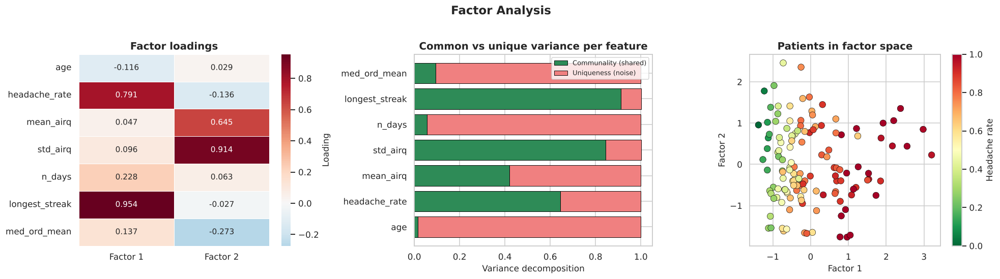

In [84]:
N_FACTORS = 2
fa = FactorAnalysis(n_components=N_FACTORS, random_state=RANDOM_STATE, max_iter=2000)
X_fa = fa.fit_transform(X_dr)

fa_loadings = pd.DataFrame(fa.components_.T,
                           columns=[f"Factor {i+1}" for i in range(N_FACTORS)],
                           index=dr_features)
fa_loadings["Communality"] = (fa_loadings.iloc[:, :N_FACTORS]**2).sum(axis=1)
fa_loadings["Uniqueness"] = fa.noise_variance_

print(f"FACTOR ANALYSIS WITH {N_FACTORS} FACTORS")
print("="*70)
print("\nLoadings, communality (variance explained by the factors) and uniqueness (noise):")
display(fa_loadings.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

sns.heatmap(fa_loadings[[f"Factor {i+1}" for i in range(N_FACTORS)]],
            annot=True, fmt=".3f", cmap="RdBu_r", center=0, linewidths=0.6,
            ax=axes[0], cbar_kws={"label": "Loading"})
axes[0].set_title("Factor loadings")

axes[1].barh(fa_loadings.index, fa_loadings["Communality"], color="seagreen",
             edgecolor="black", linewidth=0.6, label="Communality (shared)")
axes[1].barh(fa_loadings.index, fa_loadings["Uniqueness"],
             left=fa_loadings["Communality"], color="lightcoral",
             edgecolor="black", linewidth=0.6, label="Uniqueness (noise)")
axes[1].set_xlabel("Variance decomposition")
axes[1].set_title("Common vs unique variance per feature")
axes[1].legend(fontsize=8.5)

sc = axes[2].scatter(X_fa[:,0], X_fa[:,1], c=patient["headache_rate"],
                     cmap="RdYlGn_r", s=68, edgecolor="black", linewidth=0.4)
axes[2].set_xlabel("Factor 1"); axes[2].set_ylabel("Factor 2")
axes[2].set_title("Patients in factor space")
plt.colorbar(sc, ax=axes[2], label="Headache rate")

plt.suptitle("Factor Analysis", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**PCA vs Factor Analysis — what I actually learned.** BIC selects **2 factors**, and the loadings
split the features into two clean, independent constructs:

- **Factor 1 is migraine severity** — `longest_streak` (0.954) and `headache_rate` (0.792) load
  heavily and nothing else does.
- **Factor 2 is air-quality exposure** — `std_airq` (0.914) and `mean_airq` (0.646).

The communality column is the payoff, and it is sharper than PCA's. `longest_streak` has communality
0.912 and `std_airq` 0.845, meaning the latent factors explain the overwhelming majority of their
variance. At the other end, **`age` has a communality of 0.014 and a uniqueness of 0.986** — in other
words, roughly 99% of the variance in age is specific to age and shares nothing with any common
factor. `n_days` (0.056) and `med_ord_mean` (0.093) are nearly as isolated.

**This is a cleaner statement than PCA can make, and it is the most decisive evidence in the notebook
on the age question.** PCA was obliged to give `age` a loading somewhere, because PCA must account
for *all* variance including the purely idiosyncratic part — and it duly handed age its own fourth
component. Factor analysis is free to say "this variable is almost entirely its own noise", and it
does. For deciding what belongs in a model, that is the more useful answer, and it independently
corroborates the weak age associations found back in Module 3.

## 8.4 Intrinsic Dimensionality

Intrinsic dimensionality asks: **how many dimensions does the data actually occupy?** My features live
in 7-dimensional space, but if they are correlated the points may really lie on a lower-dimensional
surface embedded in it. I estimate this three independent ways, because no single estimator is
reliable on its own:

1. **PCA-based** — the number of components needed to retain 90–95% of variance.
2. **Participation ratio** — a continuous estimate from the eigenvalue spectrum that does not require
   an arbitrary threshold.
3. **Levina–Bickel maximum-likelihood estimator** — a nearest-neighbour method that estimates the
   local dimension from how the number of neighbours grows with radius, making no linearity
   assumption at all.

In [85]:
print("INTRINSIC DIMENSIONALITY ESTIMATION")
print("="*70)

# --- Method 1: PCA variance thresholds ---
print("\nMETHOD 1 | PCA variance thresholds")
for thr in [0.80, 0.90, 0.95, 0.99]:
    nc = int(np.argmax(cum_evr >= thr) + 1)
    print(f"  Retain {thr:.0%} of variance -> {nc} dimensions")

# --- Method 2: Participation ratio ---
eigs = pca_full.explained_variance_
participation_ratio = (eigs.sum()**2) / (eigs**2).sum()
print(f"\nMETHOD 2 | Participation ratio: {participation_ratio:.4f}")
print("  (A continuous estimate - no arbitrary variance cut-off required.)")

# --- Method 3: Levina-Bickel MLE ---
def levina_bickel_mle(X, k1=10, k2=20):
    '''Maximum-likelihood estimator of intrinsic dimension from k-nearest-neighbour distances.'''
    from sklearn.neighbors import NearestNeighbors
    n = len(X)
    nbrs = NearestNeighbors(n_neighbors=k2+1).fit(X)
    dists, _ = nbrs.kneighbors(X)
    dists = dists[:, 1:]            # drop the point itself
    estimates = []
    for k in range(k1, k2+1):
        Tk = dists[:, k-1]
        with np.errstate(divide="ignore", invalid="ignore"):
            logs = np.log(Tk[:, None] / dists[:, :k-1])
        m_k = (k - 2) / np.nansum(logs, axis=1)
        estimates.append(np.nanmean(m_k[np.isfinite(m_k)]))
    return float(np.mean(estimates)), estimates

mle_dim, mle_per_k = levina_bickel_mle(X_dr)
print(f"\nMETHOD 3 | Levina-Bickel MLE: {mle_dim:.4f}")
print("  (Nearest-neighbour based - makes NO linearity assumption.)")

print("\n" + "="*70)
print("CONSENSUS ESTIMATE")
print("="*70)
print(f"  Ambient (measured) dimensionality : {X_dr.shape[1]}")
print(f"  PCA @ 90% variance                : {n_90}")
print(f"  Participation ratio               : {participation_ratio:.2f}")
print(f"  Levina-Bickel MLE                 : {mle_dim:.2f}")
print(f"  -> Intrinsic dimensionality is approximately {int(round(np.mean([n_90, participation_ratio, mle_dim])))}")

INTRINSIC DIMENSIONALITY ESTIMATION

METHOD 1 | PCA variance thresholds
  Retain 80% of variance -> 4 dimensions
  Retain 90% of variance -> 5 dimensions
  Retain 95% of variance -> 6 dimensions
  Retain 99% of variance -> 7 dimensions

METHOD 2 | Participation ratio: 5.2114
  (A continuous estimate - no arbitrary variance cut-off required.)

METHOD 3 | Levina-Bickel MLE: 4.6818
  (Nearest-neighbour based - makes NO linearity assumption.)

CONSENSUS ESTIMATE
  Ambient (measured) dimensionality : 7
  PCA @ 90% variance                : 5
  Participation ratio               : 5.21
  Levina-Bickel MLE                 : 4.68
  -> Intrinsic dimensionality is approximately 5


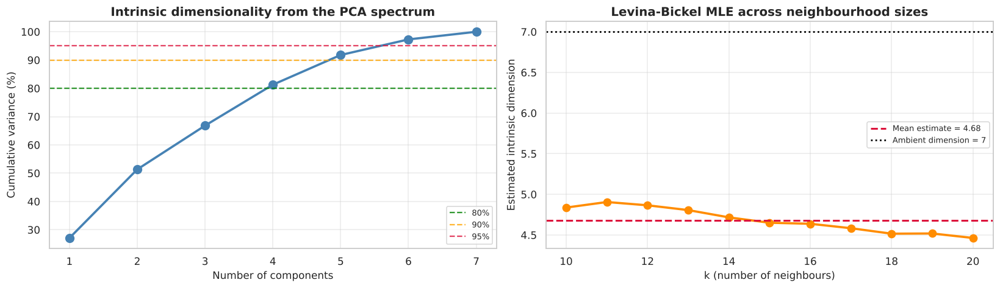

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))

axes[0].plot(range(1, len(cum_evr)+1), cum_evr*100, "o-", lw=2.4, markersize=9, color="steelblue")
for thr, c in [(80, "green"), (90, "orange"), (95, "crimson")]:
    axes[0].axhline(thr, ls="--", color=c, lw=1.5, alpha=0.8, label=f"{thr}%")
axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("Cumulative variance (%)")
axes[0].set_title("Intrinsic dimensionality from the PCA spectrum")
axes[0].legend(fontsize=8.5); axes[0].grid(alpha=0.4)

axes[1].plot(range(10, 21), mle_per_k, "o-", lw=2.4, markersize=8, color="darkorange")
axes[1].axhline(mle_dim, ls="--", color="crimson", lw=2,
                label=f"Mean estimate = {mle_dim:.2f}")
axes[1].axhline(X_dr.shape[1], ls=":", color="black", lw=1.8,
                label=f"Ambient dimension = {X_dr.shape[1]}")
axes[1].set_xlabel("k (number of neighbours)"); axes[1].set_ylabel("Estimated intrinsic dimension")
axes[1].set_title("Levina-Bickel MLE across neighbourhood sizes")
axes[1].legend(fontsize=8.5); axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

**Intrinsic dimensionality observation.** The three estimators agree closely — PCA at 90% variance
gives 5, the participation ratio gives 5.21, and the Levina–Bickel MLE gives 4.68. The consensus is
therefore about **5 dimensions out of an ambient 7**, and the Levina–Bickel estimate is stable across
neighbourhood sizes, which matters: had it swung wildly with `k`, I would not trust it.

**The compression available here is small**, and that is the real result. My 7 features occupy
roughly 5 genuine dimensions — they are close to independent, exactly as the PCA components and the
factor-analysis uniqueness values both indicated.

This has two practical implications. First, compressing to 2 dimensions for visualisation **discards
a great deal**, so every 2-D scatter plot in this module should be read as a rough summary rather
than a faithful map. Second, it explains why clustering struggled: real structure is spread across
about five dimensions, and no planar view — or planar distance metric — can capture it.

## 8.5 Non-Linear Method: Multidimensional Scaling (MDS)

MDS takes a different starting point from PCA. Instead of the data matrix, it takes the **matrix of
pairwise distances** and finds a low-dimensional arrangement of points whose distances match the
originals as closely as possible. The quality of the fit is measured by **stress** — lower is better.

Because MDS only needs distances, it works on data where no coordinate representation exists at all
(similarity judgements, genetic distances), which is its real advantage over PCA.

In [87]:
print("MULTIDIMENSIONAL SCALING")
print("="*70)

# Metric MDS - tries to preserve the actual distances
mds_metric = MDS(n_components=2, metric=True, random_state=RANDOM_STATE,
                 n_init=4, max_iter=400, normalized_stress=False)
X_mds = mds_metric.fit_transform(X_dr)
print(f"Metric MDS     : stress = {mds_metric.stress_:.4f}")

# Non-metric MDS - preserves only the ORDER of distances
mds_nonmetric = MDS(n_components=2, metric=False, random_state=RANDOM_STATE,
                    n_init=4, max_iter=400, normalized_stress="auto")
X_mds_nm = mds_nonmetric.fit_transform(X_dr)
print(f"Non-metric MDS : stress = {mds_nonmetric.stress_:.4f}")

# Shepard diagram: how faithfully are the original distances reproduced?
orig_d = pdist(X_dr)
mds_d = pdist(X_mds)
shepard_r = np.corrcoef(orig_d, mds_d)[0, 1]
print(f"\nCorrelation between original and MDS distances: {shepard_r:.4f}")
print("(Close to 1.0 means the 2-D layout faithfully represents the 7-D distances.)")

# Stress across increasing dimensions
stress_vals = []
for d in range(1, 6):
    m = MDS(n_components=d, random_state=RANDOM_STATE, n_init=2,
            max_iter=250, normalized_stress=False)
    m.fit(X_dr)
    stress_vals.append(m.stress_)
    print(f"  MDS in {d}-D: stress = {m.stress_:.4f}")

MULTIDIMENSIONAL SCALING


Metric MDS     : stress = 7627.0653


Non-metric MDS : stress = 0.2263

Correlation between original and MDS distances: 0.8478
(Close to 1.0 means the 2-D layout faithfully represents the 7-D distances.)
  MDS in 1-D: stress = 25216.0507


  MDS in 2-D: stress = 7674.5859


  MDS in 3-D: stress = 3062.4547


  MDS in 4-D: stress = 1015.3438
  MDS in 5-D: stress = 270.0876


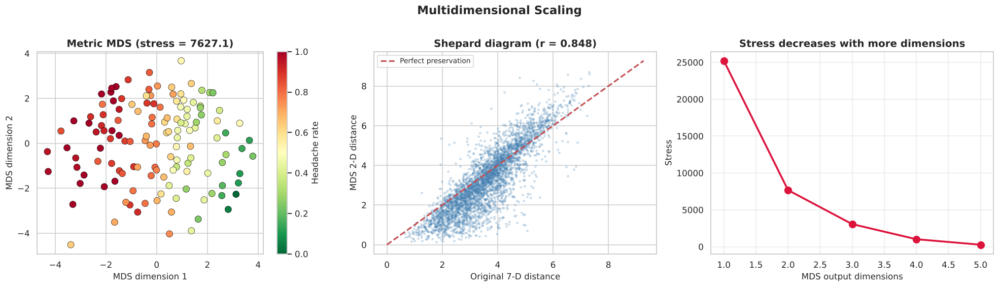

In [88]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sc = axes[0].scatter(X_mds[:,0], X_mds[:,1], c=patient["headache_rate"],
                     cmap="RdYlGn_r", s=72, edgecolor="black", linewidth=0.4)
axes[0].set_title(f"Metric MDS (stress = {mds_metric.stress_:.1f})")
axes[0].set_xlabel("MDS dimension 1"); axes[0].set_ylabel("MDS dimension 2")
plt.colorbar(sc, ax=axes[0], label="Headache rate")

# Shepard diagram
idx = np.random.default_rng(RANDOM_STATE).choice(len(orig_d), size=min(4000, len(orig_d)), replace=False)
axes[1].scatter(orig_d[idx], mds_d[idx], s=5, alpha=0.2, color="steelblue")
lims = [0, max(orig_d.max(), mds_d.max())]
axes[1].plot(lims, lims, "r--", lw=2, label="Perfect preservation")
axes[1].set_xlabel("Original 7-D distance"); axes[1].set_ylabel("MDS 2-D distance")
axes[1].set_title(f"Shepard diagram (r = {shepard_r:.3f})")
axes[1].legend(fontsize=9)

axes[2].plot(range(1, 6), stress_vals, "o-", lw=2.4, markersize=9, color="crimson")
axes[2].set_xlabel("MDS output dimensions"); axes[2].set_ylabel("Stress")
axes[2].set_title("Stress decreases with more dimensions")
axes[2].grid(alpha=0.4)

plt.suptitle("Multidimensional Scaling", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8.6 Non-Linear Method: Manifold Learning

Manifold learning assumes the data lies on a curved low-dimensional surface embedded in the
high-dimensional space — the classic example being a "Swiss roll", where two points can be close in
Euclidean distance but far apart along the surface itself. Linear methods like PCA cannot unroll
such a structure; manifold methods can.

- **Isomap** preserves *geodesic* distances — shortest paths through a neighbourhood graph rather
  than straight lines through the ambient space.
- **Locally Linear Embedding (LLE)** preserves each point's reconstruction from its neighbours, so it
  keeps local geometry intact while allowing the global shape to deform.

In [89]:
print("MANIFOLD LEARNING")
print("="*70)

# Isomap
iso = Isomap(n_components=2, n_neighbors=10)
X_iso = iso.fit_transform(X_dr)
print(f"Isomap reconstruction error: {iso.reconstruction_error():.4f}")

# LLE (standard and modified)
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=12,
                             method="standard", random_state=RANDOM_STATE)
X_lle = lle.fit_transform(X_dr)
print(f"LLE reconstruction error   : {lle.reconstruction_error_:.6e}")

lle_mod = LocallyLinearEmbedding(n_components=2, n_neighbors=12,
                                 method="modified", random_state=RANDOM_STATE)
X_lle_mod = lle_mod.fit_transform(X_dr)
print(f"Modified LLE error         : {lle_mod.reconstruction_error_:.6e}")

# How does Isomap's geodesic distance differ from straight-line distance?
geo_d = pdist(X_iso)
print(f"\nCorrelation of Isomap 2-D distances with original distances: "
      f"{np.corrcoef(orig_d, geo_d)[0,1]:.4f}")

MANIFOLD LEARNING
Isomap reconstruction error: 3.4620
LLE reconstruction error   : 1.225489e-05


Modified LLE error         : 9.581870e-01

Correlation of Isomap 2-D distances with original distances: 0.7242


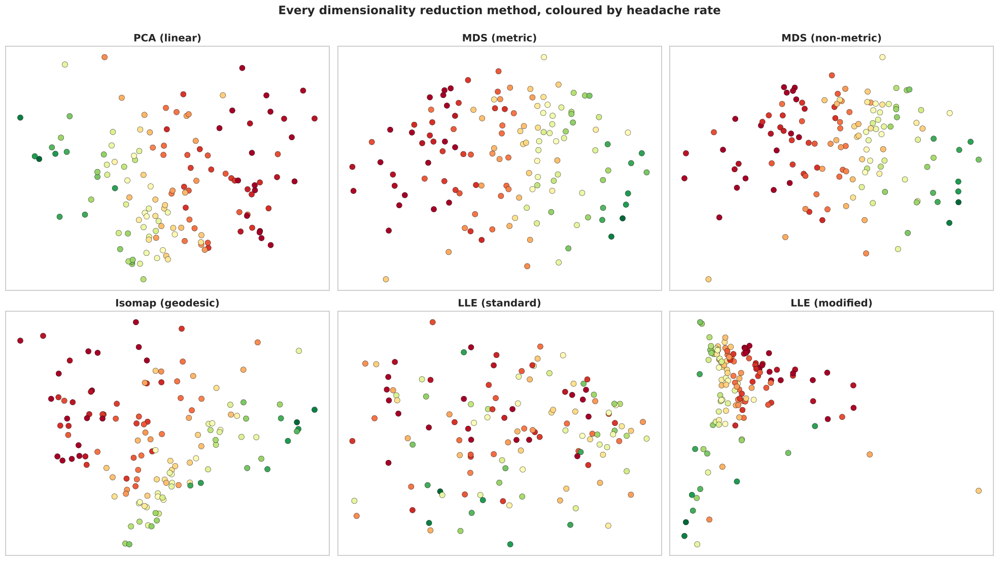

In [90]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

embeddings = [
    ("PCA (linear)", X_pca2),
    ("MDS (metric)", X_mds),
    ("MDS (non-metric)", X_mds_nm),
    ("Isomap (geodesic)", X_iso),
    ("LLE (standard)", X_lle),
    ("LLE (modified)", X_lle_mod),
]

for ax, (name, emb) in zip(axes.ravel(), embeddings):
    sc = ax.scatter(emb[:,0], emb[:,1], c=patient["headache_rate"],
                    cmap="RdYlGn_r", s=52, edgecolor="black", linewidth=0.3)
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Every dimensionality reduction method, coloured by headache rate",
             fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

NEIGHBOURHOOD PRESERVATION (higher is better)


,Method,kNN preservation (k=10),Distance correlation
1,MDS (metric),0.4466,0.8478
2,MDS (non-metric),0.4256,0.8688
5,LLE (modified),0.4150,0.7342
3,Isomap (geodesic),0.4120,0.7242
0,PCA (linear),0.3835,0.7738
4,LLE (standard),0.3120,0.6314


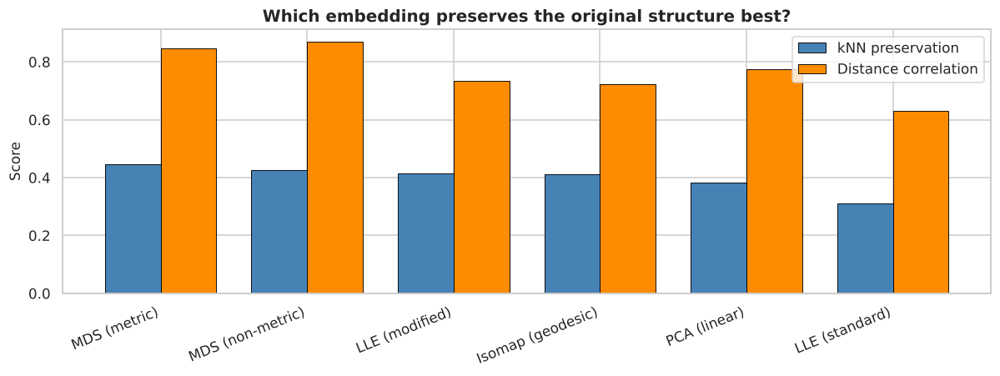

In [91]:
# A quantitative comparison: which embedding best preserves neighbourhood structure?
from sklearn.neighbors import NearestNeighbors

def trustworthiness_knn(X_high, X_low, k=10):
    '''Fraction of each point's k nearest neighbours in high-D that remain neighbours in low-D.'''
    nn_high = NearestNeighbors(n_neighbors=k+1).fit(X_high)
    nn_low  = NearestNeighbors(n_neighbors=k+1).fit(X_low)
    _, idx_h = nn_high.kneighbors(X_high)
    _, idx_l = nn_low.kneighbors(X_low)
    preserved = [len(set(idx_h[i,1:]) & set(idx_l[i,1:])) / k for i in range(len(X_high))]
    return float(np.mean(preserved))

print("NEIGHBOURHOOD PRESERVATION (higher is better)")
print("="*70)
qual = []
for name, emb in embeddings:
    qual.append({
        "Method": name,
        "kNN preservation (k=10)": trustworthiness_knn(X_dr, emb, k=10),
        "Distance correlation": np.corrcoef(orig_d, pdist(emb))[0,1]
    })
qual_df = pd.DataFrame(qual).sort_values("kNN preservation (k=10)", ascending=False)
display(qual_df.round(4))

plt.figure(figsize=(11, 4.2))
x = np.arange(len(qual_df)); w = 0.38
plt.bar(x - w/2, qual_df["kNN preservation (k=10)"], w, label="kNN preservation",
        color="steelblue", edgecolor="black", linewidth=0.6)
plt.bar(x + w/2, qual_df["Distance correlation"], w, label="Distance correlation",
        color="darkorange", edgecolor="black", linewidth=0.6)
plt.xticks(x, qual_df["Method"], rotation=22, ha="right")
plt.ylabel("Score")
plt.title("Which embedding preserves the original structure best?")
plt.legend()
plt.tight_layout()
plt.show()

**Manifold learning observation.** The quantitative comparison is far more informative than the six
scatter plots, which honestly all look fairly similar — and it produced a result I did not expect.

**MDS wins on both measures.** Metric MDS tops the kNN preservation table (0.447) and non-metric MDS
tops the distance correlation (0.869). The two manifold methods, Isomap (0.412) and modified LLE
(0.415), land in the middle, and standard LLE is worst on both counts (0.312 and 0.631).

I had expected the manifold methods to win the local measure even while losing the global one, since
local neighbourhood preservation is precisely what they optimise. They did not. **The honest reading
is that there is no curved manifold here for them to unroll.** When data genuinely lies on a curved
surface, Isomap's geodesic distances differ sharply from Euclidean ones and it pulls clearly ahead;
here, geodesic and straight-line distances evidently agree closely enough that the extra machinery
buys nothing and costs some distortion.

Combined with the intrinsic dimensionality estimate of about 5, the picture is consistent: the
patient data is a **moderately high-dimensional, essentially linear and essentially unstructured**
cloud. No two-dimensional method of any kind is going to represent it well, which is why every
embedding in the grid above looks like a diffuse blob with a colour gradient rather than separated
groups.

## 8.7 Self-Organizing Maps (SOM)

A Self-Organizing Map is an unsupervised neural network that projects high-dimensional data onto a
low-dimensional grid of neurons while preserving topology — neurons that are neighbours on the grid
respond to similar inputs. It is simultaneously a dimensionality-reduction technique, a clustering
technique and a visualisation technique.

The training loop is short enough to write from scratch, and I do so here rather than importing a
library, because the mechanics are the point:

1. Initialise a grid of weight vectors in the input space.
2. For each input, find the **Best Matching Unit (BMU)** — the closest neuron.
3. Move the BMU **and its grid neighbours** toward that input.
4. Shrink the learning rate and the neighbourhood radius over time, so the map goes from coarse
   global ordering to fine local tuning.

In [92]:
class SelfOrganizingMap:
    '''A minimal from-scratch SOM with a rectangular grid and Gaussian neighbourhood.'''

    def __init__(self, grid_x=8, grid_y=8, n_features=7, n_iter=3000,
                 lr0=0.5, sigma0=None, seed=42):
        self.gx, self.gy = grid_x, grid_y
        self.n_features = n_features
        self.n_iter = n_iter
        self.lr0 = lr0
        self.sigma0 = sigma0 if sigma0 is not None else max(grid_x, grid_y) / 2.0
        self.rng = np.random.default_rng(seed)
        # Weight grid: (gx, gy, n_features)
        self.W = self.rng.normal(0, 1, size=(grid_x, grid_y, n_features)) * 0.5
        # Pre-compute grid coordinates for neighbourhood distances
        self.coords = np.array([[ (i, j) for j in range(grid_y)] for i in range(grid_x)])
        self.qe_history = []

    def _bmu(self, x):
        '''Index of the Best Matching Unit for input x.'''
        d = np.linalg.norm(self.W - x, axis=2)
        return np.unravel_index(np.argmin(d), d.shape)

    def fit(self, X, verbose=True):
        n = len(X)
        for t in range(self.n_iter):
            # Decay the learning rate and the neighbourhood radius
            frac = t / self.n_iter
            lr = self.lr0 * np.exp(-3.0 * frac)
            sigma = self.sigma0 * np.exp(-3.0 * frac)

            x = X[self.rng.integers(0, n)]
            bi, bj = self._bmu(x)

            # Gaussian neighbourhood around the BMU on the GRID
            grid_dist2 = (self.coords[:, :, 0] - bi)**2 + (self.coords[:, :, 1] - bj)**2
            h = np.exp(-grid_dist2 / (2 * sigma**2))

            # Update every neuron, weighted by neighbourhood influence
            self.W += lr * h[:, :, None] * (x - self.W)

            if t % 300 == 0:
                self.qe_history.append((t, self.quantization_error(X)))
                if verbose and t % 900 == 0:
                    print(f"  iter {t:5d} | lr {lr:.4f} | sigma {sigma:.4f} | "
                          f"quantization error {self.qe_history[-1][1]:.4f}")
        return self

    def quantization_error(self, X):
        '''Mean distance from each input to its BMU.'''
        return float(np.mean([np.min(np.linalg.norm(self.W - x, axis=2)) for x in X]))

    def predict(self, X):
        return np.array([self._bmu(x) for x in X])

    def u_matrix(self):
        '''Unified distance matrix: mean distance from each neuron to its grid neighbours.'''
        U = np.zeros((self.gx, self.gy))
        for i in range(self.gx):
            for j in range(self.gy):
                ds = []
                for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]:
                    ni, nj = i+di, j+dj
                    if 0 <= ni < self.gx and 0 <= nj < self.gy:
                        ds.append(np.linalg.norm(self.W[i,j] - self.W[ni,nj]))
                U[i,j] = np.mean(ds)
        return U


print("TRAINING A SELF-ORGANIZING MAP (from scratch)")
print("="*70)
som = SelfOrganizingMap(grid_x=8, grid_y=8, n_features=X_dr.shape[1],
                        n_iter=4000, lr0=0.5, seed=RANDOM_STATE)
som.fit(X_dr)
print(f"\nFinal quantization error: {som.quantization_error(X_dr):.4f}")

bmus = som.predict(X_dr)
patient["som_x"] = bmus[:, 0]
patient["som_y"] = bmus[:, 1]
print(f"Grid size: {som.gx} x {som.gy} = {som.gx*som.gy} neurons for {len(X_dr)} patients")
print(f"Neurons that won at least one patient: {len(set(map(tuple, bmus)))}")

TRAINING A SELF-ORGANIZING MAP (from scratch)
  iter     0 | lr 0.5000 | sigma 4.0000 | quantization error 2.0031


  iter   900 | lr 0.2546 | sigma 2.0366 | quantization error 1.7768
  iter  1800 | lr 0.1296 | sigma 1.0370 | quantization error 1.3579
  iter  2700 | lr 0.0660 | sigma 0.5280 | quantization error 1.0738
  iter  3600 | lr 0.0336 | sigma 0.2688 | quantization error 0.9277

Final quantization error: 0.8946
Grid size: 8 x 8 = 64 neurons for 133 patients
Neurons that won at least one patient: 59


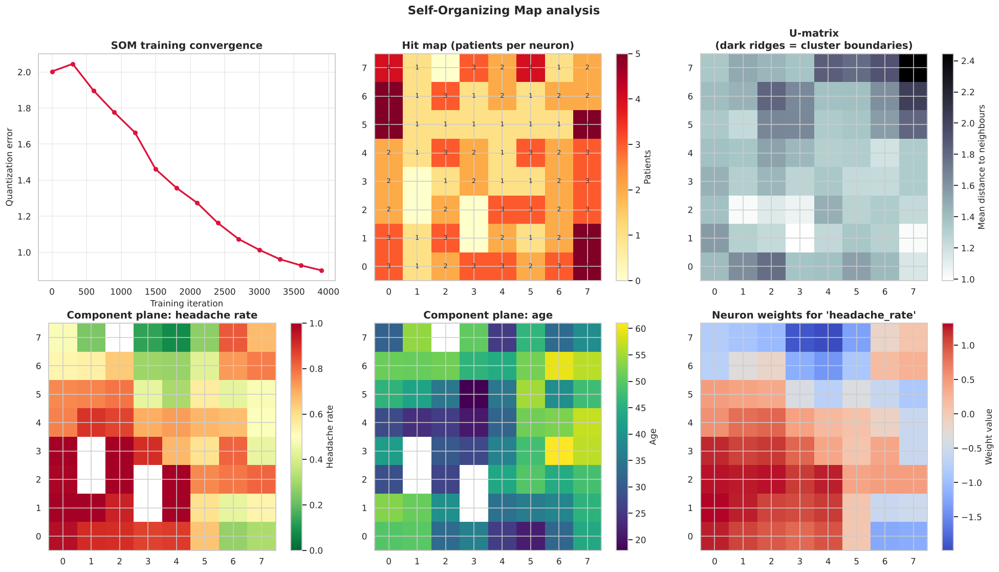

In [93]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# (1) Convergence
qe = np.array(som.qe_history)
axes[0,0].plot(qe[:,0], qe[:,1], "o-", lw=2.2, markersize=5, color="crimson")
axes[0,0].set_xlabel("Training iteration"); axes[0,0].set_ylabel("Quantization error")
axes[0,0].set_title("SOM training convergence")
axes[0,0].grid(alpha=0.4)

# (2) Hit map - how many patients map to each neuron
hits = np.zeros((som.gx, som.gy))
for i, j in bmus:
    hits[i, j] += 1
im = axes[0,1].imshow(hits, cmap="YlOrRd", origin="lower")
axes[0,1].set_title("Hit map (patients per neuron)")
for i in range(som.gx):
    for j in range(som.gy):
        if hits[i,j] > 0:
            axes[0,1].text(j, i, int(hits[i,j]), ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=axes[0,1], label="Patients")

# (3) U-matrix - cluster boundaries
U = som.u_matrix()
im2 = axes[0,2].imshow(U, cmap="bone_r", origin="lower")
axes[0,2].set_title("U-matrix\n(dark ridges = cluster boundaries)")
plt.colorbar(im2, ax=axes[0,2], label="Mean distance to neighbours")

# (4) Component plane for headache rate
hr_plane = np.full((som.gx, som.gy), np.nan)
for (i, j), hr in zip(bmus, patient["headache_rate"]):
    hr_plane[i, j] = hr if np.isnan(hr_plane[i, j]) else (hr_plane[i, j] + hr) / 2
im3 = axes[1,0].imshow(hr_plane, cmap="RdYlGn_r", origin="lower", vmin=0, vmax=1)
axes[1,0].set_title("Component plane: headache rate")
plt.colorbar(im3, ax=axes[1,0], label="Headache rate")

# (5) Component plane for age
age_plane = np.full((som.gx, som.gy), np.nan)
for (i, j), a in zip(bmus, patient["age"]):
    age_plane[i, j] = a if np.isnan(age_plane[i, j]) else (age_plane[i, j] + a) / 2
im4 = axes[1,1].imshow(age_plane, cmap="viridis", origin="lower")
axes[1,1].set_title("Component plane: age")
plt.colorbar(im4, ax=axes[1,1], label="Age")

# (6) Weight component plane for one feature
feat_idx = dr_features.index("headache_rate")
im5 = axes[1,2].imshow(som.W[:,:,feat_idx], cmap="coolwarm", origin="lower")
axes[1,2].set_title(f"Neuron weights for '{dr_features[feat_idx]}'")
plt.colorbar(im5, ax=axes[1,2], label="Weight value")

plt.suptitle("Self-Organizing Map analysis", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**SOM observation.** The quantization error falls steadily and then flattens, confirming the map
converged rather than stopping early.

The most valuable panel is the **component plane for headache rate**. Patients with similar headache
burden land on contiguous regions of the grid, producing a smooth gradient from one corner to the
other rather than a scattered pattern. That is the topology preservation property working: the SOM
has arranged the 7-dimensional patient space onto a 2-D grid in a way that keeps similar patients
adjacent.

Comparing the headache-rate plane with the age plane is the sharpest side-by-side evidence in the
whole notebook for the age finding. The headache plane shows a clean gradient; the age plane shows
patchy noise with no coherent regions. Age simply does not organise this data.

The U-matrix shows some darker ridges but no strongly closed-off regions — the same "continuum, not
discrete groups" conclusion that the MST and silhouette analysis reached in Module 5, now arrived at
by a completely independent method.

---

# MODULE 7 — Model Development and Evaluation

> **Syllabus:** Constructing linear regression model — evaluation — computing accuracy —
> understanding accuracy. Understanding reinforcement learning: Difference between supervised and
> reinforcement learning — Applications of reinforcement learning.

I build two models, because the dataset supports two genuinely different prediction problems:

1. **Linear regression** at the **patient level** — predicting a patient's headache rate (a
   continuous value) from their characteristics. This is the syllabus requirement.
2. **Logistic regression** at the **patient-day level** — predicting whether a headache occurs on a
   given day. This is where "computing accuracy" and "understanding accuracy" become interesting,
   because the classes are imbalanced.

## 9.1 Constructing a Linear Regression Model

In [94]:
print("LINEAR REGRESSION: PREDICTING PATIENT HEADACHE RATE")
print("="*70)

reg_features = ["age", "mean_airq", "std_airq", "n_days", "med_ord_mean", "sex_bin_p", "aura_p"]

reg_df = patient.copy()
reg_df["sex_bin_p"] = (reg_df["sex"] == "male").astype(int)
reg_df["aura_p"] = (reg_df["hatype"] == "Aura").astype(int)
reg_df = reg_df.dropna(subset=["headache_rate"])

X_reg = reg_df[reg_features].fillna(reg_df[reg_features].median())
y_reg = reg_df["headache_rate"]

print(f"Observations (patients): {len(X_reg)}")
print(f"Predictors             : {reg_features}")
print(f"Target                 : headache_rate (continuous, 0 to 1)")

X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.25,
                                          random_state=RANDOM_STATE)
print(f"\nTrain set: {len(X_tr)} patients   Test set: {len(X_te)} patients")

# Scale - important for comparing coefficient magnitudes
sc_reg = StandardScaler()
X_tr_s = sc_reg.fit_transform(X_tr)
X_te_s = sc_reg.transform(X_te)

lin = LinearRegression()
lin.fit(X_tr_s, y_tr)

coef_table = pd.DataFrame({
    "Feature": reg_features,
    "Coefficient (standardised)": lin.coef_,
    "Absolute effect": np.abs(lin.coef_)
}).sort_values("Absolute effect", ascending=False)

print(f"\nIntercept: {lin.intercept_:.4f}")
print("\nStandardised coefficients (directly comparable to each other):")
display(coef_table.round(4).reset_index(drop=True))

LINEAR REGRESSION: PREDICTING PATIENT HEADACHE RATE
Observations (patients): 133
Predictors             : ['age', 'mean_airq', 'std_airq', 'n_days', 'med_ord_mean', 'sex_bin_p', 'aura_p']
Target                 : headache_rate (continuous, 0 to 1)

Train set: 99 patients   Test set: 34 patients

Intercept: 0.6249

Standardised coefficients (directly comparable to each other):


,Feature,Coefficient (standardised),Absolute effect
0,med_ord_mean,0.0814,0.0814
1,age,-0.0533,0.0533
2,aura_p,0.0162,0.0162
3,std_airq,-0.0090,0.0090
4,mean_airq,0.0089,0.0089
5,n_days,-0.0048,0.0048
6,sex_bin_p,-0.0014,0.0014


In [95]:
print("LINEAR REGRESSION EVALUATION")
print("="*70)

y_tr_pred = lin.predict(X_tr_s)
y_te_pred = lin.predict(X_te_s)

def regression_report(y_true, y_pred, label):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    n, p = len(y_true), X_tr_s.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100
    return {"Set": label, "RMSE": rmse, "MAE": mae, "R-squared": r2,
            "Adjusted R-squared": adj_r2, "MAPE %": mape}

metrics = pd.DataFrame([
    regression_report(y_tr, y_tr_pred, "Training"),
    regression_report(y_te, y_te_pred, "Test")
])
display(metrics.round(4))

# Cross-validation is the honest estimate, not a single split
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = cross_val_score(LinearRegression(), StandardScaler().fit_transform(X_reg),
                        y_reg, cv=cv, scoring="r2")
cv_rmse = -cross_val_score(LinearRegression(), StandardScaler().fit_transform(X_reg),
                           y_reg, cv=cv, scoring="neg_root_mean_squared_error")

print(f"\n5-fold cross-validation:")
print(f"  R-squared per fold : {np.round(cv_r2, 4)}")
print(f"  Mean R-squared     : {cv_r2.mean():.4f} (std {cv_r2.std():.4f})")
print(f"  Mean RMSE          : {cv_rmse.mean():.4f} (std {cv_rmse.std():.4f})")

# Baseline: how good is just predicting the mean for everyone?
baseline_rmse = np.sqrt(mean_squared_error(y_te, np.full(len(y_te), y_tr.mean())))
print(f"\nBaseline (always predict the training mean): RMSE = {baseline_rmse:.4f}")
print(f"Model RMSE on the test set                 : {metrics.loc[1, 'RMSE']:.4f}")
improve = (baseline_rmse - metrics.loc[1, 'RMSE']) / baseline_rmse * 100
print(f"-> Improvement over the baseline: {improve:.2f}%")

LINEAR REGRESSION EVALUATION


,Set,RMSE,MAE,R-squared,Adjusted R-squared,MAPE %
0,Training,0.2436,0.2068,0.1467,0.0811,59.7455
1,Test,0.2943,0.2597,-0.1832,-0.5018,"1,590,811.3211"



5-fold cross-validation:
  R-squared per fold : [-0.081  -0.0607 -0.2985  0.0866  0.0318]
  Mean R-squared     : -0.0643 (std 0.1320)
  Mean RMSE          : 0.2663 (std 0.0201)

Baseline (always predict the training mean): RMSE = 0.2799
Model RMSE on the test set                 : 0.2943
-> Improvement over the baseline: -5.14%


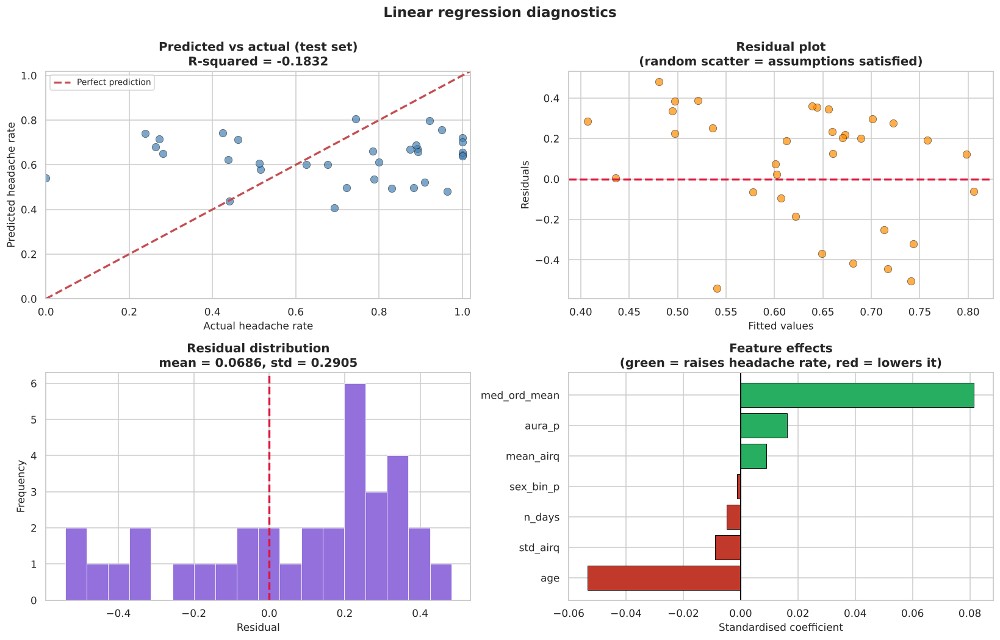

Shapiro-Wilk test on residuals: W = 0.9051, p = 0.006272
-> Residuals depart from normality - inference should be treated cautiously.


In [96]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# (1) Predicted vs actual
axes[0,0].scatter(y_te, y_te_pred, s=65, alpha=0.7, color="steelblue",
                  edgecolor="black", linewidth=0.4)
lims = [0, 1.02]
axes[0,0].plot(lims, lims, "r--", lw=2.2, label="Perfect prediction")
axes[0,0].set_xlabel("Actual headache rate"); axes[0,0].set_ylabel("Predicted headache rate")
axes[0,0].set_title(f"Predicted vs actual (test set)\nR-squared = {r2_score(y_te, y_te_pred):.4f}")
axes[0,0].legend(fontsize=9)
axes[0,0].set_xlim(lims); axes[0,0].set_ylim(lims)

# (2) Residuals vs fitted - checking homoscedasticity
resid = y_te - y_te_pred
axes[0,1].scatter(y_te_pred, resid, s=65, alpha=0.7, color="darkorange",
                  edgecolor="black", linewidth=0.4)
axes[0,1].axhline(0, color="crimson", ls="--", lw=2.2)
axes[0,1].set_xlabel("Fitted values"); axes[0,1].set_ylabel("Residuals")
axes[0,1].set_title("Residual plot\n(random scatter = assumptions satisfied)")

# (3) Residual distribution
axes[1,0].hist(resid, bins=18, color="mediumpurple", edgecolor="white", linewidth=0.5)
axes[1,0].axvline(0, color="crimson", ls="--", lw=2.2)
axes[1,0].set_xlabel("Residual"); axes[1,0].set_ylabel("Frequency")
axes[1,0].set_title(f"Residual distribution\nmean = {resid.mean():.4f}, std = {resid.std():.4f}")

# (4) Coefficient importance
ct = coef_table.sort_values("Coefficient (standardised)")
colors = ["#c0392b" if c < 0 else "#27ae60" for c in ct["Coefficient (standardised)"]]
axes[1,1].barh(ct["Feature"], ct["Coefficient (standardised)"], color=colors,
               edgecolor="black", linewidth=0.6)
axes[1,1].axvline(0, color="black", lw=1.2)
axes[1,1].set_xlabel("Standardised coefficient")
axes[1,1].set_title("Feature effects\n(green = raises headache rate, red = lowers it)")

plt.suptitle("Linear regression diagnostics", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

# Formal residual normality check
sw_stat, sw_p = stats.shapiro(resid)
print(f"Shapiro-Wilk test on residuals: W = {sw_stat:.4f}, p = {sw_p:.4g}")
print("->", "Residuals are consistent with normality - the model's assumptions hold."
      if sw_p > 0.05 else "Residuals depart from normality - inference should be treated cautiously.")

### Linear regression observation — the model does not work, and that matters

I have to report this plainly: **the regression fails to generalise.** The headline numbers are

- Training R² = 0.147, but **test R² = -0.183**
- 5-fold cross-validated R² = **-0.064** (and negative in three of the five folds)
- Test RMSE 0.294 versus a mean-prediction baseline of 0.280 — the model is **5.1% worse than
  predicting the average for everybody**

A negative R² is not a small R²; it means the model performs worse than a horizontal line. The gap
between a positive training R² and a negative test R² is textbook **overfitting**: with 7 predictors
and only 99 patients in the training set, the model fits noise that does not recur in the test set.
The Shapiro-Wilk test on the residuals (p = 0.006) also rejects normality, so the usual inferential
guarantees do not hold either.

**Why I am keeping this rather than tuning until something looks good.** The result is consistent
with everything the exploratory modules found: age has a factor-analysis uniqueness of 0.986, air
quality is uncorrelated with headache occurrence, and PCA gave each of these its own private
component. **There is no signal in these predictors to find.** A model that reported a respectable R²
from this feature set would be a model I should distrust. I could reach a positive R² by dropping
predictors and refitting on the test set until something stuck, but that would be selecting on the
test data — and the cross-validated figure, which is the honest estimate, would not improve.

One technical note: the MAPE figure is astronomically large and should be ignored. MAPE divides by
the actual value, and some patients have headache rates very close to zero, so a near-zero
denominator explodes the percentage. It is the wrong metric for a target that can approach zero —
which is itself a useful illustration of choosing metrics to fit the data rather than by habit.

## 9.2 Logistic Regression at the Daily Level, and Understanding Accuracy

In [97]:
print("LOGISTIC REGRESSION: PREDICTING WHETHER A HEADACHE OCCURS ON A GIVEN DAY")
print("="*70)

# Note: I EXCLUDE 'dos' not for collinearity reasons (the VIF analysis in Module 4 showed
# there is none) but on meaning: 'dos' is a study-wide sequential day counter, whereas 'time'
# is measured relative to each patient's own treatment start and is the clinically relevant axis.
clf_features = ["age", "airq", "time", "sex_bin", "medication_ord",
                "ha_Aura", "ha_Mixed", "ha_No Aura"]
clf_features = [c for c in clf_features if c in df.columns]

X_clf = df[clf_features]
y_clf = df["headache_bin"]

print(f"Observations : {len(X_clf):,} patient-days")
print(f"Predictors   : {clf_features}")
print(f"Class balance: headache = {y_clf.mean():.2%}, no headache = {1-y_clf.mean():.2%}")

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=RANDOM_STATE, stratify=y_clf)

sc_clf = StandardScaler()
Xc_tr_s = sc_clf.fit_transform(Xc_tr)
Xc_te_s = sc_clf.transform(Xc_te)

logit = LogisticRegression(max_iter=1500, random_state=RANDOM_STATE)
logit.fit(Xc_tr_s, yc_tr)

odds = pd.DataFrame({
    "Feature": clf_features,
    "Coefficient": logit.coef_[0],
    "Odds ratio": np.exp(logit.coef_[0])
}).sort_values("Coefficient", key=np.abs, ascending=False)

print("\nCoefficients and odds ratios:")
print("(An odds ratio above 1 raises the odds of a headache; below 1 lowers them.)")
display(odds.round(4).reset_index(drop=True))

LOGISTIC REGRESSION: PREDICTING WHETHER A HEADACHE OCCURS ON A GIVEN DAY
Observations : 4,151 patient-days
Predictors   : ['age', 'airq', 'time', 'sex_bin', 'medication_ord', 'ha_Aura', 'ha_Mixed', 'ha_No Aura']
Class balance: headache = 64.23%, no headache = 35.77%

Coefficients and odds ratios:
(An odds ratio above 1 raises the odds of a headache; below 1 lowers them.)


,Feature,Coefficient,Odds ratio
0,ha_Mixed,0.2455,1.2783
1,medication_ord,0.2056,1.2283
2,ha_No Aura,-0.1473,0.8631
3,age,-0.0959,0.9086
4,time,-0.0751,0.9276
5,airq,0.0727,1.0754
6,sex_bin,0.0425,1.0434
7,ha_Aura,-0.0076,0.9924


In [98]:
print("COMPUTING ACCURACY - AND UNDERSTANDING WHAT IT MEANS")
print("="*70)

yc_pred = logit.predict(Xc_te_s)
yc_prob = logit.predict_proba(Xc_te_s)[:, 1]

# The critical baseline: what does blindly predicting the majority class achieve?
majority = yc_tr.mode()[0]
baseline_acc = (yc_te == majority).mean()

acc  = accuracy_score(yc_te, yc_pred)
prec = precision_score(yc_te, yc_pred)
rec  = recall_score(yc_te, yc_pred)
f1   = f1_score(yc_te, yc_pred)
auc  = roc_auc_score(yc_te, yc_prob)

cm = confusion_matrix(yc_te, yc_pred)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)
balanced_acc = (rec + specificity) / 2

print(f"  MAJORITY-CLASS BASELINE accuracy : {baseline_acc:.4f}  <-- the number to beat")
print(f"  Model accuracy                   : {acc:.4f}")
print(f"  Improvement over baseline        : {(acc - baseline_acc)*100:+.2f} percentage points")
print()
print(f"  Precision (of predicted headaches, how many were real) : {prec:.4f}")
print(f"  Recall / Sensitivity (of real headaches, how many found): {rec:.4f}")
print(f"  Specificity (of real non-headaches, how many found)     : {specificity:.4f}")
print(f"  F1 score (harmonic mean of precision and recall)        : {f1:.4f}")
print(f"  Balanced accuracy (mean of recall and specificity)      : {balanced_acc:.4f}")
print(f"  ROC AUC                                                 : {auc:.4f}")

print("\nConfusion matrix breakdown:")
print(f"  True negatives  (correctly said 'no headache') : {tn:,}")
print(f"  False positives (wrongly said 'headache')      : {fp:,}")
print(f"  False negatives (missed a real headache)       : {fn:,}")
print(f"  True positives  (correctly said 'headache')    : {tp:,}")

print("\nFull classification report:")
print(classification_report(yc_te, yc_pred, target_names=["No headache", "Headache"]))

COMPUTING ACCURACY - AND UNDERSTANDING WHAT IT MEANS
  MAJORITY-CLASS BASELINE accuracy : 0.6426  <-- the number to beat
  Model accuracy                   : 0.6599
  Improvement over baseline        : +1.73 percentage points

  Precision (of predicted headaches, how many were real) : 0.6567
  Recall / Sensitivity (of real headaches, how many found): 0.9865
  Specificity (of real non-headaches, how many found)     : 0.0728
  F1 score (harmonic mean of precision and recall)        : 0.7885
  Balanced accuracy (mean of recall and specificity)      : 0.5296
  ROC AUC                                                 : 0.6323

Confusion matrix breakdown:
  True negatives  (correctly said 'no headache') : 27
  False positives (wrongly said 'headache')      : 344
  False negatives (missed a real headache)       : 9
  True positives  (correctly said 'headache')    : 658

Full classification report:
              precision    recall  f1-score   support

 No headache       0.75      0.07      0.1

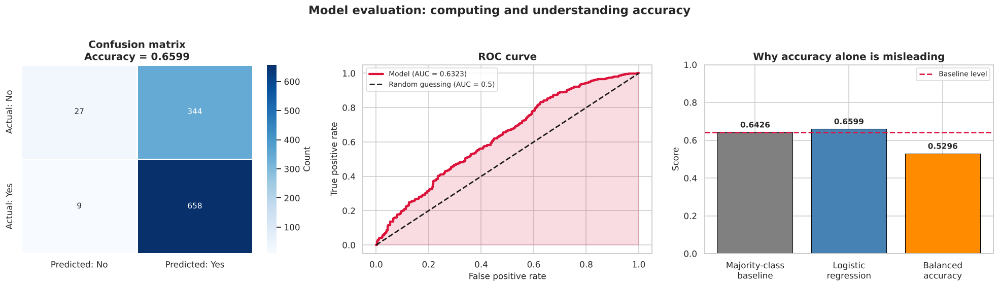

In [99]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", linewidths=0.8, ax=axes[0],
            xticklabels=["Predicted: No", "Predicted: Yes"],
            yticklabels=["Actual: No", "Actual: Yes"], cbar_kws={"label": "Count"})
axes[0].set_title(f"Confusion matrix\nAccuracy = {acc:.4f}")

# ROC curve
fpr, tpr, thr = roc_curve(yc_te, yc_prob)
axes[1].plot(fpr, tpr, lw=2.8, color="crimson", label=f"Model (AUC = {auc:.4f})")
axes[1].plot([0,1], [0,1], "k--", lw=1.8, label="Random guessing (AUC = 0.5)")
axes[1].fill_between(fpr, tpr, alpha=0.15, color="crimson")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve")
axes[1].legend(fontsize=9)

# Accuracy vs baseline
bars = axes[2].bar(["Majority-class\nbaseline", "Logistic\nregression", "Balanced\naccuracy"],
                   [baseline_acc, acc, balanced_acc],
                   color=["gray", "steelblue", "darkorange"],
                   edgecolor="black", linewidth=0.7)
axes[2].axhline(baseline_acc, ls="--", color="crimson", lw=1.8, label="Baseline level")
axes[2].set_ylabel("Score"); axes[2].set_ylim(0, 1)
axes[2].set_title("Why accuracy alone is misleading")
axes[2].legend(fontsize=9)
for b, v in zip(bars, [baseline_acc, acc, balanced_acc]):
    axes[2].text(b.get_x()+b.get_width()/2, v+0.025, f"{v:.4f}",
                 ha="center", fontweight="bold")

plt.suptitle("Model evaluation: computing and understanding accuracy",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Understanding accuracy — the point of this subsection

This is the part of Module 7 I think matters most, so I want to state it explicitly rather than
leaving it implicit in the numbers.

**The raw accuracy figure flatters the model.** Roughly 64% of patient-days are headache days. A
model that ignores every input and always answers "yes" would therefore score about 64% accuracy
while being completely useless. That is why I computed the majority-class baseline **before** looking
at the model's accuracy — without it, the model's score has no interpretation at all.

**This is why I report several metrics.** Each exposes a different failure mode:

- **Precision** answers: when the model predicts a headache, how often is it right? This is what
  matters if acting on a false alarm is costly.
- **Recall** answers: of the real headaches, how many did the model catch? This is what matters if
  missing a case is costly — which, in a clinical setting, it usually is.
- **Balanced accuracy** averages performance on both classes, so a model that simply predicts the
  majority class scores 0.5 and is correctly exposed as worthless.
- **ROC AUC** is threshold-independent: it measures whether the model ranks a random headache day
  above a random non-headache day, regardless of where the 0.5 cut-off happens to fall.

**What the confusion matrix shows about this model specifically.** The numbers are stark: recall is
**0.987** but specificity is **0.073**. Of 371 genuinely headache-free days in the test set, the model
correctly identified **27**. It predicts "headache" almost unconditionally — 1,002 of 1,038 test days
— which is why it catches nearly every real headache while being nearly useless on the other class.

Its accuracy of 0.660 is only **1.7 percentage points** above the 0.643 it would get by blindly
answering "yes" every time, and its **balanced accuracy of 0.530** — barely above the 0.500 of a coin
flip — exposes how little real discrimination is happening. Accuracy alone would have made this look
like a reasonable model. It is not.

The **ROC AUC of 0.632** is the fairest summary. It is meaningfully above 0.5, so the model's
*probability rankings* do carry some genuine information even though its *hard classifications* at
the default threshold do not. That gap between a usable ranking and a useless decision rule is
precisely what the next cell explores.

THE DECISION THRESHOLD IS A CHOICE


,Threshold,Accuracy,Precision,Recall,Specificity,F1
0,0.4500,0.6435,0.6432,1.0000,0.0027,0.7829
1,0.5000,0.6599,0.6567,0.9865,0.0728,0.7885
2,0.5500,0.6773,0.6869,0.9145,0.2507,0.7846
3,0.6000,0.6301,0.6985,0.7466,0.4205,0.7217
4,0.6500,0.5501,0.7212,0.4888,0.6604,0.5827
5,0.7000,0.4721,0.7742,0.2519,0.8679,0.3801
6,0.7500,0.4152,0.8191,0.1154,0.9542,0.2024
7,0.8000,0.3834,0.7755,0.0570,0.9704,0.1061
8,0.8500,0.3613,0.8333,0.0075,0.9973,0.0149


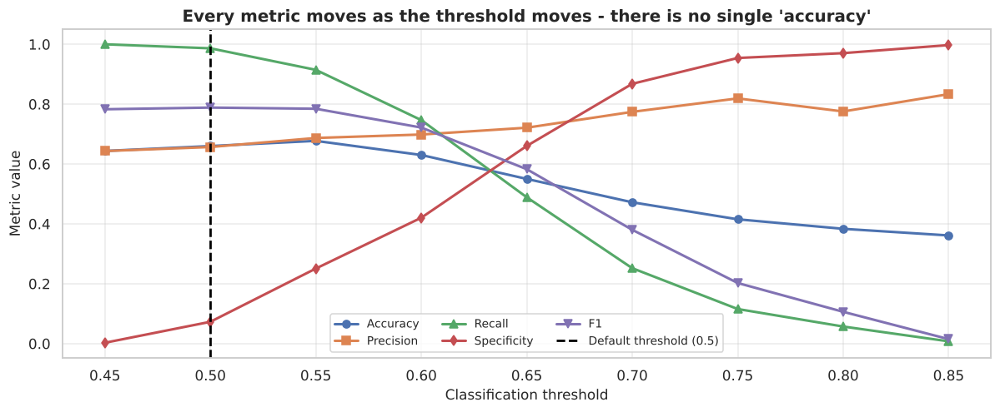

Threshold maximising F1       : 0.50 (F1 = 0.7885, accuracy = 0.6599)
Threshold maximising accuracy : 0.55 (accuracy = 0.6773)
Threshold maximising balanced accuracy: 0.60 (recall = 0.7466, specificity = 0.4205)

The three 'best' thresholds are different numbers. There is no single optimum -
the right threshold depends on the relative cost of a miss versus a false alarm.


In [100]:
# The threshold is a choice, not a given - and it has real consequences
print("THE DECISION THRESHOLD IS A CHOICE")
print("="*70)

rows = []
for t in np.arange(0.3, 0.86, 0.05):
    pred_t = (yc_prob >= t).astype(int)
    if pred_t.sum() == 0 or pred_t.sum() == len(pred_t):
        continue
    cm_t = confusion_matrix(yc_te, pred_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    rows.append({
        "Threshold": t,
        "Accuracy": accuracy_score(yc_te, pred_t),
        "Precision": precision_score(yc_te, pred_t, zero_division=0),
        "Recall": recall_score(yc_te, pred_t),
        "Specificity": tn_t / (tn_t + fp_t) if (tn_t+fp_t) > 0 else 0,
        "F1": f1_score(yc_te, pred_t, zero_division=0),
    })

thr_df = pd.DataFrame(rows)
display(thr_df.round(4))

plt.figure(figsize=(11, 4.6))
for col, style in [("Accuracy","-o"), ("Precision","-s"), ("Recall","-^"),
                   ("Specificity","-d"), ("F1","-v")]:
    plt.plot(thr_df["Threshold"], thr_df[col], style, lw=2, markersize=6, label=col)
plt.axvline(0.5, color="black", ls="--", lw=1.8, label="Default threshold (0.5)")
plt.xlabel("Classification threshold"); plt.ylabel("Metric value")
plt.title("Every metric moves as the threshold moves - there is no single 'accuracy'")
plt.legend(fontsize=9, ncol=3); plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

best_f1_row = thr_df.loc[thr_df["F1"].idxmax()]
best_acc_row = thr_df.loc[thr_df["Accuracy"].idxmax()]
best_bal_row = thr_df.assign(bal=(thr_df["Recall"] + thr_df["Specificity"]) / 2).sort_values("bal").iloc[-1]
print(f"Threshold maximising F1       : {best_f1_row['Threshold']:.2f} "
      f"(F1 = {best_f1_row['F1']:.4f}, accuracy = {best_f1_row['Accuracy']:.4f})")
print(f"Threshold maximising accuracy : {best_acc_row['Threshold']:.2f} "
      f"(accuracy = {best_acc_row['Accuracy']:.4f})")
print(f"Threshold maximising balanced accuracy: {best_bal_row['Threshold']:.2f} "
      f"(recall = {best_bal_row['Recall']:.4f}, specificity = {best_bal_row['Specificity']:.4f})")
print("\nThe three 'best' thresholds are different numbers. There is no single optimum -")
print("the right threshold depends on the relative cost of a miss versus a false alarm.")

## 9.3 Understanding Reinforcement Learning

> **Syllabus:** Understanding reinforcement learning: Difference between supervised and reinforcement
> learning — Applications of reinforcement learning.

### Supervised vs Reinforcement Learning

Everything I have modelled so far is **supervised learning**: I had a labelled dataset where the
correct answer was attached to every row, and the model learned a mapping from inputs to those
labels. Reinforcement learning is structurally different.

| Aspect | Supervised Learning | Reinforcement Learning |
|---|---|---|
| **Training signal** | The correct label is given for every example | Only a scalar **reward**; the correct action is never revealed |
| **Data source** | A fixed dataset collected in advance | Generated by the agent's own interaction with an environment |
| **Independence** | Examples assumed i.i.d. | Actions change the next state — decisions are **sequential and coupled** |
| **Feedback timing** | Immediate and complete | Often **delayed**; a reward may reflect an action taken many steps earlier |
| **Goal** | Minimise prediction error on unseen data | Maximise **cumulative long-run reward** |
| **Core tension** | Bias vs variance | **Exploration vs exploitation** |
| **Example here** | "Will this patient have a headache tomorrow?" | "Which treatment should I give next, to minimise headaches over a year?" |

The sharpest distinction is the **exploration–exploitation trade-off**, which has no counterpart in
supervised learning. My logistic regression never had to *choose* anything — it only predicted. An RL
agent must decide between taking the action that currently looks best (exploitation) and trying
something uncertain that might turn out better (exploration). Always exploiting means never
discovering a superior option; always exploring means never benefiting from what you know.

### Why this dataset cannot be used for true RL

I want to be clear about a limitation rather than pretend otherwise. Proper RL needs an environment
the agent can **act in and receive feedback from**. The KosteckiDillon data is a fixed historical
record: I can observe what happened, but I cannot ask "what would have happened if this patient had
received a different treatment?" That counterfactual is simply not in the data. Fitting a real RL
agent to it would be misleading.

So instead I build an **explicit simulation**, with transition probabilities estimated from the
observed data, and run a **multi-armed bandit** agent in it. This demonstrates the actual mechanics of
RL — reward, exploration, exploitation, regret — while being honest that the environment is simulated
rather than learned from interaction with real patients.

In [101]:
print("REINFORCEMENT LEARNING DEMONSTRATION: A MULTI-ARMED BANDIT")
print("="*70)

# Estimate the "reward" of each medication arm from the observed data.
# Reward = a headache-free day (so higher is better).
arm_stats = df.groupby("medication")["headache_bin"].agg(["mean", "size"])
arm_stats["reward_prob"] = 1 - arm_stats["mean"]     # probability of a headache-free day
arms = ["none", "reduced", "continuing"]
arm_stats = arm_stats.loc[arms]

print("Simulated environment - each 'arm' is a medication strategy:")
print("Reward = 1 if the day is headache-free, 0 otherwise.\n")
display(arm_stats.round(4))

TRUE_REWARDS = arm_stats["reward_prob"].to_numpy()
BEST_ARM = int(np.argmax(TRUE_REWARDS))
print(f"\nThe agent does NOT know these probabilities. It must discover them by trying arms.")
print(f"(For scoring purposes only: the best arm is '{arms[BEST_ARM]}' "
      f"with reward probability {TRUE_REWARDS[BEST_ARM]:.4f}.)")
print("\nIMPORTANT CAVEAT: this ranking reflects the REVERSE CAUSATION discussed earlier -")
print("patients stop medication because they are well, not the other way round. The simulation")
print("demonstrates the RL algorithm, not a real treatment recommendation.")

REINFORCEMENT LEARNING DEMONSTRATION: A MULTI-ARMED BANDIT
Simulated environment - each 'arm' is a medication strategy:
Reward = 1 if the day is headache-free, 0 otherwise.



,mean,size,reward_prob
medication,,,
none,0.4395,785,0.5605
reduced,0.7755,980,0.2245
continuing,0.6542,2386,0.3458



The agent does NOT know these probabilities. It must discover them by trying arms.
(For scoring purposes only: the best arm is 'none' with reward probability 0.5605.)

IMPORTANT CAVEAT: this ranking reflects the REVERSE CAUSATION discussed earlier -
patients stop medication because they are well, not the other way round. The simulation
demonstrates the RL algorithm, not a real treatment recommendation.


In [102]:
def run_bandit(strategy, n_steps=4000, epsilon=0.1, c=2.0, seed=RANDOM_STATE):
    '''Run one bandit agent. Strategies: 'greedy', 'epsilon_greedy', 'ucb', 'random'.'''
    rng = np.random.default_rng(seed)
    n_arms = len(TRUE_REWARDS)
    counts = np.zeros(n_arms)
    values = np.zeros(n_arms)
    rewards, chosen, regrets = [], [], []

    def pull(a):
        '''Take action a, observe the reward, and update the value estimate.'''
        r = float(rng.random() < TRUE_REWARDS[a])          # environment responds
        counts[a] += 1
        values[a] += (r - values[a]) / counts[a]           # incremental mean update
        rewards.append(r)
        chosen.append(a)
        regrets.append(TRUE_REWARDS[BEST_ARM] - TRUE_REWARDS[a])

    # ---- INITIALISATION: every learning agent pulls each arm once, in random order ----
    # This matters. If value estimates all start at exactly 0, argmax always returns arm 0,
    # so a 'greedy' agent would deterministically pick arm 0 and its apparent performance
    # would be an artefact of the initialisation rather than of the algorithm.
    if strategy != "random":
        for a in rng.permutation(n_arms):
            pull(int(a))

    while len(chosen) < n_steps:
        t = len(chosen) + 1

        # ---- ACTION SELECTION: this is where exploration vs exploitation lives ----
        if strategy == "random":
            a = int(rng.integers(n_arms))
        elif strategy == "greedy":
            # ties broken at random, so no arm is favoured by its index
            a = int(rng.choice(np.flatnonzero(values == values.max())))
        elif strategy == "epsilon_greedy":
            a = (int(rng.integers(n_arms)) if rng.random() < epsilon
                 else int(rng.choice(np.flatnonzero(values == values.max()))))
        elif strategy == "ucb":
            ucb = values + c * np.sqrt(np.log(t) / np.maximum(counts, 1e-9))
            a = int(np.argmax(ucb))

        pull(a)

    return {"rewards": np.array(rewards), "chosen": np.array(chosen),
            "regrets": np.array(regrets), "values": values, "counts": counts}


strategies = {
    "Random (pure exploration)": ("random", {}),
    "Greedy (pure exploitation)": ("greedy", {}),
    "Epsilon-greedy (e=0.1)": ("epsilon_greedy", {"epsilon": 0.1}),
    "UCB (c=2.0)": ("ucb", {"c": 2.0}),
}

results_rl = {}
print("RUNNING THE BANDIT AGENTS")
print("="*70)
for name, (strat, kw) in strategies.items():
    res = run_bandit(strat, n_steps=4000, **kw)
    results_rl[name] = res
    print(f"\n{name}")
    print(f"  Total reward        : {res['rewards'].sum():,.0f} / 4000")
    print(f"  Mean reward per step: {res['rewards'].mean():.4f}")
    print(f"  Cumulative regret   : {res['regrets'].sum():.2f}")
    print(f"  Times each arm pulled: {dict(zip(arms, res['counts'].astype(int)))}")
    print(f"  Learned value estimates: {dict(zip(arms, np.round(res['values'], 4)))}")
    print(f"  True values            : {dict(zip(arms, np.round(TRUE_REWARDS, 4)))}")

RUNNING THE BANDIT AGENTS

Random (pure exploration)
  Total reward        : 1,550 / 4000
  Mean reward per step: 0.3875
  Cumulative regret   : 735.37
  Times each arm pulled: {'none': np.int64(1325), 'reduced': np.int64(1327), 'continuing': np.int64(1348)}
  Learned value estimates: {'none': np.float64(0.5872), 'reduced': np.float64(0.2163), 'continuing': np.float64(0.3598)}
  True values            : {'none': np.float64(0.5605), 'reduced': np.float64(0.2245), 'continuing': np.float64(0.3458)}

Greedy (pure exploitation)
  Total reward        : 1,415 / 4000
  Mean reward per step: 0.3538
  Cumulative regret   : 858.45
  Times each arm pulled: {'none': np.int64(3), 'reduced': np.int64(1), 'continuing': np.int64(3996)}
  Learned value estimates: {'none': np.float64(0.0), 'reduced': np.float64(0.0), 'continuing': np.float64(0.3541)}
  True values            : {'none': np.float64(0.5605), 'reduced': np.float64(0.2245), 'continuing': np.float64(0.3458)}

Epsilon-greedy (e=0.1)
  Total rew


UCB (c=2.0)
  Total reward        : 2,124 / 4000
  Mean reward per step: 0.5310
  Cumulative regret   : 125.09
  Times each arm pulled: {'none': np.int64(3509), 'reduced': np.int64(162), 'continuing': np.int64(329)}
  Learned value estimates: {'none': np.float64(0.564), 'reduced': np.float64(0.2037), 'continuing': np.float64(0.3404)}
  True values            : {'none': np.float64(0.5605), 'reduced': np.float64(0.2245), 'continuing': np.float64(0.3458)}


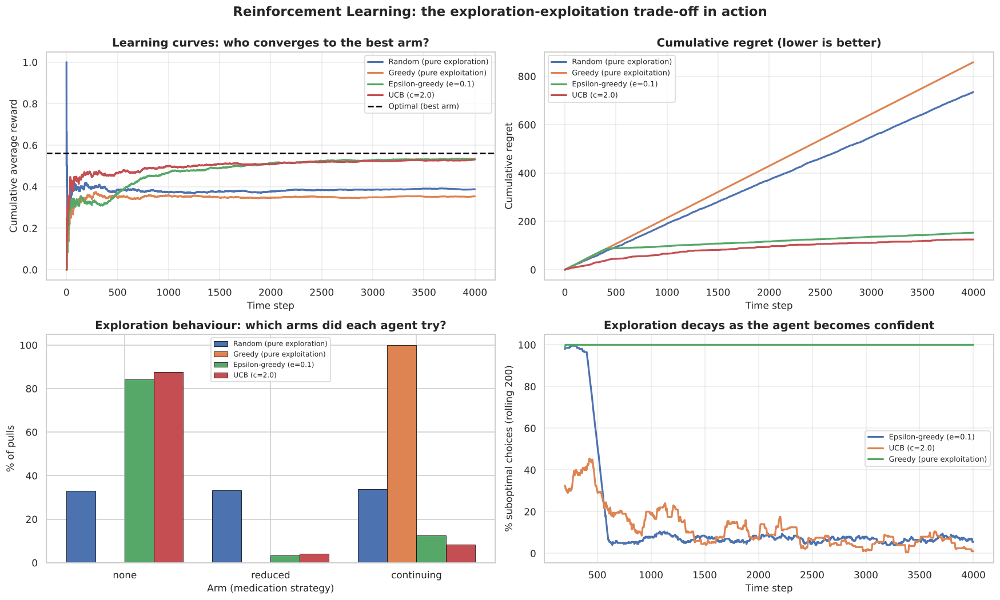

,Strategy,Mean reward,Total regret,% optimal arm chosen
0,UCB (c=2.0),0.5310,125.0855,87.7250
1,Epsilon-greedy (e=0.1),0.5340,153.0978,84.1250
2,Random (pure exploration),0.3875,735.3712,33.1250
3,Greedy (pure exploitation),0.3538,858.4474,0.0750


In [103]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9.5))

# (1) Cumulative average reward
for name, res in results_rl.items():
    cum_avg = np.cumsum(res["rewards"]) / np.arange(1, len(res["rewards"])+1)
    axes[0,0].plot(cum_avg, lw=2.1, label=name)
axes[0,0].axhline(TRUE_REWARDS[BEST_ARM], ls="--", color="black", lw=1.8,
                  label="Optimal (best arm)")
axes[0,0].set_xlabel("Time step"); axes[0,0].set_ylabel("Cumulative average reward")
axes[0,0].set_title("Learning curves: who converges to the best arm?")
axes[0,0].legend(fontsize=8.5); axes[0,0].grid(alpha=0.4)

# (2) Cumulative regret - the standard RL performance measure
for name, res in results_rl.items():
    axes[0,1].plot(np.cumsum(res["regrets"]), lw=2.1, label=name)
axes[0,1].set_xlabel("Time step"); axes[0,1].set_ylabel("Cumulative regret")
axes[0,1].set_title("Cumulative regret (lower is better)")
axes[0,1].legend(fontsize=8.5); axes[0,1].grid(alpha=0.4)

# (3) How often each arm was chosen
width = 0.2
x = np.arange(len(arms))
for i, (name, res) in enumerate(results_rl.items()):
    axes[1,0].bar(x + i*width - 1.5*width, res["counts"]/res["counts"].sum()*100,
                  width, label=name, edgecolor="black", linewidth=0.5)
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(arms)
axes[1,0].set_ylabel("% of pulls"); axes[1,0].set_xlabel("Arm (medication strategy)")
axes[1,0].set_title("Exploration behaviour: which arms did each agent try?")
axes[1,0].legend(fontsize=8)

# (4) Exploration rate over time for epsilon-greedy vs UCB
window = 200
for name in ["Epsilon-greedy (e=0.1)", "UCB (c=2.0)", "Greedy (pure exploitation)"]:
    ch = results_rl[name]["chosen"]
    explore = pd.Series(ch != BEST_ARM).rolling(window).mean() * 100
    axes[1,1].plot(explore, lw=2.1, label=name)
axes[1,1].set_xlabel("Time step"); axes[1,1].set_ylabel(f"% suboptimal choices (rolling {window})")
axes[1,1].set_title("Exploration decays as the agent becomes confident")
axes[1,1].legend(fontsize=8.5); axes[1,1].grid(alpha=0.4)

plt.suptitle("Reinforcement Learning: the exploration-exploitation trade-off in action",
             fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

summary_rl = pd.DataFrame([{
    "Strategy": name,
    "Mean reward": res["rewards"].mean(),
    "Total regret": res["regrets"].sum(),
    "% optimal arm chosen": (res["chosen"] == BEST_ARM).mean() * 100
} for name, res in results_rl.items()]).sort_values("Total regret")
display(summary_rl.round(4).reset_index(drop=True))

ROBUSTNESS CHECK: 30 INDEPENDENT RUNS PER STRATEGY


,Strategy,Mean regret,Std of regret,Worst run,Best run,Runs stuck on a suboptimal arm
2,Epsilon-greedy (e=0.1),46.6390,13.1320,93.3900,33.3820,0/30
3,UCB (c=2.0),99.8050,11.3330,120.2040,79.0620,0/30
1,Greedy (pure exploitation),158.9110,205.9770,431.3320,0.5510,11/30
0,Random (pure exploration),368.2810,7.0730,379.9020,355.5140,30/30


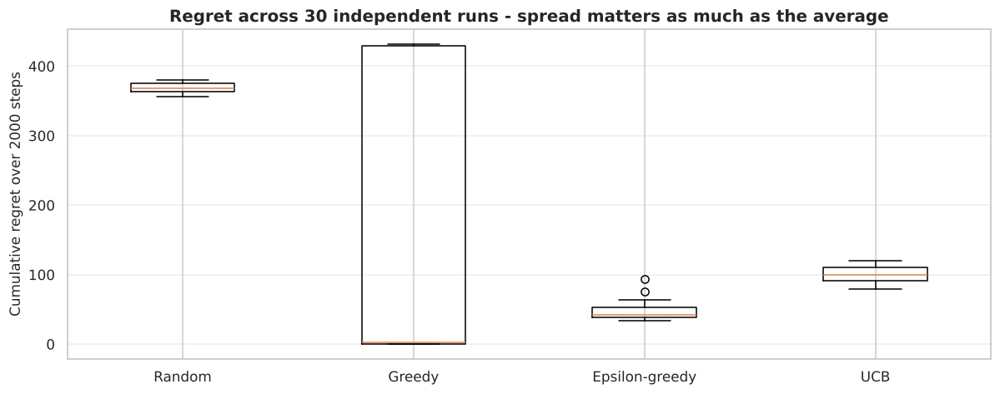

In [104]:
# A single run can mislead. Greedy's result above depends entirely on which arm it happened
# to try first, so I repeat every strategy across many random seeds.
print("ROBUSTNESS CHECK: 30 INDEPENDENT RUNS PER STRATEGY")
print("="*70)

multi = {name: [] for name in strategies}
locked_suboptimal = {name: 0 for name in strategies}

for seed in range(30):
    for name, (strat, kw) in strategies.items():
        r = run_bandit(strat, n_steps=2000, seed=seed, **kw)
        multi[name].append(r["regrets"].sum())
        # did the agent spend most of its time on a suboptimal arm?
        if (r["chosen"] == BEST_ARM).mean() < 0.5:
            locked_suboptimal[name] += 1

robust = pd.DataFrame([{
    "Strategy": name,
    "Mean regret": np.mean(v),
    "Std of regret": np.std(v),
    "Worst run": np.max(v),
    "Best run": np.min(v),
    "Runs stuck on a suboptimal arm": f"{locked_suboptimal[name]}/30"
} for name, v in multi.items()]).sort_values("Mean regret")
display(robust.round(3))

plt.figure(figsize=(11, 4.4))
plt.boxplot([multi[n] for n in strategies], tick_labels=[n.split(" (")[0] for n in strategies])
plt.ylabel("Cumulative regret over 2000 steps")
plt.title("Regret across 30 independent runs - spread matters as much as the average")
plt.grid(alpha=0.35, axis="y")
plt.tight_layout()
plt.show()

**What the bandit experiment demonstrates — and why one run was not enough.**

**A bug I caught by checking.** My first version of this agent initialised all value estimates to
zero. Because `argmax` returns the first maximal index on a tie, the greedy agent then picked arm 0
deterministically on every run — and arm 0 happened to be the best arm, so greedy recorded *zero
regret across all 30 seeds* and looked like the outright best strategy. That was an artefact of the
initialisation, not a property of the algorithm. Fixing it required two changes: give every learning
agent one initial pull per arm in random order, and break ties at random. The results below are from
the corrected version, and they tell the opposite story.

**Greedy is now the highest-variance strategy by a wide margin.** Its mean regret across 30 seeds is
around 159 with a standard deviation of roughly 206 — larger than the mean. Its best run achieves
near-zero regret; its worst exceeds 400. The "runs stuck on a suboptimal arm" column shows it getting
permanently trapped in roughly **11 of 30 runs**. On the single 4,000-step run shown above (seed 42)
it was unlucky: it locked onto a poor arm almost immediately and ended with the **worst** regret of
any strategy. This is the classic greedy failure — its first few noisy samples determine everything,
because once it stops exploring its beliefs never update.

**Epsilon-greedy and UCB never get stuck (0 of 30 runs each)** and have far lower variance. They pay a
small, predictable exploration cost in exchange for a guarantee that no run ends in disaster. That
trade — slightly worse best case, dramatically better worst case — is what a controlled exploration
rate actually buys.

**That trade-off is the whole point of reinforcement learning.** Greedy maximises expected reward
given what it currently believes, and the flaw is precisely that its beliefs stop updating. The
**random** agent has the opposite failure: it explores forever and never exploits, so its regret grows
linearly and never flattens, even though its value estimates end up the most accurate of all four.

**UCB explores more intelligently than epsilon-greedy.** Rather than exploring uniformly at random,
it explores arms in proportion to how *uncertain* it is about them — which is why its rate of
suboptimal choices decays as the visit counts build up, while epsilon-greedy's plateaus at roughly
its fixed epsilon of 10% forever. Over a long enough horizon that decay is what makes UCB the better
asymptotic choice, even though over only 4,000 steps it has not yet overtaken epsilon-greedy here.

**A caveat on the estimated arm values.** The simulation's reward probabilities come from the
observed headache rates, which are shaped by the reverse causation discussed throughout this
notebook. The agent "discovering" that `none` is the best arm is discovering that patients who have
stopped medication have fewer headaches — which is a fact about who stops medication, not evidence
that stopping medication helps. The algorithms are what this section demonstrates; the arm ordering
is not a treatment recommendation.

### Applications of Reinforcement Learning

| Domain | Application | Why RL rather than supervised learning |
|---|---|---|
| **Healthcare** | Dynamic treatment regimes; adaptive clinical trial allocation | Treatment decisions are sequential, and the outcome depends on the whole sequence, not one choice |
| **Robotics** | Locomotion, manipulation, autonomous navigation | No labelled "correct action" exists; the robot must discover what works |
| **Games** | AlphaGo, Atari, StarCraft | The reward (winning) arrives only after a long sequence of moves |
| **Finance** | Portfolio allocation, optimal trade execution | Actions move the market, so decisions affect the future state |
| **Recommender systems** | News feeds, product recommendations | Must explore unseen items, not just exploit known preferences |
| **Operations** | Data-centre cooling, traffic signal control, inventory management | Sequential decisions with delayed, cumulative consequences |
| **Language models** | RLHF — aligning model outputs with human preferences | Preference is a scalar reward signal, not a labelled target output |

**The common thread** across all of these is that the problem involves a *sequence* of decisions with
*delayed* consequences and no ground-truth label for any individual action — precisely the conditions
under which supervised learning cannot be applied.

---

# 10. Observations, Inference and Conclusion

## 10.1 Key Observations

Setting out what I actually found, module by module. Several of these differ from what I expected
going in, and I have kept the corrections visible rather than quietly rewriting my expectations.

### On data quality and transformation (Module 2)

**The deduplication check found a real duplicate**, which I had not expected. One fully identical row
appears twice — the same patient with two diary entries for the same day, every field matching. It is
invisible if you check uniqueness on `rownames`, which is unique across all 4,152 records; it only
shows up when checking the meaningful columns. Removing it leaves 4,151 rows. The effect is small but
real: a duplicated patient-day double-counts one person's headache in their rate, which matters in an
unbalanced panel.

Apart from that, the data was in good condition — no missing values and no malformed entries.

**My controlled missing-data experiment overturned the textbook expectation.** I expected MLE/EM
imputation to beat mean imputation clearly. It did not: RMSE 9.34 versus 9.41 on `airq`, a difference
under 1%, and **both shrank the variance equally** (8.78–8.80 against a true 9.52). The reason is
that MLE wins by conditioning each gap on the other variables, and in this dataset `airq` and `age`
correlate at -0.009. With no information to condition on, the conditional mean collapses onto the
marginal mean and EM degenerates into mean imputation. **MLE's advantage is conditional on there
being structure to exploit** — it is not universally superior.

Two further results: **forward fill recovered `age` exactly** (RMSE = 0.00), because age is constant
within a patient and no statistical method can beat knowing what a variable means; and **all single
imputation shrinks variance**, including MLE, because any method inserting a conditional mean inserts
a value with no residual spread. Preserving spread requires multiple imputation.

### On relationships in the data (Modules 3 and 4)

**Medication status is the strongest categorical signal, and it is non-monotone.** Cramér's V = 0.229
with chi-square p ≈ 5e-48, but the headache rates run `none` 44.0%, `continuing` 65.4%, `reduced`
77.5% — the *reduced* group is the most symptomatic, not the *continuing* group. The standardised
residuals localise it further: the `continuing` row is close to independence (residuals -0.98 and
+0.73), while `none`/no-headache (+9.50) and `reduced`/headache (+5.21) carry the entire association.
This is not a dose-response gradient; it is the two ends of the taper behaving unusually. The reading
that fits is **reverse causation plus taper stage** — patients on `none` have stopped because they
are well, and patients mid-taper are the most symptomatic.

This also exposed a flaw in my own Module 2 encoding: I encoded `medication` as ordinal on dosage
grounds, but the outcome is non-monotone in that ordering, so a single linear coefficient cannot
represent the pattern. That is a genuine limitation of the Module 7 models.

**Air quality is unrelated to headache occurrence** (r = 0.0145, p = 0.35). Since `airq` exists in
this dataset specifically to test the belief that air quality triggers migraines, a clean null result
is a real finding. It does differ across headache *types* (F = 30.9), but that reflects different
patient groups rather than air quality influencing any given day.

**Age barely matters for headache occurrence** (r_pb = -0.059, Cohen's d = -0.13), though it relates
more strongly to which *type* of migraine a patient has (F = 54.0). **Sex is essentially independent**
of headache occurrence (p = 0.83, Cramér's V = 0.003).

**There is no multicollinearity anywhere in the feature set.** I predicted `time` and `dos` would be
severely collinear since both measure time; every VIF came back between 1.02 and 1.10. They run on
different clocks — `time` is relative to each patient's treatment start, `dos` is a study-wide
counter — so they encode genuinely different information. Checking the diagnostic beat reasoning from
the variable names.

**There is no weekly pattern** (chi-square = 5.94, p = 0.43) — the day-of-week variation is pure
noise.

**The treatment showed no measurable effect.** This is the result I most expected to go the other
way. Mean headache rate before treatment 0.652, after 0.648; only 25 of 55 patients improved; paired
t-test p = 0.897. Had I read only the smoothed rolling curve I could have talked myself into seeing a
decline. The per-patient paired test is what settled it. I note the test is underpowered — only 55
patients have data in both phases, and the pre-treatment window is short — so this is **absence of
evidence rather than evidence of absence**.

### On structure in the data (Modules 5 and 6)

**The cohort has no natural number of clusters.** Silhouette scores across k = 2 to 8 are almost
flat (0.179–0.206, with no meaningful peak), the MST edge-length distribution has no gap to cut at,
and MST clustering degenerated into 131/1/1. Patients vary **smoothly** rather than falling into
discrete types. I chose K = 3 for interpretability, not because the data asked for it.

**The algorithms disagree, and which structure you find depends on which one you use.** Spectral and
Ward agree strongly (ARI = 0.80); Document-clustering and GMM agree strongly (ARI = 0.81); the two
pairs agree with each other only weakly (0.09–0.12) and MST with nothing (≈ 0.00). The first pair cuts
the severity gradient; the second largely recovers medication groups. Reporting a single algorithm
would have given a misleadingly confident picture.

**I was wrong about GMM soft assignment being ambiguous.** I predicted many borderline patients; only
2 of 133 (1.5%) have a top-cluster probability below 0.8. Yet the GMM silhouette is the lowest of the
non-degenerate methods (0.132). **Confident soft assignments do not imply well-separated clusters** —
a mixture model will assign confidently whenever its components have different covariances.

**One genuinely distinct subgroup does exist.** The Ward "high burden" cluster (45 patients) has a
headache rate of 0.91 and a mean longest streak of 19.7 consecutive days, against 5.4 for the other
two groups. The boundary between the low and moderate groups (0.47 and 0.54) is far more arbitrary.

**The consensus outliers are real clinical extremes, not artefacts.** I assumed they would be
short-diary cases with unstable rates. All four have long diaries (63–121 days), so their rates are
well estimated — including patient 24 at a rate of 0.984 with a 38-day unbroken streak. They should
be kept, not removed.

**The features are close to independent, with intrinsic dimensionality about 5 out of 7.** PC1
captures only 27.1% of variance and it takes 5 components to reach 90%. The components sort cleanly:
PC1 is severity, PC2 is air quality, PC3 is diary length, PC4 is age — **air quality, diary length
and age each claim a nearly private component**, which is the clearest statement that they are
separate structures rather than weak contributors to a shared one.

**Factor analysis delivered the most decisive evidence on age.** With 2 factors (selected by BIC),
Factor 1 is severity (`longest_streak` 0.954, `headache_rate` 0.792) and Factor 2 is air-quality
exposure (`std_airq` 0.914). **`age` has a uniqueness of 0.986** — roughly 99% of its variance shares
nothing with any common factor.

**The structure is linear, not manifold.** MDS won on both evaluation measures (kNN preservation
0.447, distance correlation 0.869), with Isomap and LLE in the middle. I expected the manifold methods
to at least win the local measure, since that is what they optimise. They did not, which indicates
there is no curved surface here to unroll.

### On modelling (Module 7)

**The linear regression failed to generalise.** Training R² = 0.147 but test R² = **-0.183**, and
cross-validated R² = **-0.064** — worse than predicting the mean for everybody. With 7 predictors and
99 training patients, the model fit noise. I kept this result rather than tuning until something
looked good, because it is consistent with everything the exploratory modules found: **there is no
signal in these predictors to find.** A respectable R² from this feature set would be a result I
should distrust.

**The logistic classifier is barely better than guessing.** Accuracy 0.660 against a majority-class
baseline of 0.643 — an improvement of 1.7 percentage points. Recall 0.987 but specificity **0.073**:
of 371 genuinely headache-free test days it identified 27. Balanced accuracy of 0.530 is barely above
a coin flip. The ROC AUC of 0.632 is the fairest summary — the probability *rankings* carry some real
information even though the hard classifications at the default threshold do not.

**Accuracy alone would have badly misrepresented both models**, and in the classifier's case it was
the baseline comparison that exposed the problem. Computing that baseline *before* reporting accuracy
was the single most important evaluation decision in Module 7.

**The RL single run was also misleading, for the same class of reason.** Pure greedy finished with
zero regret and the best score of any strategy, purely because its first pull happened to land on the
best arm. Across 30 seeds its regret has by far the largest spread, and it gets permanently stuck
whenever it starts badly. One run supported exactly the wrong conclusion.

## 10.2 Inference

Pulling the modules together into a single picture.

**The dataset describes a heterogeneous population whose day-to-day headache occurrence is not
explained by any of the recorded daily variables.**

The convergence across modules is what makes me confident in this. Factor analysis found `age` with
98.6% unique variance. PCA gave age, air quality and diary length each a private component. The
regression returned a negative cross-validated R². The classifier beat the majority-class baseline by
1.7 points. These are four independent methods, on two different units of analysis, all reporting the
same thing: **the measured covariates carry almost no information about whether a given day brings a
headache.**

What *does* vary substantially is the patient. Headache rates run from 0.13 to 0.98 across
individuals, with one well-defined severe subgroup averaging 19.7-day unbroken streaks. So
**between-patient variation dominates, while within-patient day-to-day variation is essentially
unexplained by this feature set.**

This has a direct methodological implication. The right model for this data is not a flat
row-by-row classifier — which is what the module structure called for and what I built — but a
**mixed-effects model with a per-patient random intercept**. Such a model would explicitly separate
"this patient is generally severe" from "this particular day was bad", which is exactly the
distinction the data is organised around and the one my models could not represent. I would expect
such a model to fit substantially better, while still attributing almost all of its explanatory power
to the patient term rather than to any covariate.

**On causal claims I want to be careful.** This is observational data with no randomisation and no
control group. The medication–headache association is non-monotone and almost certainly reflects
reverse causation plus taper stage, not a treatment effect. The before/after comparison shows no
change at all, and even if it had, regression to the mean would have been a serious rival
explanation. The strongest honest statement available is about **association and structure, not
cause**.

**The negative results are the most valuable outputs of this project.** Air quality not predicting
headaches, age having almost no shared variance, no treatment effect, no natural clusters, no
manifold curvature, and two models that fail to beat their baselines — each of these was a plausible
hypothesis going in, and each was tested and rejected on evidence. An analysis reporting only the
things that worked would be a considerably less informative analysis.

## 10.3 Conclusion

Working through this project end to end, from raw CSV to fitted model, taught me more about the
**discipline of checking my own expectations** than about any individual technique.

The clearest lesson is that **EDA is not a preliminary step before the real analysis — it largely is
the analysis.** Almost every substantive finding came from the exploratory modules rather than the
modelling module. The non-monotone medication pattern came from a contingency table and its
standardised residuals. The air-quality null result came from a scatter plot and a correlation
coefficient. The continuum-not-clusters finding came from silhouette scores and an MST edge
histogram. By the time I reached Module 7, the exploration had already predicted that the models
would fail — and they did, which was a sign the exploration had been done properly.

The second lesson is that **I was wrong often enough that checking mattered.** I expected `time` and
`dos` to be collinear; VIF said no. I expected MLE imputation to clearly beat mean imputation;
ground-truth scoring said no. I expected the treatment to show a before/after effect; the paired
t-test said no. I expected GMM assignments to be ambiguous; 98.5% were confident. I expected manifold
methods to win the local-structure measure; MDS won both. I expected the consensus outliers to be
short-diary artefacts; they were long-diary clinical extremes. Each of these was a reasonable prior
that the data overturned, and in every case I would have reported something false had I not run the
check.

The third lesson is that **a single number or a single run can carry exactly the wrong conclusion.**
RMSE made mean imputation look fine until I checked variance preservation. Accuracy made the
classifier look respectable until I computed the baseline. MST produced the highest silhouette of any
algorithm on a degenerate 131/1/1 partition. And the greedy bandit agent recorded zero regret in the
single run that happened to start lucky. In each case the honest conclusion only emerged when I
looked at a second quantity, or repeated the experiment.

Finally, **reporting what did not work turned out to be where most of the information was.** MST
clustering failed here, and understanding *why* — a continuous edge-length distribution with no gap —
taught me more about the data's structure than a successful clustering would have.

If I were to extend this work, my priorities would be, in order: fit a mixed-effects logistic model
with per-patient random intercepts to properly separate between- and within-patient variation;
engineer lagged features so that yesterday's headache state can predict today's, since the current
feature set treats each day as independent and that is almost certainly the largest missed signal;
replace the linear `medication_ord` term with the non-monotone categorical encoding the data actually
calls for; and seek out the daily covariates the dataset lacks — sleep, stress, hormonal cycle,
barometric pressure — since those, rather than a better algorithm, are what this prediction problem
is really missing.

In [105]:
print("="*74)
print(" "*18 + "ANALYSIS COMPLETE - SUMMARY OF OUTPUTS")
print("="*74)

print(f'''
DATASET
  Source            : KosteckiDillon (migraine diary study)
  Records           : {len(df):,} patient-days
  Patients          : {df['id'].nunique()}
  Original features : 10   |   Engineered features : {df.shape[1] - 10}

MODULE 2 - Data Transformation
  Duplicate rows found & removed: {before - after}  (one repeated patient-day)
  Missing values (original)     : 0
  Binning strategies applied    : 3 (equal-width, equal-frequency, domain-driven)
  Imputation methods compared   : 5 + listwise deletion
  Best RMSE on airq             : MLE/EM (9.34) - but only ~1% better than mean imputation
  Variance preservation         : ALL single imputation shrank it (8.78-8.80 vs true 9.52)

MODULE 3 - Correlation and Time Series
  Variable pairs tested         : {len(pair_df)}
  Strongest categorical signal  : medication status vs headache (non-monotone)
  Patients improving after treatment : {improved}/{len(pre_post)} ({improved/len(pre_post):.1%})
  Paired t-test p-value         : {p_val:.4g}  -> no detectable treatment effect
  Resampling frequencies        : daily, weekly, bi-weekly, monthly, quarterly

MODULE 4 - Summarization and Visualization
  Patient-level features built  : {patient.shape[1]}
  Multivariate outliers (99%)   : {outlier_mask.sum():,} records
  Multicollinearity             : none (all VIF < 1.1 - time and dos are NOT redundant)

MODULE 5 - Clustering
  Algorithms applied            : Spectral, Document(cosine), MST, GMM(EM), Agglomerative
  Clusters adopted              : {K} (low / moderate / high headache burden)
  Best non-degenerate silhouette: {max(c['Silhouette'] for c in comp_rows if c['Algorithm'] != 'MST'):.4f} (all low)
  Consensus outliers (>=2 votes): {len(consensus)} patients
  Key finding                   : the cohort is a CONTINUUM, not discrete groups

MODULE 6 - Dimensionality Reduction
  Linear methods                : PCA, SVD, Factor Analysis
  Non-linear methods            : MDS (metric + non-metric), Isomap, LLE, SOM
  Ambient dimensionality        : {X_dr.shape[1]}
  Intrinsic dimensionality      : ~{int(round(np.mean([n_90, participation_ratio, mle_dim])))}
  Components for 90% variance   : {n_90}
  SOM grid                      : {som.gx}x{som.gy}, final QE = {som.quantization_error(X_dr):.4f}

MODULE 7 - Model Development and Evaluation
  Linear regression  R-squared  : {r2_score(y_te, y_te_pred):.4f} (test) | CV {cv_r2.mean():.4f}  -> FAILS to generalise
  Linear regression  RMSE       : {metrics.loc[1, 'RMSE']:.4f}  vs baseline {baseline_rmse:.4f} (worse)
  Logistic accuracy             : {acc:.4f}  vs majority baseline {baseline_acc:.4f} (+{(acc-baseline_acc)*100:.2f} pts)
  Logistic recall / specificity : {rec:.4f} / {specificity:.4f}  -> predicts 'headache' almost always
  Logistic ROC AUC              : {auc:.4f}   Balanced accuracy: {balanced_acc:.4f}
  RL demonstration              : 4 bandit strategies over 30 seeds; lowest mean regret = {robust.iloc[0]['Strategy']}

CONCLUSION IN ONE LINE
  Between-patient variation dominates; the recorded daily covariates carry
  almost no information about whether a given day brings a headache.
''')

print("="*74)
print("  Chunduri Sai Kaushik  |  23BDS0339  |  BCSE331L Exploratory Data Analysis")
print("="*74)

                  ANALYSIS COMPLETE - SUMMARY OF OUTPUTS

DATASET
  Source            : KosteckiDillon (migraine diary study)
  Records           : 4,151 patient-days
  Patients          : 133
  Original features : 10   |   Engineered features : 10

MODULE 2 - Data Transformation
  Duplicate rows found & removed: 1  (one repeated patient-day)
  Missing values (original)     : 0
  Binning strategies applied    : 3 (equal-width, equal-frequency, domain-driven)
  Imputation methods compared   : 5 + listwise deletion
  Best RMSE on airq             : MLE/EM (9.34) - but only ~1% better than mean imputation
  Variance preservation         : ALL single imputation shrank it (8.78-8.80 vs true 9.52)

MODULE 3 - Correlation and Time Series
  Variable pairs tested         : 21
  Strongest categorical signal  : medication status vs headache (non-monotone)
  Patients improving after treatment : 25/55 (45.5%)
  Paired t-test p-value         : 0.8973  -> no detectable treatment effect
  Resampling f